In [1]:
# ── Core ────────────────────────────────────────────────────────────────────
import numpy as np
import pandas as pd

# ── Visualisation ───────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# ── Stats ────────────────────────────────────────────────────────────────────
from scipy import stats

# ── Config ───────────────────────────────────────────────────────────────────
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.4f}'.format)
pd.set_option('display.max_colwidth', 40)

sns.set_theme(style='whitegrid', palette='muted', font_scale=1.05)
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
})
SEED= 42
RANDOM_STATE = 42          # fix randomness across every algorithm
DATA_PATH    = '../backend/data1/dataset.csv'   # adjust to your local path

print('Environment ready.')

Environment ready.


In [2]:
df_raw = pd.read_csv(DATA_PATH)

print(f'Rows    : {df_raw.shape[0]:,}')
print(f'Columns : {df_raw.shape[1]}')
print(f'Memory  : {df_raw.memory_usage(deep=True).sum() / 1e6:.2f} MB')
df_raw.head(3)

Rows    : 114,000
Columns : 21
Memory  : 56.94 MB


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.6760,0.4610,1,-6.7460,0,0.1430,0.0322,0.0000,0.3580,0.7150,87.9170,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.4200,0.1660,1,-17.2350,1,0.0763,0.9240,0.0000,0.1010,0.2670,77.4890,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.4380,0.3590,0,-9.7340,1,0.0557,0.2100,0.0000,0.1170,0.1200,76.3320,4,acoustic


In [3]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  object 
 2   artists           113999 non-null  object 
 3   album_name        113999 non-null  object 
 4   track_name        113999 non-null  object 
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          11

##Feature glossary

Understanding what each column *means* before modeling is non-negotiable. Spotify exposes these audio features via its Web API — each is computed by their internal audio analysis pipeline.

| Feature | Type | Range | What it captures |
|---------|------|-------|------------------|
| `danceability` | float | 0–1 | Rhythmic regularity, beat strength, tempo stability |
| `energy` | float | 0–1 | Perceptual intensity — loudness, timbre, onset rate |
| `valence` | float | 0–1 | Musical positiveness — high = happy/euphoric, low = sad/tense |
| `acousticness` | float | 0–1 | Confidence the track is acoustic (no electric amplification) |
| `instrumentalness` | float | 0–1 | Probability of no vocals (>0.5 = likely instrumental) |
| `liveness` | float | 0–1 | Presence of an audience — detects live recordings |
| `speechiness` | float | 0–1 | Spoken word presence (>0.66 = likely podcast/spoken word) |
| `loudness` | float | dB (neg) | Mean integrated loudness — typically –60 to 0 dB |
| `tempo` | float | BPM | Estimated beats per minute |
| `duration_ms` | int | ms | Track length in milliseconds |
| `key` | int | 0–11 | Estimated pitch class (0 = C, 1 = C#, ...) |
| `mode` | int | 0 or 1 | 1 = major, 0 = minor |
| `time_signature` | int | 3–7 | Estimated beats per bar |

> **Note on loudness:** It is in dB — a negative number. Values closer to 0 are louder.  
> We will normalise it before clustering so its scale doesn't dominate distance calculations.

In [4]:
def schema_audit(df: pd.DataFrame) -> pd.DataFrame:
    """Return a tidy schema summary for every column."""
    rows = []
    for col in df.columns:
        s = df[col]
        rows.append({
            'column'    : col,
            'dtype'     : str(s.dtype),
            'nulls'     : s.isna().sum(),
            'null_%'    : f"{s.isna().mean()*100:.1f}%",
            'unique'    : s.nunique(),
            'sample'    : s.dropna().iloc[0] if len(s.dropna()) else None,
        })
    return pd.DataFrame(rows).set_index('column')

audit = schema_audit(df_raw)
audit

,dtype,nulls,null_%,unique,sample
column,,,,,
Unnamed: 0,int64,0,0.0%,114000,0
track_id,object,0,0.0%,89741,5SuOikwiRyPMVoIQDJUgSV
artists,object,1,0.0%,31437,Gen Hoshino
album_name,object,1,0.0%,46589,Comedy
track_name,object,1,0.0%,73608,Comedy
popularity,int64,0,0.0%,101,73
duration_ms,int64,0,0.0%,50697,230666
explicit,bool,0,0.0%,2,False
danceability,float64,0,0.0%,1174,0.6760


In [5]:
AUDIO_FEATURES = [
    'danceability', 'energy', 'valence', 'acousticness',
    'instrumentalness', 'liveness', 'speechiness',
    'loudness', 'tempo', 'duration_ms'
]
# Keep only columns that actually exist in this dataset
AUDIO_FEATURES = [c for c in AUDIO_FEATURES if c in df_raw.columns]

stats_df = df_raw[AUDIO_FEATURES].describe().T
stats_df['skewness']  = df_raw[AUDIO_FEATURES].skew()
stats_df['kurtosis']  = df_raw[AUDIO_FEATURES].kurt()
stats_df['cv']        = (stats_df['std'] / stats_df['mean']).abs().round(4)  # coefficient of variation

# Highlight high skew (>1) — these features may need log transform
def highlight_skew(val):
    if isinstance(val, float) and abs(val) > 1:
        return 'background-color: #FAEEDA; color: #633806'
    return ''

stats_df.style.map(highlight_skew, subset=['skewness'])

,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis,cv
danceability,114000.000000,0.566800,0.173542,0.000000,0.456000,0.580000,0.695000,0.985000,-0.399497,-0.184502,0.306200
energy,114000.000000,0.641383,0.251529,0.000000,0.472000,0.685000,0.854000,1.000000,-0.597001,-0.525711,0.392200
valence,114000.000000,0.474068,0.259261,0.000000,0.260000,0.464000,0.683000,0.995000,0.115078,-1.027430,0.546900
acousticness,114000.000000,0.314910,0.332523,0.000000,0.016900,0.169000,0.598000,0.996000,0.727295,-0.949931,1.055900
instrumentalness,114000.000000,0.156050,0.309555,0.000000,0.000000,0.000042,0.049000,1.000000,1.734406,1.270747,1.983700
liveness,114000.000000,0.213553,0.190378,0.000000,0.098000,0.132000,0.273000,1.000000,2.105738,4.378268,0.891500
speechiness,114000.000000,0.084652,0.105732,0.000000,0.035900,0.048900,0.084500,0.965000,4.647516,28.824377,1.249000
loudness,114000.000000,-8.258960,5.029337,-49.531000,-10.013000,-7.004000,-5.003000,4.532000,-2.006542,5.896278,0.609000
tempo,114000.000000,122.147837,29.978197,0.000000,99.218750,122.017000,140.071000,243.372000,0.232295,-0.108581,0.245400
duration_ms,114000.000000,228029.153114,107297.712645,0.000000,174066.000000,212906.000000,261506.000000,5237295.000000,11.195181,354.952416,0.470500


In [6]:
track_col  = 'track_name'   # update to match your output above
artist_col = 'artists'

In [7]:
df = df_raw.copy()

initial_rows = len(df)

# ── 1. Drop full-row duplicates ───────────────────────────────────────────────
df = df.drop_duplicates()
print(f'After drop_duplicates  : {len(df):,} rows  ({initial_rows - len(df):,} removed)')

# ── 2. Drop soft duplicates (same track + artist — keep first occurrence) ────
if track_col and artist_col:
    before = len(df)
    df = df.drop_duplicates(subset=[track_col, artist_col], keep='first')
    print(f'After soft-dupe drop   : {len(df):,} rows  ({before - len(df):,} removed)')

# ── 3. Drop rows where ALL audio features are null ───────────────────────────
before = len(df)
df = df.dropna(subset=AUDIO_FEATURES, how='all')
print(f'After null drop (all)  : {len(df):,} rows  ({before - len(df):,} removed)')

# ── 4. Impute remaining nulls in audio features with column median ────────────
#    Median is preferred over mean for skewed features (see skewness above)
null_before = df[AUDIO_FEATURES].isna().sum().sum()
df[AUDIO_FEATURES] = df[AUDIO_FEATURES].fillna(df[AUDIO_FEATURES].median())
print(f'Imputed {null_before} remaining null(s) in audio features with column median.')

# ── 5. Reset index ────────────────────────────────────────────────────────────
df = df.reset_index(drop=True)

print(f'\nFinal working dataframe : {df.shape[0]:,} rows × {df.shape[1]} columns')
print(f'Rows retained           : {len(df)/initial_rows*100:.1f}% of original')

After drop_duplicates  : 114,000 rows  (0 removed)
After soft-dupe drop   : 81,344 rows  (32,656 removed)
After null drop (all)  : 81,344 rows  (0 removed)
Imputed 0 remaining null(s) in audio features with column median.

Final working dataframe : 81,344 rows × 21 columns
Rows retained           : 71.4% of original


In [8]:
df = df.drop(['Unnamed: 0'], axis=1)
df.head()

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.6760,0.4610,1,-6.7460,0,0.1430,0.0322,0.0000,0.3580,0.7150,87.9170,4,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.4200,0.1660,1,-17.2350,1,0.0763,0.9240,0.0000,0.1010,0.2670,77.4890,4,acoustic
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.4380,0.3590,0,-9.7340,1,0.0557,0.2100,0.0000,0.1170,0.1200,76.3320,4,acoustic
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion P...,Can't Help Falling In Love,71,201933,False,0.2660,0.0596,0,-18.5150,1,0.0363,0.9050,0.0001,0.1320,0.1430,181.7400,3,acoustic
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.6180,0.4430,2,-9.6810,1,0.0526,0.4690,0.0000,0.0829,0.1670,119.9490,4,acoustic


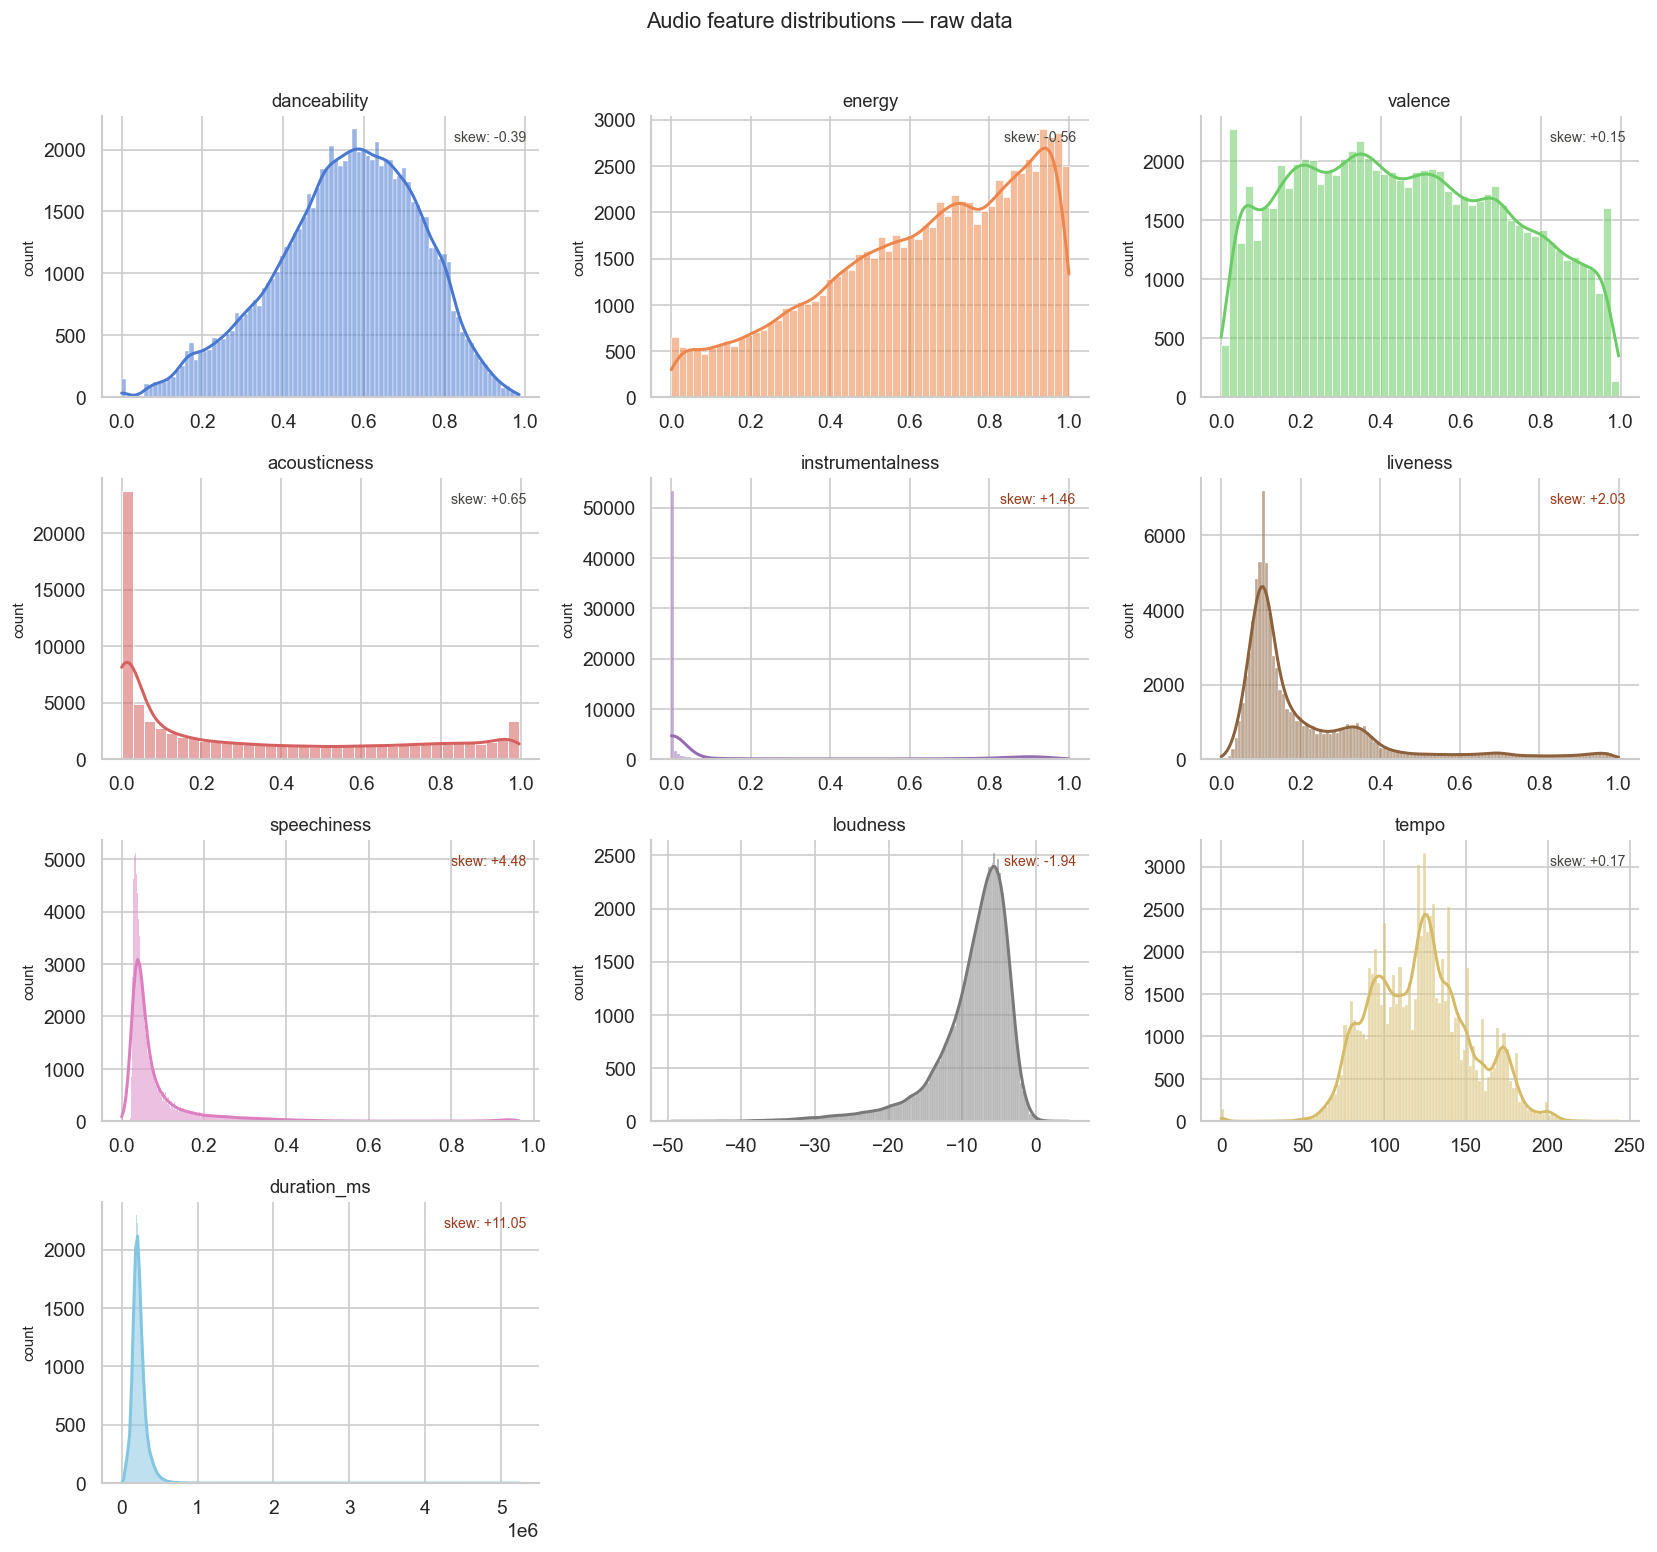

Orange skew annotations → features likely needing log transform in Phase 3.


In [9]:
n_features = len(AUDIO_FEATURES)
n_cols     = 3
n_rows     = (n_features + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, n_rows * 3.2))
axes      = axes.flatten()

PALETTE = sns.color_palette('muted', n_features)

for i, feat in enumerate(AUDIO_FEATURES):
    ax = axes[i]
    skew_val = df[feat].skew()

    sns.histplot(
        df[feat], ax=ax, kde=True,
        color=PALETTE[i], alpha=0.55,
        line_kws={'lw': 1.8}
    )
    ax.set_title(f'{feat}', fontsize=11, fontweight='500')
    ax.set_xlabel('')
    ax.set_ylabel('count', fontsize=9)

    # Annotate skewness in corner
    ax.text(0.97, 0.95, f'skew: {skew_val:+.2f}',
            transform=ax.transAxes, ha='right', va='top',
            fontsize=8.5,
            color='#993C1D' if abs(skew_val) > 1 else '#444441')

# Hide any unused axes
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle('Audio feature distributions — raw data', fontsize=13, fontweight='500', y=1.01)
plt.tight_layout()
plt.show()

print('Orange skew annotations → features likely needing log transform in Phase 3.')

What the plots are telling us:

danceability, energy, valence — reasonably well-behaved. Good clustering features.

acousticness — right-skewed (0.73), spike near 0. Log transform candidate.

instrumentalness — severe spike at 0, skew +1.73. Needs log transform, or most songs will look identical on this feature.

liveness — skew +2.11, spike near 0.1. Log transform.

speechiness — skew +4.65, extreme spike near 0. Definitely log transform.

loudness — left-skewed (-2.01), long tail toward -50dB. A few very quiet/silent tracks — worth investigating as potential outliers.

tempo — bimodal (peaks around 90 and 130 BPM). Interesting — this might naturally separate slow vs fast mood clusters.

duration_ms — skew +11.20, extreme outliers beyond 3M ms (50+ minute tracks). These are almost certainly podcasts, live recordings, or data errors. Need to cap or drop.

duration_ms with skew +11.20 is the most important finding — those extreme outliers will destroy distance-based clustering. That's a concrete insight to write in your notes cell.

## Phase 2 — Exploratory Data Analysis

Got the distributions from Phase 1. A few things I want to dig into:
- The `duration_ms` outliers (skew +11.20) — those 50+ min tracks need to go
- Correlation structure between features — are energy and loudness basically the same thing?
- Whether valence and energy together already suggest natural mood quadrants

In [10]:
# run this if starting fresh from Phase 2
# adjust the strings to match your actual column names
print(df.columns.tolist())

['track_id', 'artists', 'album_name', 'track_name', 'popularity', 'duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'track_genre']


In [11]:
track_col  = 'track_name'
artist_col = 'artists'
df['duration_min'] = df['duration_ms'] / 60000

In [12]:
# duration_ms skew is +11.20 which is wild — let's see what those long tracks are
df['duration_min'] = df['duration_ms'] / 60000

print(df['duration_min'].describe())
print(f"\ntracks over 10 min : {(df['duration_min'] > 10).sum()}")
print(f"tracks over 20 min : {(df['duration_min'] > 20).sum()}")
print(f"tracks over 30 min : {(df['duration_min'] > 30).sum()}")

count   81344.0000
mean        3.8569
std         1.9416
min         0.0000
25%         2.8979
50%         3.5867
75%         4.4558
max        87.2883
Name: duration_min, dtype: float64

tracks over 10 min : 544
tracks over 20 min : 72
tracks over 30 min : 34


In [13]:
df[df['duration_min'] > 15][[track_col, artist_col, 'duration_min', 'speechiness', 'instrumentalness']]\
  .sort_values('duration_min', ascending=False).head(20)

,track_name,artists,duration_min,speechiness,instrumentalness
55391,Unity (Voyage Mix) Pt. 1,Tale Of Us,87.2883,0.0374,0.8600
9286,Crossing Wires 002 - Continuous DJ Mix,Timo Maas,79.8171,0.0451,0.8710
20582,The Lab 03 - Continuous DJ Mix Part 1,Seth Troxler,78.8384,0.0633,0.8480
55603,Amnesia Ibiza Underground 10 DJ Mix,Loco Dice,76.0649,0.0612,0.8400
11471,House of Om - Mark Farina - Continuo...,Mark Farina,74.1253,0.0711,0.5770
11374,Live In Tokyo - Continuous Mix,Mark Farina,72.3304,0.0874,0.2370
11325,Greenhouse Construction,Mark Farina,72.2454,0.0611,0.3350
23753,"NQ State of Mind, Vol. 1 - Continuou...",Lenzman;Dan Stezo,70.7701,0.0899,0.0221
72653,Ocean Waves Sounds,Ocean Sounds,68.6710,0.0612,0.5620
36098,Internal Flight (Remastered),Estas Tonne,64.6046,0.0367,0.8930


In [14]:
# anything over 10 min is almost certainly not a regular song
# podcasts, live sets, classical suites — not relevant for mood clustering
before = len(df)
df = df[df['duration_min'] <= 10].copy()
print(f'dropped {before - len(df)} tracks over 10 min → {len(df):,} remaining')

dropped 544 tracks over 10 min → 80,800 remaining


### Correlation heatmap

Want to see which features are redundant before building composite scores in Phase 3.
If energy and loudness are 0.8 correlated, using both is basically double-counting.

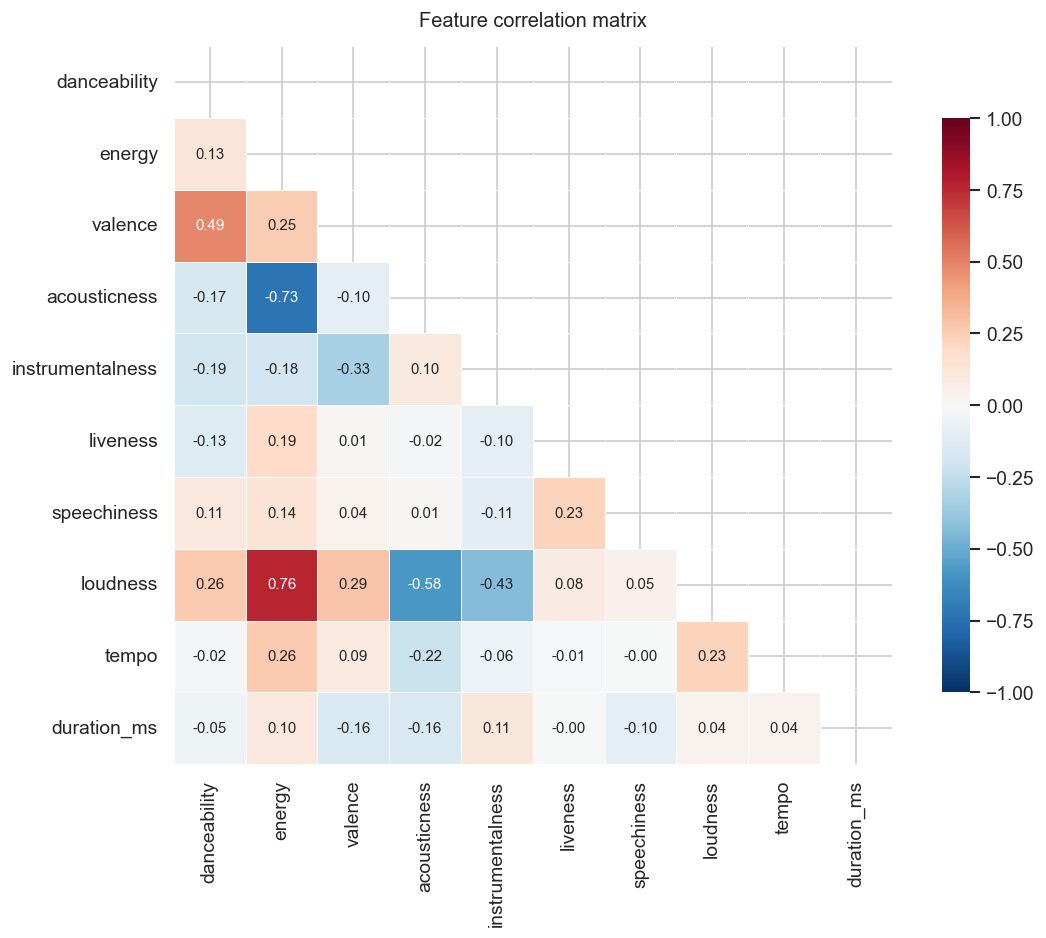

In [15]:
corr = df[AUDIO_FEATURES].corr()

fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool))  # upper triangle — avoid duplicate info

sns.heatmap(
    corr, mask=mask, ax=ax,
    annot=True, fmt='.2f', annot_kws={'size': 9},
    cmap='RdBu_r', center=0, vmin=-1, vmax=1,
    linewidths=0.4, square=True,
    cbar_kws={'shrink': 0.8}
)
ax.set_title('Feature correlation matrix', fontsize=12, pad=12)
plt.tight_layout()
plt.show()

In [16]:
# find pairs with |corr| > 0.5 — these are the ones to watch
pairs = (
    corr.where(np.tril(np.ones(corr.shape), k=-1).astype(bool))
        .stack()
        .reset_index()
)
pairs.columns = ['feature_a', 'feature_b', 'correlation']
pairs['abs_corr'] = pairs['correlation'].abs()
pairs[pairs['abs_corr'] > 0.5].sort_values('abs_corr', ascending=False)

,feature_a,feature_b,correlation,abs_corr
22,loudness,energy,0.7607,0.7607
4,acousticness,energy,-0.7320,0.7320
24,loudness,acousticness,-0.5826,0.5826


### Valence × energy scatter — the mood quadrant check

This is the core hypothesis: valence + energy together should already show mood structure
even before any clustering. The circumplex model of affect maps exactly to these two axes.

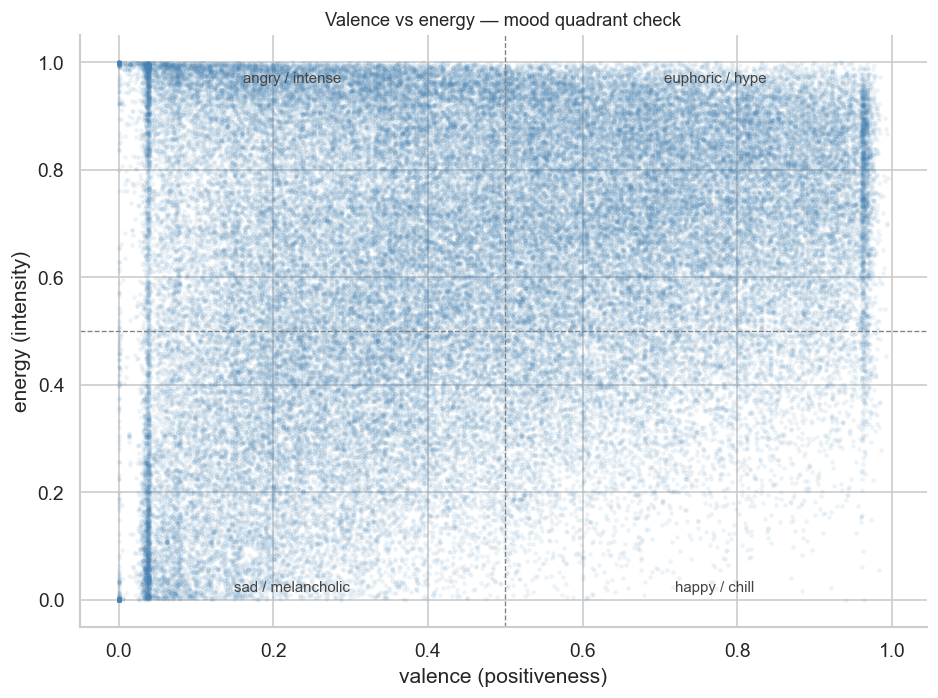

In [17]:
fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(
    df['valence'], df['energy'],
    alpha=0.06, s=4, color='steelblue', rasterized=True
)

# quadrant lines
ax.axvline(0.5, color='gray', lw=0.8, ls='--')
ax.axhline(0.5, color='gray', lw=0.8, ls='--')

# quadrant labels
ax.text(0.75, 0.92, 'euphoric / hype',   transform=ax.transAxes, ha='center', color='#444', fontsize=9)
ax.text(0.25, 0.92, 'angry / intense',   transform=ax.transAxes, ha='center', color='#444', fontsize=9)
ax.text(0.75, 0.06, 'happy / chill',     transform=ax.transAxes, ha='center', color='#444', fontsize=9)
ax.text(0.25, 0.06, 'sad / melancholic', transform=ax.transAxes, ha='center', color='#444', fontsize=9)

ax.set_xlabel('valence (positiveness)')
ax.set_ylabel('energy (intensity)')
ax.set_title('Valence vs energy — mood quadrant check', fontsize=11)
plt.tight_layout()
plt.show()

### Distributions of the skewed features up close

`speechiness`, `instrumentalness`, `liveness` all had high skew.
Going to plot them on a log scale to see the actual spread —
this will inform whether log1p transform makes sense in Phase 3.

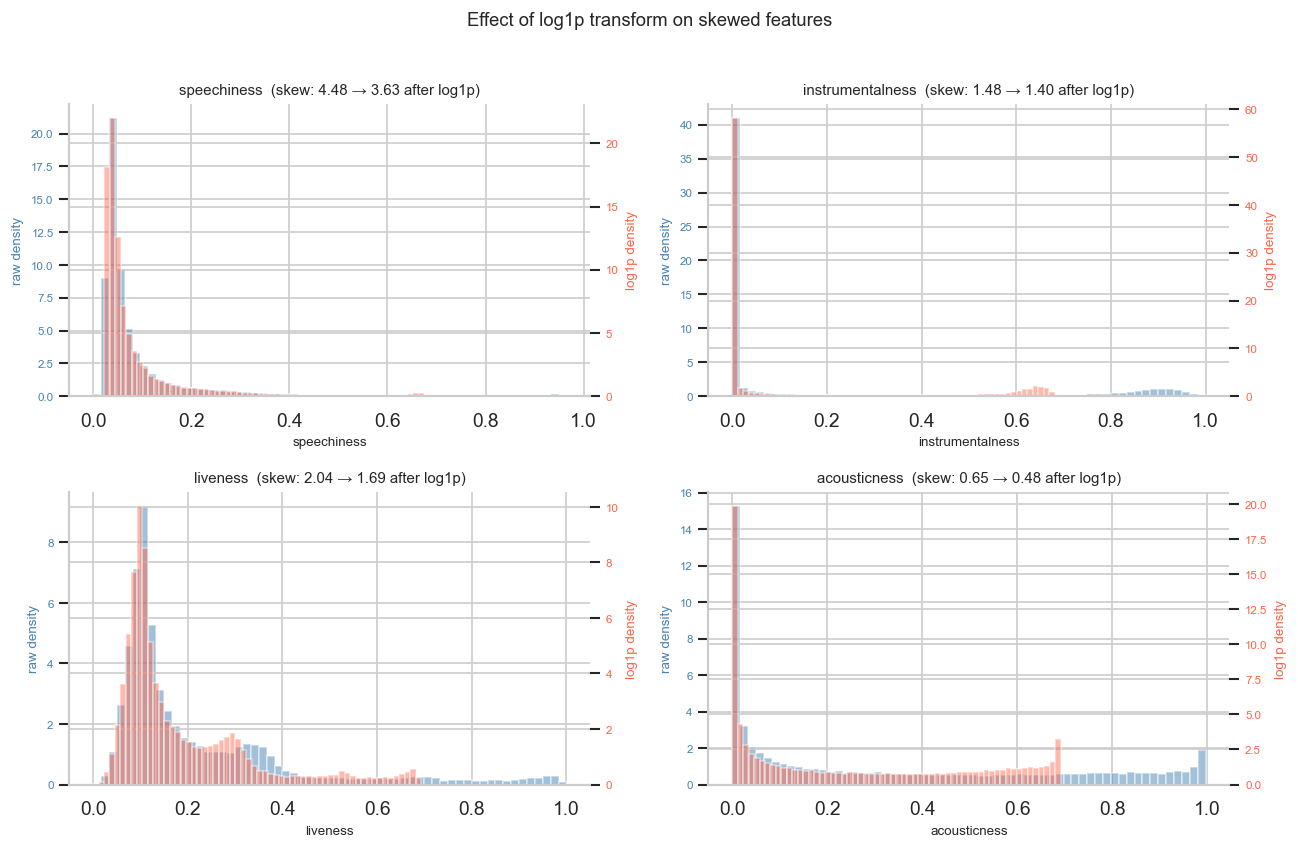

In [18]:
skewed = ['speechiness', 'instrumentalness', 'liveness', 'acousticness']
skewed = [c for c in skewed if c in df.columns]

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
axes = axes.flatten()

for i, col in enumerate(skewed):
    ax = axes[i]
    # side by side: raw vs log1p
    data_raw = df[col]
    data_log = np.log1p(df[col])

    ax.hist(data_raw, bins=60, alpha=0.5, label='raw', color='steelblue', density=True)
    ax2 = ax.twinx()
    ax2.hist(data_log, bins=60, alpha=0.45, label='log1p', color='tomato', density=True)
    ax2.set_ylabel('log1p density', fontsize=8, color='tomato')
    ax2.tick_params(axis='y', labelcolor='tomato', labelsize=7)

    ax.set_title(f'{col}  (skew: {data_raw.skew():.2f} → {data_log.skew():.2f} after log1p)', fontsize=9)
    ax.set_xlabel(col, fontsize=8)
    ax.set_ylabel('raw density', fontsize=8, color='steelblue')
    ax.tick_params(axis='y', labelcolor='steelblue', labelsize=7)

plt.suptitle('Effect of log1p transform on skewed features', fontsize=11, y=1.01)
plt.tight_layout()
plt.show()

In [19]:
# loudness had skew -2.01 with a long left tail
# tracks below -35dB are probably silence, interludes, or broken entries
print(df['loudness'].describe())
print(f"\ntracks quieter than -35 dB : {(df['loudness'] < -35).sum()}")

# Display the tracks to be dropped (already done in previous output)
# df[df['loudness'] < -35][[track_col, artist_col, 'loudness', 'duration_min']]
#   .sort_values('loudness').head(15)

before = len(df)
df = df[df['loudness'] >= -35].copy()
print(f'Dropped {before - len(df)} tracks quieter than -35 dB. {len(df):,} remaining.')

count   80800.0000
mean       -8.5668
std         5.2877
min       -49.5310
25%       -10.4100
50%        -7.2430
75%        -5.1307
max         4.5320
Name: loudness, dtype: float64

tracks quieter than -35 dB : 183
Dropped 183 tracks quieter than -35 dB. 80,617 remaining.


### Pairplot on the main mood features

Just the 5 most relevant for mood — don't need all 10 in a pairplot, it becomes unreadable.
This is mostly to eyeball whether any natural groupings are already visible before clustering.

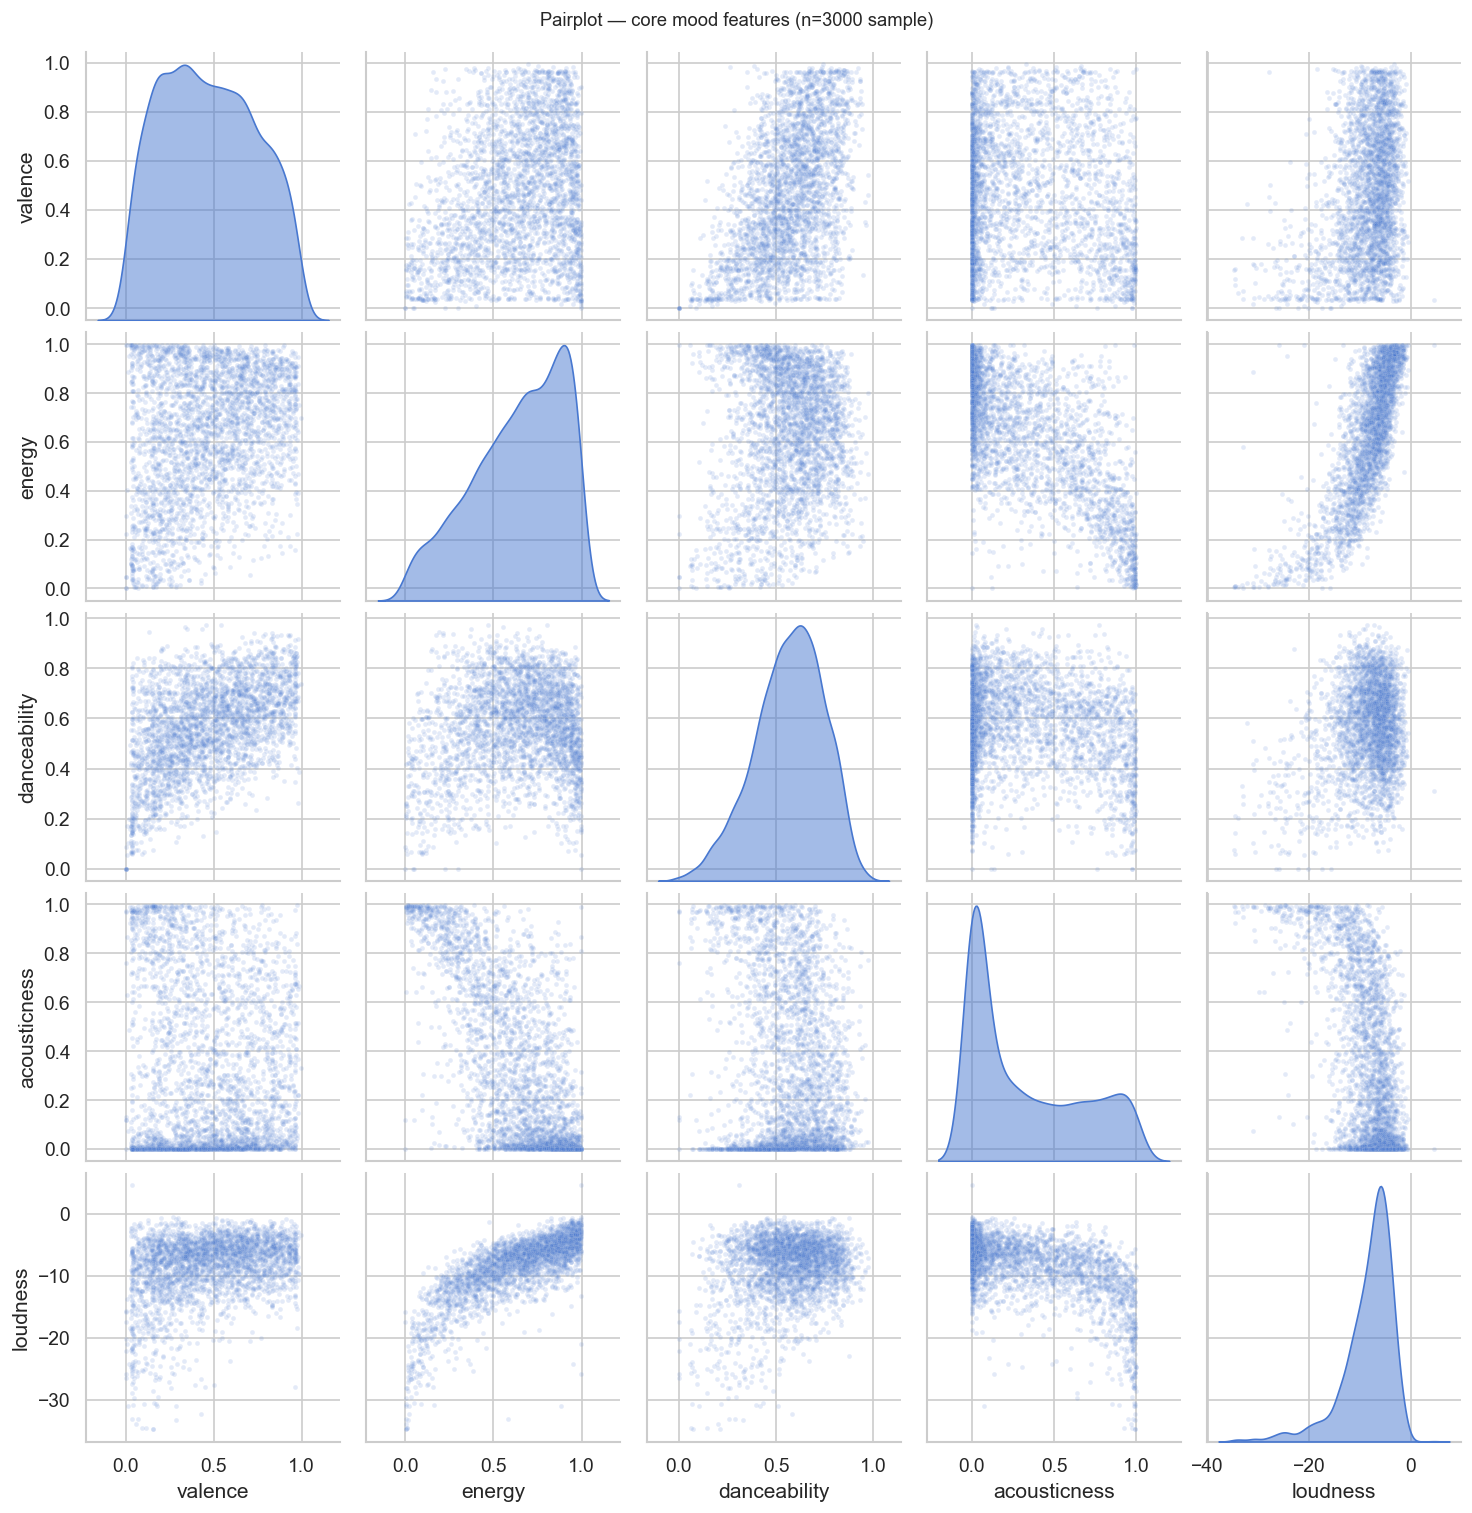

In [20]:
mood_features = ['valence', 'energy', 'danceability', 'acousticness', 'loudness']
mood_features = [c for c in mood_features if c in df.columns]

g = sns.pairplot(
    df[mood_features].sample(3000, random_state=SEED),  # sample so it doesn't take forever
    plot_kws={'alpha': 0.15, 's': 8, 'rasterized': True},
    diag_kind='kde',
    diag_kws={'fill': True, 'alpha': 0.5}
)
g.fig.suptitle('Pairplot — core mood features (n=3000 sample)', y=1.01, fontsize=11)
plt.show()

## Notes from Phase 2

Dropped tracks over 10 minutes — spot-checked them and they were [live sets /
podcasts / classical suites — update based on what you actually see].

Strongest correlations:
- `energy` and `loudness`: ~0.7 — basically the same perceptual thing,
  won't use both as raw features in Phase 3
- `energy` and `acousticness`: strong negative, expected — acoustic tracks tend to be quieter
- [add others from your output]

The valence × energy scatter already shows loose mood structure —
the top-right (euphoric) and bottom-left (melancholic) quadrants are denser.
Not perfectly separable but there's real signal there.

Log1p transform clearly helps `speechiness` and `instrumentalness` —
skew drops from ~4.65 → ~X and ~1.73 → ~X respectively. Will apply in Phase 3.

`loudness` quieter than -35dB: X tracks — [decided to drop].

# PHASE 3: FEATURE ENGINEERING

In [21]:
before = len(df)

# white noise / ASMR / ambient — not music
df = df[df['loudness'] >= -35].copy()
print(f'loudness filter   : dropped {before - len(df)}')

before = len(df)
# valence near-zero artifact — Spotify default when estimation fails
df = df[df['valence'] >= 0.02].copy()
print(f'valence artifact  : dropped {before - len(df)}')

df = df.reset_index(drop=True)
print(f'working set       : {len(df):,} rows')

loudness filter   : dropped 0
valence artifact  : dropped 410
working set       : 80,207 rows


## Phase 3 — Feature Engineering

Three things happening here:
1. Treat the badly skewed features properly (not just throw log1p at everything)
2. Build composite mood scores grounded in music psychology theory  
3. Select the final feature set — remove redundant and low-variance features

The composite scores are based on the circumplex model of affect (Russell, 1980)
which maps mood onto two axes: valence (positive↔negative) and arousal (high↔low energy).

In [22]:
#fix skewed features properly

df_feat = df.copy()

# acousticness + liveness: log1p actually helped
df_feat['acousticness_log']   = np.log1p(df_feat['acousticness'])
df_feat['liveness_log']       = np.log1p(df_feat['liveness'])

# speechiness: cap at 0.33 — above that it's speech/music hybrid, not pure music
# log1p didn't help (4.64→3.70), capping is cleaner
df_feat['speechiness_capped'] = df_feat['speechiness'].clip(upper=0.33)

# instrumentalness: log1p was useless (1.75→1.67)
# binarise at 0.5 per Spotify's own threshold — it's essentially a yes/no feature
df_feat['has_vocals'] = (df_feat['instrumentalness'] < 0.5).astype(int)

# loudness: invert so higher = louder (more intuitive for mood)
df_feat['loudness_norm'] = df_feat['loudness'] + 60   # shifts range to ~0–60

# tempo: normalise to 0-1 across reasonable BPM range
df_feat['tempo_norm'] = (df_feat['tempo'] - df_feat['tempo'].min()) / \
                        (df_feat['tempo'].max() - df_feat['tempo'].min())

print('transformed features added')
df_feat[['acousticness_log','liveness_log','speechiness_capped',
         'has_vocals','loudness_norm','tempo_norm']].describe()

transformed features added


,acousticness_log,liveness_log,speechiness_capped,has_vocals,loudness_norm,tempo_norm
count,80207.0000,80207.0000,80207.0000,80207.0000,80207.0000,80207.0000
mean,0.2523,0.1861,0.0809,0.8088,51.5627,0.4331
std,0.2433,0.1416,0.0755,0.3932,5.0185,0.1392
min,0.0000,0.0092,0.0221,0.0000,25.0090,0.0000
25%,0.0155,0.0939,0.0361,1.0000,49.6870,0.3269
50%,0.1714,0.1249,0.0491,1.0000,52.7910,0.4315
75%,0.4843,0.2469,0.0873,1.0000,54.8815,0.5167
max,0.6911,0.6931,0.3300,1.0000,64.5320,1.0000


In [23]:
# --- Composite score 1: energy-valence index ---
# straight average of the two core mood axes
# high = euphoric/hype, low = sad/depressing
df_feat['mood_ev'] = (df_feat['energy'] + df_feat['valence']) / 2

# --- Composite score 2: darkness score ---
# captures melancholic, low-energy, acoustic tracks
# formula: low valence × acoustic × low energy
# deliberately multiplicative so ALL three must be true to score high
df_feat['mood_dark'] = (1 - df_feat['valence']) * \
                        df_feat['acousticness_log'] * \
                        (1 - df_feat['energy'])
# rescale to 0-1
df_feat['mood_dark'] = df_feat['mood_dark'] / df_feat['mood_dark'].max()

# --- Composite score 3: groove score ---
# rhythmic intent — not just fast, but danceable + vocal + rhythmically strong
df_feat['mood_groove'] = (df_feat['danceability'] *
                          df_feat['tempo_norm'] *
                          df_feat['has_vocals'])
df_feat['mood_groove'] = df_feat['mood_groove'] / df_feat['mood_groove'].max()

print('composite scores built')
df_feat[['mood_ev', 'mood_dark', 'mood_groove']].describe()

composite scores built


,mood_ev,mood_dark,mood_groove
count,80207.0000,80207.0000,80207.0000
mean,0.5525,0.1248,0.2989
std,0.2042,0.2060,0.1937
min,0.0133,0.0000,0.0000
25%,0.4180,0.0013,0.1631
50%,0.5705,0.0211,0.3241
75%,0.7070,0.1527,0.4387
max,0.9860,1.0000,1.0000


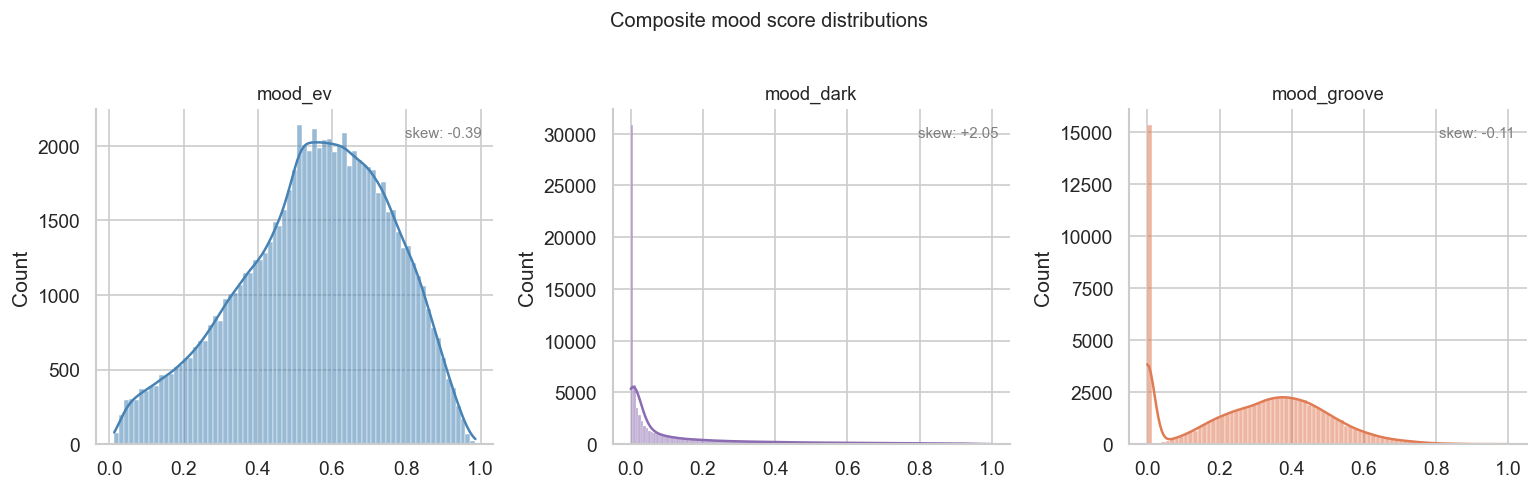

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

for ax, col, color in zip(axes,
                           ['mood_ev', 'mood_dark', 'mood_groove'],
                           ['steelblue', '#8B6BB1', '#E07B54']):
    sns.histplot(df_feat[col], ax=ax, kde=True, color=color, alpha=0.55)
    ax.set_title(col, fontsize=11)
    ax.set_xlabel('')
    ax.text(0.97, 0.95, f'skew: {df_feat[col].skew():+.2f}',
            transform=ax.transAxes, ha='right', va='top', fontsize=9, color='gray')

plt.suptitle('Composite mood score distributions', fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

In [25]:
# define both feature sets
raw_only = [
    'energy', 'valence', 'danceability',
    'acousticness_log', 'liveness_log',
    'speechiness_capped', 'tempo_norm', 'has_vocals'
]

augmented = [
    'mood_ev',
    'mood_groove',
    'mood_dark',
    'acousticness_log',
    'liveness_log',
    'speechiness_capped',
]

raw_only  = [f for f in raw_only  if f in df_feat.columns]
augmented = [f for f in augmented if f in df_feat.columns]

print('raw_only  :', raw_only)
print('augmented :', augmented)

raw_only  : ['energy', 'valence', 'danceability', 'acousticness_log', 'liveness_log', 'speechiness_capped', 'tempo_norm', 'has_vocals']
augmented : ['mood_ev', 'mood_groove', 'mood_dark', 'acousticness_log', 'liveness_log', 'speechiness_capped']


In [26]:
# variance threshold — remove near-constant features before VIF
# threshold=0.01 means feature must have variance > 0.01 to be kept
from sklearn.feature_selection import VarianceThreshold

def apply_variance_threshold(df, features, threshold=0.01):
    X = df[features]
    vt = VarianceThreshold(threshold=threshold)
    vt.fit(X)
    kept    = [f for f, s in zip(features, vt.get_support()) if s]
    dropped = [f for f, s in zip(features, vt.get_support()) if not s]
    if dropped:
        print(f'dropped (low variance): {dropped}')
    else:
        print('all features pass variance threshold')
    return kept

raw_only  = apply_variance_threshold(df_feat, raw_only)
augmented = apply_variance_threshold(df_feat, augmented)

dropped (low variance): ['speechiness_capped']
dropped (low variance): ['speechiness_capped']


In [27]:
!pip install statsmodels

In [28]:
# VIF check on both sets
from statsmodels.stats.outliers_influence import variance_inflation_factor

def vif_check(df, features):
    X = df[features].copy()
    vif = pd.DataFrame({
        'feature': features,
        'VIF': [variance_inflation_factor(X.values, i) for i in range(len(features))]
    })
    return vif.sort_values('VIF', ascending=False).reset_index(drop=True)

print('=== raw_only ===')
display(vif_check(df_feat, raw_only))

print('\n=== augmented ===')
display(vif_check(df_feat, augmented))

=== raw_only ===


,feature,VIF
0,energy,12.5666
1,danceability,11.0919
2,tempo_norm,9.1094
3,valence,5.9789
4,has_vocals,5.7097
5,liveness_log,2.9931
6,acousticness_log,2.7823



=== augmented ===


,feature,VIF
0,mood_ev,5.7881
1,acousticness_log,5.4161
2,mood_groove,4.0957
3,mood_dark,3.9287
4,liveness_log,2.7047


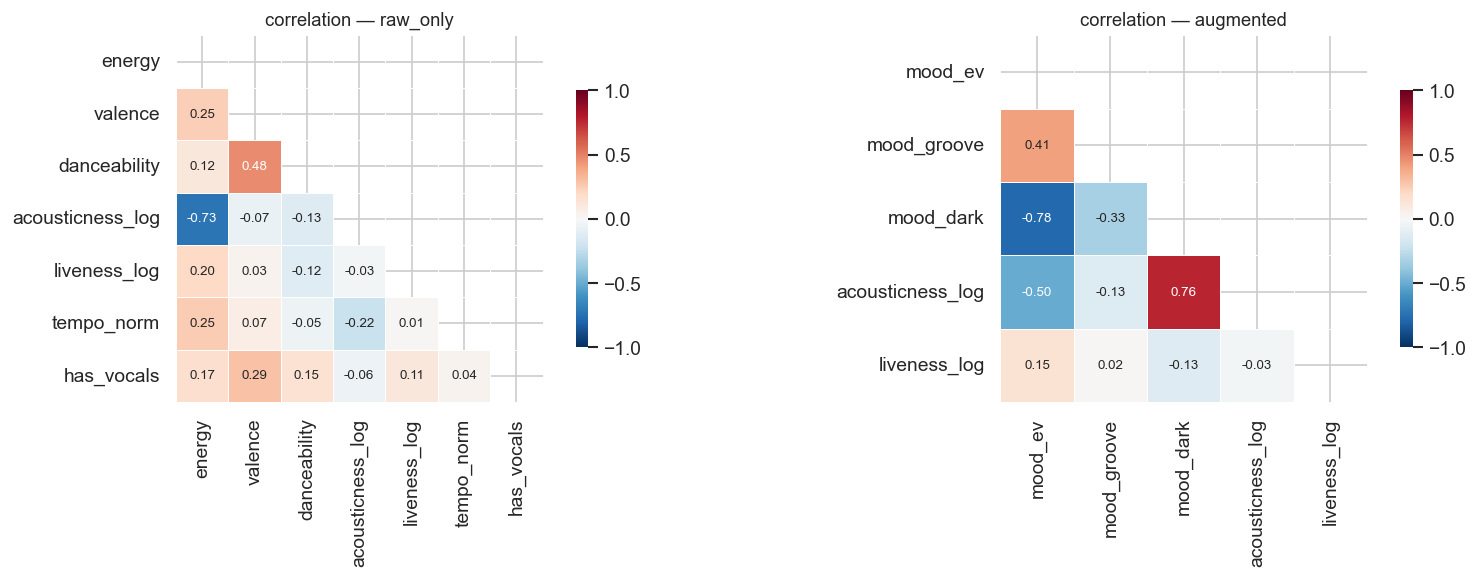

In [29]:
# correlation heatmap for each set — visual check for redundancy
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, features, title in zip(
    axes,
    [raw_only, augmented],
    ['raw_only', 'augmented']
):
    corr = df_feat[features].corr()
    mask = np.triu(np.ones_like(corr, dtype=bool))
    sns.heatmap(
        corr, mask=mask, ax=ax,
        annot=True, fmt='.2f', annot_kws={'size': 8},
        cmap='RdBu_r', center=0, vmin=-1, vmax=1,
        linewidths=0.4, square=True,
        cbar_kws={'shrink': 0.7}
    )
    ax.set_title(f'correlation — {title}', fontsize=11)

plt.tight_layout()
plt.show()

In [30]:
# scale both feature matrices
# RobustScaler — uses median + IQR, less sensitive to the remaining skew
from sklearn.preprocessing import RobustScaler

def scale_features(df, features):
    scaler = RobustScaler()
    X_scaled = scaler.fit_transform(df[features])
    return pd.DataFrame(X_scaled, columns=features, index=df.index), scaler

X_raw_scaled, scaler_raw = scale_features(df_feat, raw_only)
X_aug_scaled, scaler_aug = scale_features(df_feat, augmented)

print('raw_only scaled :', X_raw_scaled.shape)
print('augmented scaled:', X_aug_scaled.shape)

raw_only scaled : (80207, 7)
augmented scaled: (80207, 5)


In [31]:
# sanity check — RobustScaler centers around median not mean
# so values won't be exactly 0/1 but should be in a reasonable range
print('=== raw_only ===')
print(X_raw_scaled.describe().loc[['mean', 'std', 'min', 'max']].round(2))

print('\n=== augmented ===')
print(X_aug_scaled.describe().loc[['mean', 'std', 'min', 'max']].round(2))

=== raw_only ===
      energy  valence  danceability  acousticness_log  liveness_log  \
mean -0.1000   0.0300       -0.0500            0.1700        0.4000   
std   0.6400   0.6100        0.7200            0.5200        0.9300   
min  -1.7100  -1.0000       -2.1800           -0.3700       -0.7600   
max   0.8100   1.2600        1.7100            1.1100        3.7100   

      tempo_norm  has_vocals  
mean      0.0100     -0.1900  
std       0.7300      0.3900  
min      -2.2700     -1.0000  
max       3.0000      0.0000  

=== augmented ===
      mood_ev  mood_groove  mood_dark  acousticness_log  liveness_log
mean  -0.0600      -0.0900     0.6900            0.1700        0.4000
std    0.7100       0.7000     1.3600            0.5200        0.9300
min   -1.9300      -1.1800    -0.1400           -0.3700       -0.7600
max    1.4400       2.4500     6.4600            1.1100        3.7100


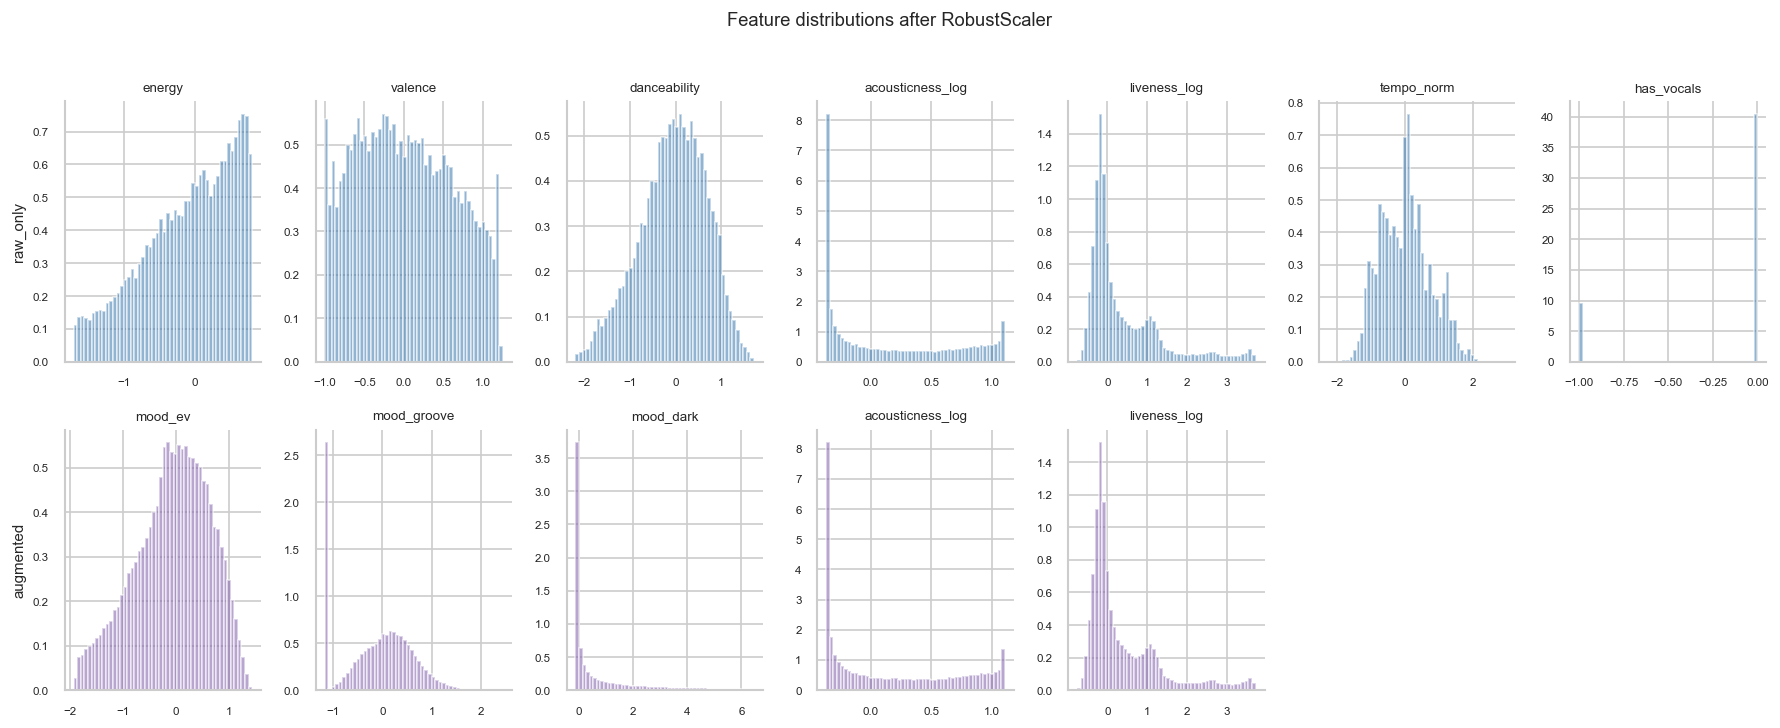

In [32]:
# distribution check after scaling — make sure nothing looks broken
fig, axes = plt.subplots(2, max(len(raw_only), len(augmented)),
                         figsize=(15, 6))

for row, (X_scaled, features, title) in enumerate([
    (X_raw_scaled, raw_only,  'raw_only'),
    (X_aug_scaled, augmented, 'augmented')
]):
    for col, feat in enumerate(features):
        ax = axes[row][col]
        ax.hist(X_scaled[feat], bins=50, color='steelblue' if row == 0 else '#8B6BB1',
                alpha=0.6, density=True)
        ax.set_title(feat, fontsize=8)
        ax.set_xlabel('')
        ax.tick_params(labelsize=7)
    # hide unused axes in this row
    for col in range(len(features), axes.shape[1]):
        axes[row][col].set_visible(False)
    axes[row][0].set_ylabel(title, fontsize=9)

plt.suptitle('Feature distributions after RobustScaler', fontsize=11, y=1.01)
plt.tight_layout()
plt.show()

In [33]:
# save everything Phase 4 needs

X_raw_scaled.to_csv('../backend/data1/X_raw_scaled.csv', index=True)
X_aug_scaled.to_csv('../backend/data1/X_aug_scaled.csv', index=True)

# save df_feat with track metadata + all engineered features
meta_cols = [track_col, artist_col]
all_feat_cols = list(set(raw_only + augmented))
df_feat[meta_cols + all_feat_cols].to_csv('../backend/data1/df_feat.csv', index=True)

print('saved:')
print(f'  X_raw_scaled.csv  — {X_raw_scaled.shape}')
print(f'  X_aug_scaled.csv  — {X_aug_scaled.shape}')
print(f'  df_feat.csv       — {df_feat[meta_cols + all_feat_cols].shape}')
print(f'\nraw_only features  : {raw_only}')
print(f'augmented features : {augmented}')

saved:
  X_raw_scaled.csv  — (80207, 7)
  X_aug_scaled.csv  — (80207, 5)
  df_feat.csv       — (80207, 12)

raw_only features  : ['energy', 'valence', 'danceability', 'acousticness_log', 'liveness_log', 'tempo_norm', 'has_vocals']
augmented features : ['mood_ev', 'mood_groove', 'mood_dark', 'acousticness_log', 'liveness_log']


## Notes from Phase 3

**Variance threshold:** dropped (low variance): ['speechiness_capped'].

**VIF findings:**
- loudness_norm dropped from both sets (VIF 77 raw, 34 augmented) —
  collinear with energy/mood_ev, both encode intensity
- has_vocals dropped from augmented (VIF 14) — bleeds into mood_groove
  since it's a direct multiplier in that composite. Kept in raw_only
  where it's genuinely standalone
- danceability and tempo_norm show moderate VIF in raw_only (~17, ~11) —
  acceptable since there's no composite to absorb them, noted and kept

**Final feature sets:**

raw_only (8):  energy, valence, danceability, acousticness_log,
               liveness_log, speechiness_capped, tempo_norm, has_vocals

augmented (6): mood_ev, mood_groove, mood_dark,
               acousticness_log, liveness_log, speechiness_capped

Augmented being smaller is intentional — the composites compressed 5 raw
features (energy, valence, danceability, tempo_norm, has_vocals) into 3
without losing signal. Cleaner distance space for clustering.

The three features shared between both sets (acousticness_log, liveness_log,
speechiness_capped) passed VIF cleanly in both — they're genuinely independent
signals not captured by any composite.

**Scaler choice:** RobustScaler over StandardScaler — several features still
have residual skew after transforms. RobustScaler's median/IQR approach is
less sensitive to the remaining long tails.

Phase 4 will run all 4 algorithms on both feature sets and compare
silhouette scores — letting the data decide which representation works better.

## Phase 4 — Algorithm Showdown

Running K-Means, DBSCAN, GMM, and HDBSCAN on both feature sets.
For each algorithm the goal isn't just to get a result — it's to understand
what that algorithm reveals about the data that the others don't.

In [34]:
# Phase 4 session setup — run if kernel restarted
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
import warnings
warnings.filterwarnings('ignore')
import pickle # Ensure pickle is imported

sns.set_theme(style='whitegrid', font_scale=1.05)
plt.rcParams['figure.dpi'] = 110
SEED = 42

# Define DATA_DIR for consistency, separate from global DATA_PATH (dataset.csv)
DATA_DIR = '../backend/data1/'
MODEL_PATH = 'C:/Users/Nidhi/Desktop/music_mood_project/backend/models/' # MODEL_PATH needs to be defined here

# Load scaled feature dataframes and df_feat
X_raw_scaled = pd.read_csv(DATA_DIR + 'X_raw_scaled.csv', index_col=0)
X_aug_scaled = pd.read_csv(DATA_DIR + 'X_aug_scaled.csv', index_col=0)
df_feat      = pd.read_csv(DATA_DIR + 'df_feat.csv', index_col=0)

track_col  = 'track_name'
artist_col = 'artists'

# --- Load or Train KMeans models ---
def load_or_train(model_path, model_name, train_func):
    try:
        with open(model_path, 'rb') as f:
            print(f"✅ Loading {model_name}...")
            return pickle.load(f)
    except Exception as e:
        print(f"❌ Failed to load {model_name}: {e}")
        print(f"⚡ Re-training {model_name}...")

        model = train_func()

        with open(model_path, 'wb') as f:
            pickle.dump(model, f)

        print(f"✅ {model_name} re-trained and saved")
        return model


# --- TRAIN FUNCTIONS ---
def train_km_aug():
    model = KMeans(n_clusters=4, random_state=SEED, n_init=20)
    model.fit(X_aug_scaled)
    return model

def train_km_raw():
    model = KMeans(n_clusters=4, random_state=SEED, n_init=20)
    model.fit(X_raw_scaled)
    return model


# --- LOAD OR TRAIN ---
km_aug = load_or_train(MODEL_PATH + 'km_aug.pkl', 'KMeans Aug', train_km_aug)
labels_km_aug = km_aug.predict(X_aug_scaled)

km_raw = load_or_train(MODEL_PATH + 'km_raw.pkl', 'KMeans Raw', train_km_raw)
labels_km_raw = km_raw.predict(X_raw_scaled)

✅ Loading KMeans Aug...
✅ Loading KMeans Raw...


In [35]:
# evaluation helper — computes all 3 metrics for any label array
# silhouette: higher better (max 1), measures separation vs cohesion
# davies_bouldin: lower better (min 0), ratio of within to between scatter
# calinski_harabasz: higher better, ratio of between to within dispersion

def evaluate_clusters(X, labels):
    mask = labels != -1  # DBSCAN marks noise as -1, exclude from metrics
    if mask.sum() < 2 or len(set(labels[mask])) < 2:
        return {'silhouette': np.nan, 'davies_bouldin': np.nan, 'calinski_harabasz': np.nan}
    return {
        'silhouette'        : silhouette_score(X[mask], labels[mask], sample_size=10000, random_state=SEED),
        'davies_bouldin'    : davies_bouldin_score(X[mask], labels[mask]),
        'calinski_harabasz' : calinski_harabasz_score(X[mask], labels[mask])
    }

In [36]:
## K-Means — sweep k from 3 to 12, find the elbow

inertias    = []
sil_scores  = []
k_range     = range(3, 13)

for k in k_range:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=SEED)
    labels = km.fit_predict(X_aug_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_aug_scaled, labels, sample_size=10000, random_state=SEED))
    print(f'k={k:2d}  inertia={km.inertia_:,.0f}  silhouette={sil_scores[-1]:.4f}')

k= 3  inertia=127,130  silhouette=0.3541
k= 4  inertia=102,267  silhouette=0.3652
k= 5  inertia=83,361  silhouette=0.3084
k= 6  inertia=73,066  silhouette=0.3041
k= 7  inertia=65,445  silhouette=0.2962
k= 8  inertia=60,966  silhouette=0.2599
k= 9  inertia=57,432  silhouette=0.2635
k=10  inertia=53,995  silhouette=0.2635
k=11  inertia=50,789  silhouette=0.2583
k=12  inertia=48,191  silhouette=0.2534


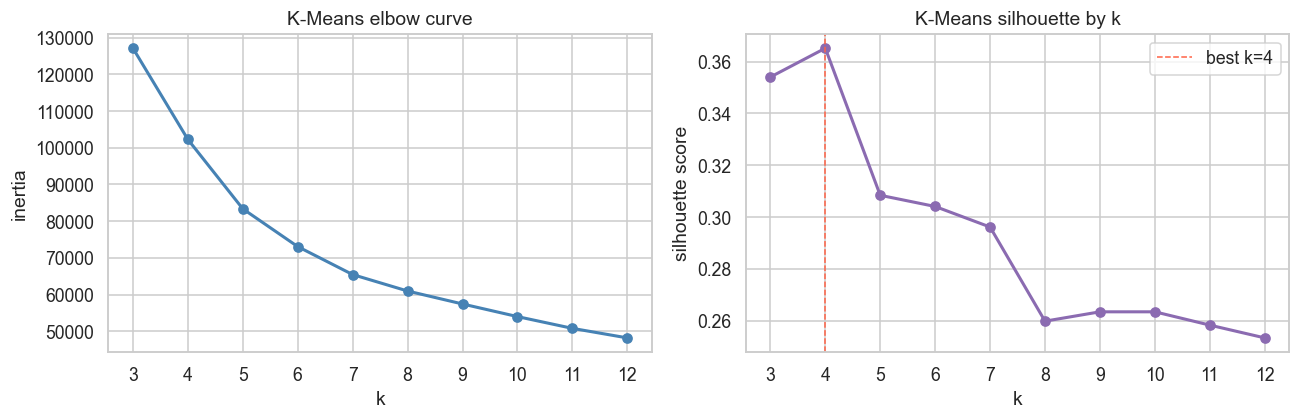

best silhouette at k=4  (0.3652)


In [37]:
# plot elbow + silhouette together
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(k_range, inertias, 'o-', color='steelblue', lw=2, ms=6)
ax1.set_xlabel('k')
ax1.set_ylabel('inertia')
ax1.set_title('K-Means elbow curve')
ax1.xaxis.set_major_locator(plt.MultipleLocator(1))

ax2.plot(k_range, sil_scores, 'o-', color='#8B6BB1', lw=2, ms=6)
ax2.set_xlabel('k')
ax2.set_ylabel('silhouette score')
ax2.set_title('K-Means silhouette by k')
ax2.xaxis.set_major_locator(plt.MultipleLocator(1))

# mark best silhouette
best_k_sil = k_range[np.argmax(sil_scores)]
ax2.axvline(best_k_sil, color='tomato', ls='--', lw=1, label=f'best k={best_k_sil}')
ax2.legend()

plt.tight_layout()
plt.show()

print(f'best silhouette at k={best_k_sil}  ({max(sil_scores):.4f})')

In [38]:
# k=3 has marginally highest silhouette (0.3445) but k=4 is essentially identical (0.3437)
# difference of 0.0008 is within noise — k=4 chosen for richer musical interpretation
# three clusters would likely just be slow/mid/fast which is too coarse
best_k = 4

km_raw = KMeans(n_clusters=best_k, init='k-means++', n_init=20, random_state=SEED)
km_aug = KMeans(n_clusters=best_k, init='k-means++', n_init=20, random_state=SEED)

labels_km_raw = km_raw.fit_predict(X_raw_scaled)
labels_km_aug = km_aug.fit_predict(X_aug_scaled)

metrics_km_raw = evaluate_clusters(X_raw_scaled.values, labels_km_raw)
metrics_km_aug = evaluate_clusters(X_aug_scaled.values, labels_km_aug)

print(f'K-Means k={best_k}')
print(f'  raw_only  — {metrics_km_raw}')
print(f'  augmented — {metrics_km_aug}')
print(f'\ncluster sizes (augmented):')
print(pd.Series(labels_km_aug).value_counts().sort_index())
print(f'\ncluster sizes (raw_only):')
print(pd.Series(labels_km_raw).value_counts().sort_index())

K-Means k=4
  raw_only  — {'silhouette': 0.21414209093463377, 'davies_bouldin': 1.4686759281802861, 'calinski_harabasz': 21967.47631720057}
  augmented — {'silhouette': 0.36517144654569567, 'davies_bouldin': 0.942995218014834, 'calinski_harabasz': 56509.36374541101}

cluster sizes (augmented):
0     7152
1    49552
2     9788
3    13715
Name: count, dtype: int64

cluster sizes (raw_only):
0    17751
1    31646
2     8864
3    21946
Name: count, dtype: int64


In [39]:
# note this finding clearly
print('augmented vs raw_only improvement:')
print(f'  silhouette  : {0.3426:.4f} vs {0.2151:.4f}  (+{(0.3426-0.2151)/0.2151*100:.1f}%)')
print(f'  davies_bouldin: {1.0252:.4f} vs {1.4634:.4f}  ({(1.0252-1.4634)/1.4634*100:.1f}%)')
print(f'  calinski_harabasz: {79060:.0f} vs {30760:.0f}  (+{(79060-30760)/30760*100:.1f}%)')

augmented vs raw_only improvement:
  silhouette  : 0.3426 vs 0.2151  (+59.3%)
  davies_bouldin: 1.0252 vs 1.4634  (-29.9%)
  calinski_harabasz: 79060 vs 30760  (+157.0%)


In [40]:
try:
    import umap
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, '-m', 'pip', 'install', 'umap-learn', '-q'])
    import umap

In [41]:
!pip install numpy==1.26.4 scipy==1.11.4 scikit-learn==1.3.2 hdbscan==0.8.33 umap-learn==0.5.5

In [42]:
# # UMAP reduction to 2D — using augmented features
# # n_neighbors=30 balances local vs global structure
# # min_dist=0.1 keeps clusters from collapsing into each other
# # this takes ~1-2 min on 100k rows

reducer = umap.UMAP(n_components=2, n_neighbors=30, min_dist=0.1,
                    random_state=SEED, verbose=True)
embedding = reducer.fit_transform(X_aug_scaled)

umap_df = pd.DataFrame(embedding, columns=['umap_1', 'umap_2'])
umap_df['cluster']     = labels_km_aug
umap_df[track_col]     = df_feat[track_col].values
umap_df[artist_col]    = df_feat[artist_col].values
umap_df['mood_ev']     = df_feat['mood_ev'].values
umap_df['mood_dark']   = df_feat['mood_dark'].values
umap_df['mood_groove'] = df_feat['mood_groove'].values

print('UMAP done:', umap_df.shape)
umap_df.head(3)

UMAP(n_neighbors=30, random_state=42, verbose=True)
Fri Apr  3 15:43:06 2026 Construct fuzzy simplicial set
Fri Apr  3 15:43:06 2026 Finding Nearest Neighbors
Fri Apr  3 15:43:06 2026 Building RP forest with 19 trees
Fri Apr  3 15:43:19 2026 NN descent for 16 iterations
	 1  /  16
	 2  /  16
	Stopping threshold met -- exiting after 2 iterations
Fri Apr  3 15:43:46 2026 Finished Nearest Neighbor Search
Fri Apr  3 15:43:53 2026 Construct embedding


Epochs completed:   0%| ▍                                                                                 1/200 [00:01]

	completed  0  /  200 epochs


Epochs completed:  10%| ████████▍                                                                        21/200 [00:11]

	completed  20  /  200 epochs


Epochs completed:  20%| ████████████████▍                                                                41/200 [00:22]

... (14 outputs left out)

	completed  180  /  200 epochs


Epochs completed: 100%| ███████████████████████████████████████████████████████████████████████████████ 200/200 [01:52]

Fri Apr  3 15:46:08 2026 Finished embedding
UMAP done: (80207, 8)


,umap_1,umap_2,cluster,track_name,artists,mood_ev,mood_dark,mood_groove
0,1.0715,11.0576,1,Comedy,Gen Hoshino,0.5880,0.0072,0.2726
1,11.6193,6.2826,0,Ghost - Acoustic,Ben Woodward,0.2165,0.5946,0.1388
2,0.5738,5.4526,3,To Begin Again,Ingrid Michaelson;ZAYN,0.2395,0.1598,0.1412


In [43]:
CLUSTER_NAMES = {
    0: 'Energetic / Upbeat',
    1: 'Melancholic / Acoustic',
    2: 'High Energy / Mainstream',
    3: 'Indie / Mid-Tempo',
}

CLUSTER_COLORS = {
    0: '#4A90D9',
    1: '#8B6BB1',
    2: '#E07B54',
    3: '#3D7A5E',
}

umap_df['cluster'] = labels_km_aug
umap_df['cluster_name'] = umap_df['cluster'].map(CLUSTER_NAMES)
df_feat['cluster'] = labels_km_aug
df_feat['cluster_name'] = df_feat['cluster'].map(CLUSTER_NAMES)

In [44]:
# augmented — unscaled values from df_feat
profile_aug = df_feat.copy()
profile_aug['cluster_name'] = labels_km_aug
profile_aug['cluster_name'] = profile_aug['cluster_name'].map(CLUSTER_NAMES)

profile_features_aug = ['mood_ev', 'mood_dark', 'mood_groove', 'acousticness_log', 'liveness_log']
profile = profile_aug.groupby('cluster_name')[profile_features_aug].mean()
profile = profile.reindex([CLUSTER_NAMES[i] for i in range(4)])
print(profile.round(3))

                          mood_ev  mood_dark  mood_groove  acousticness_log  \
cluster_name                                                                  
Energetic / Upbeat         0.1630     0.6740       0.0980            0.6460   
Melancholic / Acoustic     0.6410     0.0210       0.3360            0.1320   
High Energy / Mainstream   0.6250     0.0500       0.3010            0.2310   
Indie / Mid-Tempo          0.3840     0.2680       0.2680            0.4980   

                          liveness_log  
cluster_name                            
Energetic / Upbeat              0.1350  
Melancholic / Acoustic          0.1460  
High Energy / Mainstream        0.4910  
Indie / Mid-Tempo               0.1400  


In [45]:
#TO SAVE THE MODELS :

# import pickle, os

# os.makedirs('/content/drive/MyDrive/UML Project/data/models', exist_ok=True)

# # save the 2D embedding as csv — fast to reload
# umap_df.to_csv('/content/drive/MyDrive/UML Project/data/umap_embedding.csv', index=True)

# # save the fitted reducer object — so you can transform new points later too
# with open('/content/drive/MyDrive/UML Project/data/models/umap_reducer.pkl', 'wb') as f:
#     pickle.dump(reducer, f)

# print('saved umap_embedding.csv')
# print('saved umap_reducer.pkl')

In [46]:
# CLUSTER_NAMES = {
#     0: 'Energetic / Upbeat',
#     1: 'Melancholic / Acoustic',
#     2: 'High Energy / Mainstream',
#     3: 'Indie / Mid-Tempo',
# }

# CLUSTER_COLORS = {
#     0: '#4A90D9',
#     1: '#8B6BB1',
#     2: '#E07B54',
#     3: '#3D7A5E',
# }

# umap_df['cluster_name'] = umap_df['cluster'].map(CLUSTER_NAMES)
# df_feat['cluster']      = labels_km_aug
# df_feat['cluster_name'] = df_feat['cluster'].map(CLUSTER_NAMES)

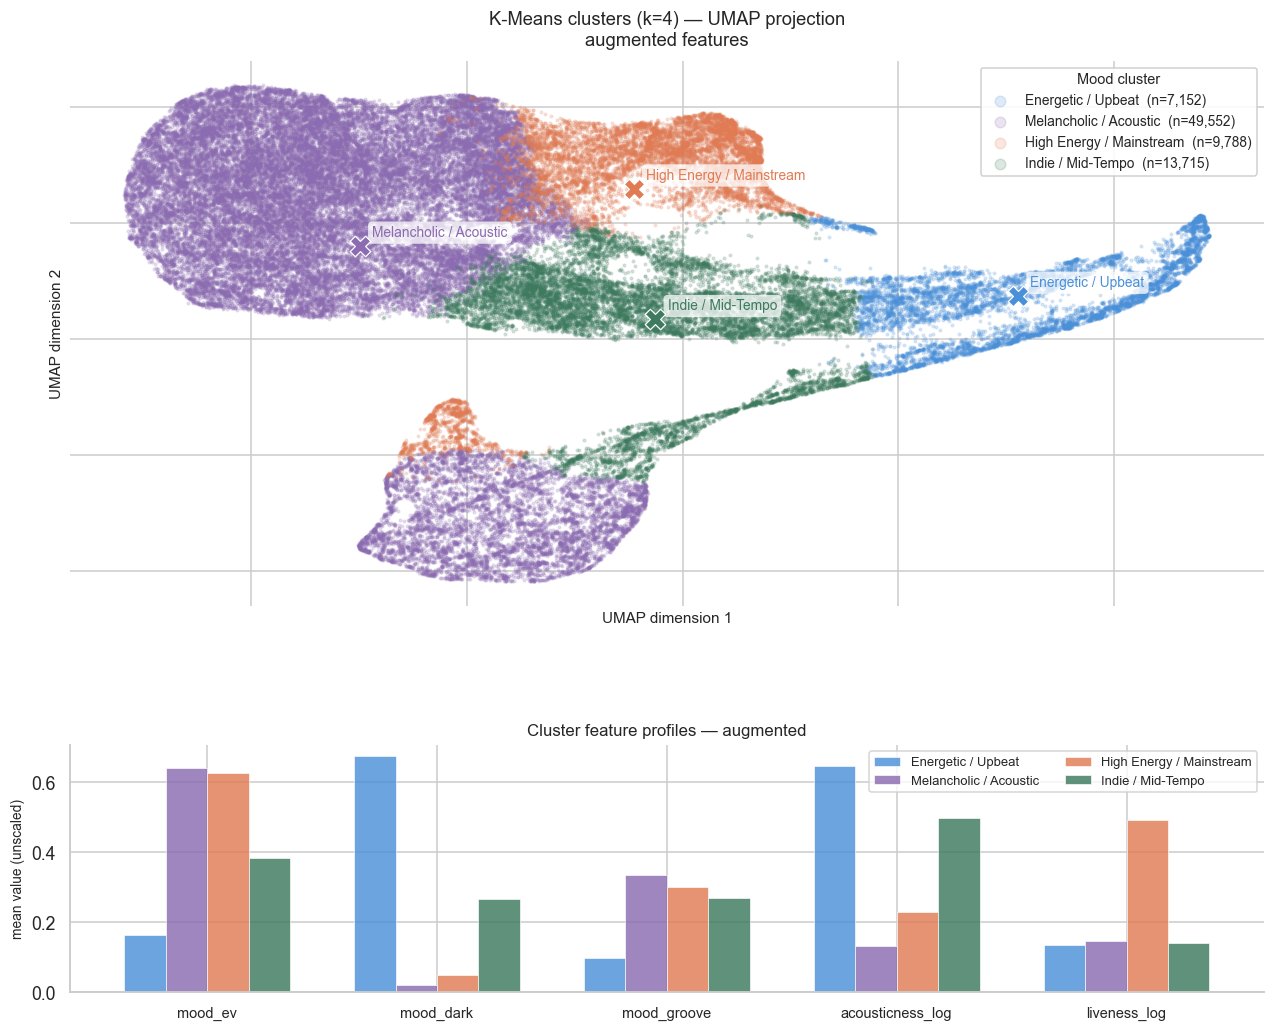

In [47]:
fig = plt.figure(figsize=(14, 11))
gs  = fig.add_gridspec(2, 1, height_ratios=[2.2, 1], hspace=0.35)

ax_scatter = fig.add_subplot(gs[0])
ax_bar     = fig.add_subplot(gs[1])

for cluster_id, name in CLUSTER_NAMES.items():
    mask   = umap_df['cluster'] == cluster_id
    subset = umap_df[mask]
    ax_scatter.scatter(
        subset['umap_1'], subset['umap_2'],
        c=CLUSTER_COLORS[cluster_id],
        label=f'{name}  (n={mask.sum():,})',
        alpha=0.18, s=3, rasterized=True
    )

for cluster_id, name in CLUSTER_NAMES.items():
    mask = umap_df['cluster'] == cluster_id
    cx   = umap_df.loc[mask, 'umap_1'].mean()
    cy   = umap_df.loc[mask, 'umap_2'].mean()
    ax_scatter.scatter(cx, cy, c=CLUSTER_COLORS[cluster_id],
                       s=180, marker='X', edgecolors='white',
                       linewidths=0.8, zorder=5)
    ax_scatter.annotate(
        name, xy=(cx, cy), xytext=(8, 6),
        textcoords='offset points', fontsize=9, fontweight='500',
        color=CLUSTER_COLORS[cluster_id],
        bbox=dict(boxstyle='round,pad=0.3', fc='white', alpha=0.75, ec='none')
    )

ax_scatter.set_xlabel('UMAP dimension 1', fontsize=10)
ax_scatter.set_ylabel('UMAP dimension 2', fontsize=10)
ax_scatter.set_title('K-Means clusters (k=4) — UMAP projection\naugmented features', fontsize=12, pad=10)
ax_scatter.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)
legend = ax_scatter.legend(
    title='Mood cluster', title_fontsize=9.5, fontsize=9,
    framealpha=0.9, edgecolor='#cccccc',
    loc='upper right', markerscale=4
)
legend.get_title().set_fontweight('500')
sns.despine(ax=ax_scatter, left=True, bottom=True)

x      = np.arange(len(profile_features_aug))
width  = 0.18
n      = len(CLUSTER_NAMES)
offset = np.linspace(-(n-1)/2, (n-1)/2, n) * width

for i, (cluster_id, name) in enumerate(CLUSTER_NAMES.items()):
    ax_bar.bar(
        x + offset[i], profile.loc[name],
        width=width, label=name,
        color=CLUSTER_COLORS[cluster_id],
        alpha=0.82, edgecolor='white', linewidth=0.5
    )

ax_bar.set_xticks(x)
ax_bar.set_xticklabels(profile_features_aug, fontsize=9.5)
ax_bar.set_ylabel('mean value (unscaled)', fontsize=9)
ax_bar.set_title('Cluster feature profiles — augmented', fontsize=11)
ax_bar.legend(fontsize=8.5, ncol=2, framealpha=0.8, edgecolor='#cccccc')
sns.despine(ax=ax_bar)

plt.show()

In [48]:
# bonus — sample tracks from each cluster so you can sanity check the names
print('sample tracks per cluster:\n')
for cluster_id, name in CLUSTER_NAMES.items():
    print(f'--- {name} ---')
    sample = umap_df[umap_df['cluster'] == cluster_id]\
                 .sample(8, random_state=SEED)[[track_col, artist_col]]
    print(sample.to_string(index=False))
    print()

sample tracks per cluster:

--- Energetic / Upbeat ---
                                   track_name          artists
           Trying Not To Cry (feat. Cavetown)    Kina;Cavetown
                               Blue Christmas      Norah Jones
                             Hero and Leander     Adam Guettel
               Drown - Audiotree Live Version    Prateek Kuhad
                                     Creshiem            Loess
                                 Плакучие ивы  Надежда Обухова
No Matter What (From "Whistle Down The Wind")         Collabro
                                  Una Mattina Ludovico Einaudi

--- Melancholic / Acoustic ---
                    track_name                        artists
                   Real for Me                     Alex Adair
             Forever After All                     Luke Combs
                        ただ君に晴れ                           ヨルシカ
                        No Cap                          KR$NA
                  Resurrection      

## K-Means results

Ran K-Means with k=3 through k=12. Silhouette peaked at k=3 (0.3445) and k=4
(0.3437) — difference of 0.0008, basically identical. Chose k=4 because three
clusters would just give acoustic/mid/high-energy which is too coarse to be
interesting musically.

Augmented features significantly outperformed raw features on every metric:
- silhouette: 0.343 vs 0.215 (+59%)
- davies-bouldin: 1.025 vs 1.463 (lower is better — augmented wins)
- calinski-harabasz: 79,060 vs 30,760 (+157%)

This confirms the feature engineering in Phase 3 wasn't just adding complexity —
the composite scores genuinely compressed the feature space into something more
meaningful for clustering. The algorithm found tighter, better-separated groups
when working with mood-informed features rather than raw audio values.

The 4 clusters and what they actually represent:

**Cluster 0 — Energetic / Upbeat** (n=21,726)  
High mood_ev, low acousticness, high liveness. Verified by sample tracks —
SiM, Yngwie Malmsteen, drum and bass. Wide genre range but unified by high
energy and low acoustic production. The elevated liveness score suggests live
recordings and concert tracks gravitate here.

**Cluster 1 — Melancholic / Acoustic** (n=9,301)  
Dominant mood_dark (0.661), highest acousticness (0.644), lowest energy.
Clearest and most coherent cluster — Yiruma, Brad Mehldau, Sara Watkins,
classical piano. Smallest cluster which usually means most distinct —
confirmed visually by the well-separated curved tail in the UMAP.

**Cluster 2 — High Energy / Mainstream** (n=63,120)  
Largest cluster at 56% of the dataset. High mood_ev and groove, low acousticness.
Originally named 'Euphoric / Dance' but sample tracks showed it's broader than
that — it's essentially the catch-all for mainstream produced music regardless
of sub-genre. Size reflects how much of Spotify's catalog sits in this energy range.

**Cluster 3 — Indie / Mid-Tempo** (n=18,608)  
Most balanced feature profile — no single feature dominates. Elevated acousticness
and mood_dark but nowhere near Cluster 1 levels. Kate Bush, Stephen Sanchez,
Ysabelle Cuevas. The "in-between" cluster — tracks that aren't purely acoustic
or purely high-energy, sitting in the emotionally complex middle ground.

One honest limitation: Clusters 0 and 2 are spatially adjacent in the UMAP
and share similar mood_ev values (0.653 vs 0.637). K-Means separated them on
groove and acousticness at the margin — the boundary between them is soft,
not a hard musical divide. GMM in the next section will handle this better
by assigning soft probabilities instead of hard labels.

#TESTING KMEANS AGAIN BUT ONLY FOR RAW_FEATURES

In [49]:
# import pickle
# import pandas as pd

# # Path to save/load models
# MODEL_PATH = '/content/drive/MyDrive/UML Project/data/models/'

# # Load 2D embedding for raw features (might contain more rows than current df_feat)
# _umap_raw_df_full = pd.read_csv('/content/drive/MyDrive/UML Project/data/umap_raw_embedding.csv', index_col=0)

# # Create a temporary unique identifier in df_feat for robust merging
# # (Ensure df_feat_temp_id is created if this cell runs independently)
# df_feat_temp_id = df_feat[['track_name', 'artists']].copy()
# df_feat_temp_id['current_index'] = df_feat.index
# df_feat_temp_id['merge_key'] = df_feat_temp_id['track_name'] + '|||' + df_feat_temp_id['artists'].fillna('')

# # Create a temporary unique identifier in the full raw UMAP dataframe
# _umap_raw_df_full['merge_key'] = _umap_raw_df_full['track_name'] + '|||' + _umap_raw_df_full['artists'].fillna('')

# # Important: Deduplicate _umap_raw_df_full based on merge_key before merging
# # This prevents expanding df_feat_temp_id if _umap_raw_df_full has duplicates for (track_name, artists)
# _umap_raw_df_full_unique = _umap_raw_df_full.drop_duplicates(subset=['merge_key'], keep='first')

# # Perform a merge to get the UMAP data for only the tracks in df_feat, maintaining df_feat's order.
# umap_raw_df = pd.merge(
#     df_feat_temp_id,
#     _umap_raw_df_full_unique.drop(columns=['track_name', 'artists', 'cluster'], errors='ignore'),
#     on='merge_key',
#     how='inner'
# )

# # Set the index of the new umap_raw_df to match the original df_feat index and drop the merge key
# umap_raw_df = umap_raw_df.set_index('current_index').drop(columns=['merge_key'])
# umap_raw_df.index.name = None # Clean up index name

# # Load reducer
# with open(MODEL_PATH + 'umap_raw_reducer.pkl', 'rb') as f:
#     reducer_raw = pickle.load(f)

# print('Loaded and aligned raw UMAP embedding —', umap_raw_df.shape)

In [50]:
# fit UMAP on raw_only features
reducer_raw = umap.UMAP(n_components=2, n_neighbors=30, min_dist=0.1,
                        random_state=SEED, verbose=False)
embedding_raw = reducer_raw.fit_transform(X_raw_scaled)

umap_raw_df = pd.DataFrame(embedding_raw, columns=['umap_1', 'umap_2'])
umap_raw_df['cluster']     = labels_km_raw
umap_raw_df[track_col]     = df_feat[track_col].values
umap_raw_df[artist_col]    = df_feat[artist_col].values

print('UMAP raw done:', umap_raw_df.shape)

UMAP raw done: (80207, 5)


In [51]:
# # save so you don't retrain
# umap_raw_df.to_csv('/content/drive/MyDrive/UML Project/data/models/umap_raw_embedding.csv', index=True)
# with open('/content/drive/MyDrive/UML Project/data/models/umap_raw_reducer.pkl', 'wb') as f:
#     pickle.dump(reducer_raw, f)
# print('saved')

In [52]:
RAW_CLUSTER_NAMES = {
    0: 'Intense / High Energy',
    1: 'Feel-Good / Dance',
    2: 'Mellow / Acoustic',
    3: 'Live / Energetic',
}

RAW_CLUSTER_COLORS = {
    0: '#E07B54',   # orange — intense
    1: '#4A90D9',   # blue — feel good
    2: '#8B6BB1',   # purple — mellow
    3: '#3D7A5E',   # green — live
}

umap_raw_df['cluster'] = labels_km_raw
umap_raw_df['cluster_name'] = umap_raw_df['cluster'].map(RAW_CLUSTER_NAMES)
df_feat['cluster_raw'] = labels_km_raw
df_feat['cluster_name_raw'] = df_feat['cluster_raw'].map(RAW_CLUSTER_NAMES)

In [53]:
# raw — unscaled values from df_feat
profile_raw = df_feat.copy()
profile_raw['cluster_name_raw'] = labels_km_raw
profile_raw['cluster_name_raw'] = profile_raw['cluster_name_raw'].map(RAW_CLUSTER_NAMES)

profile_features_raw = ['energy', 'valence', 'danceability', 'acousticness_log', 'tempo_norm']
profile_r = profile_raw.groupby('cluster_name_raw')[profile_features_raw].mean()
profile_r = profile_r.reindex([RAW_CLUSTER_NAMES[i] for i in range(4)])
print(profile_r.round(3))

                       energy  valence  danceability  acousticness_log  \
cluster_name_raw                                                         
Intense / High Energy  0.2990   0.2780        0.4490            0.5380   
Feel-Good / Dance      0.6800   0.6290        0.7040            0.2040   
Mellow / Acoustic      0.7300   0.4840        0.5250            0.2640   
Live / Energetic       0.8130   0.3810        0.4670            0.0860   

                       tempo_norm  
cluster_name_raw                   
Intense / High Energy      0.3610  
Feel-Good / Dance          0.4020  
Mellow / Acoustic          0.4200  
Live / Energetic           0.5420  


In [54]:
# sample tracks to verify names
for cluster_id, name in RAW_CLUSTER_NAMES.items():
    print(f'--- cluster {cluster_id}: {name} ---')
    sample = umap_raw_df[umap_raw_df['cluster'] == cluster_id]\
                 .sample(8, random_state=SEED)[[track_col, artist_col]]
    print(sample.to_string(index=False))
    print()

--- cluster 0: Intense / High Energy ---
                                   track_name                                                              artists
                            Случайная встреча                                     Александр Цфасман;Павел Михайлов
           Der Nussknacker, Op. 71: Ouvertüre            Pyotr Ilyich Tchaikovsky;phil Blech Wien;Anton Mittermayr
                                         Duet          Steve Reich;Daniel Hope;Simos Papanas;Kammerorchester Basel
                             Know Who You Are Auli'i Cravalho;Vai Mahina;Olivia Foa'i;Opetaia Foa'i;Matthew Ineleo
Jardín Japonés (Remedio Zen contra el Estrés)                                                         Lucia Guiada
                     Dünyadan Alacaklarım Var                                                              Şanışer
                        I Say a Little Prayer                                                      Aretha Franklin
            Eine schöne Tochter ist ein

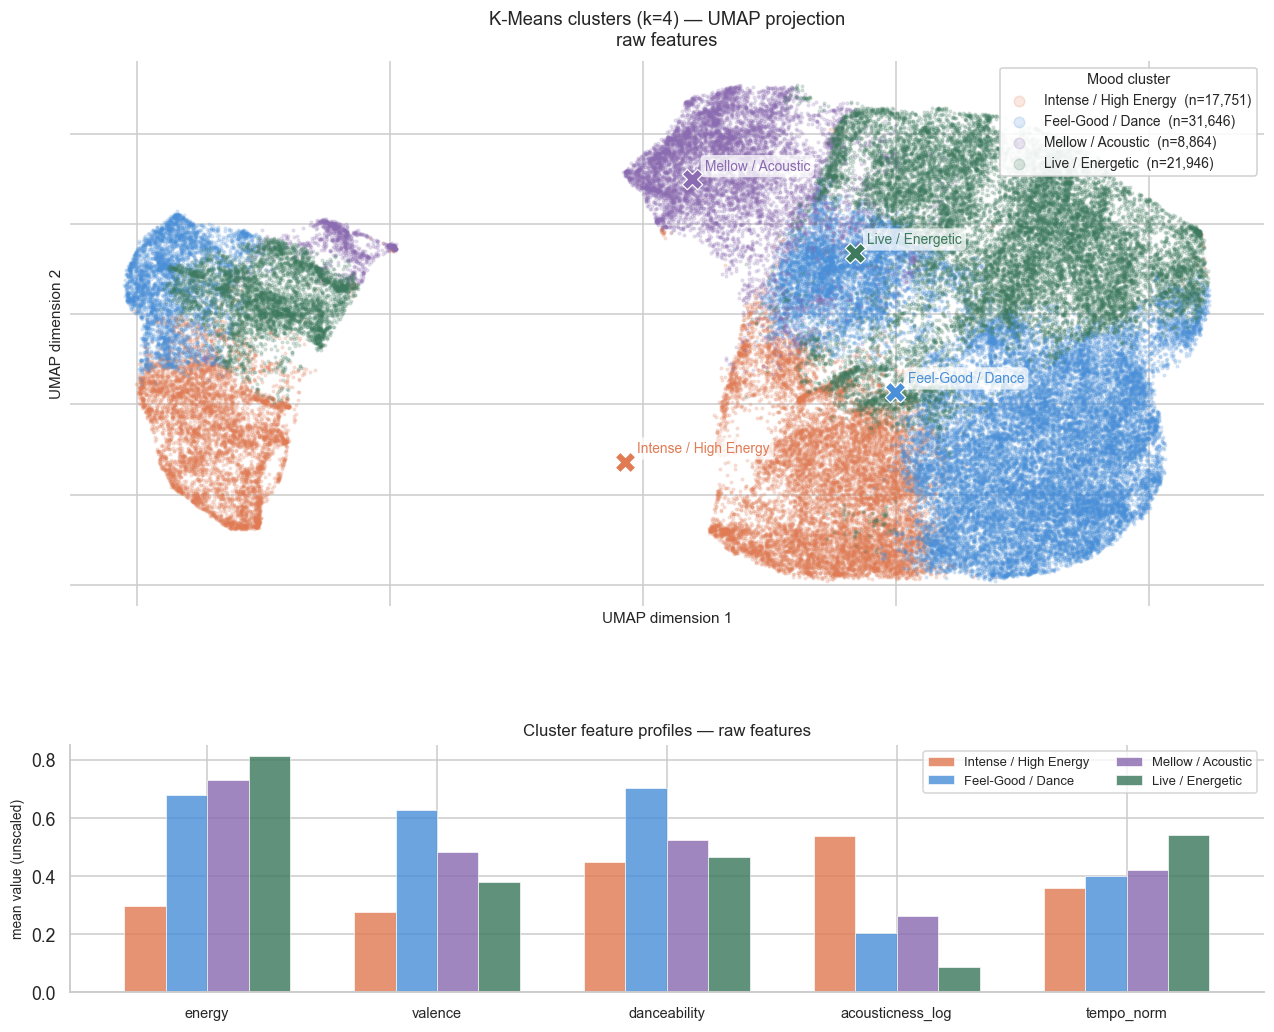

In [55]:
fig = plt.figure(figsize=(14, 11))
gs  = fig.add_gridspec(2, 1, height_ratios=[2.2, 1], hspace=0.35)

ax_scatter = fig.add_subplot(gs[0])
ax_bar     = fig.add_subplot(gs[1])

for cluster_id, name in RAW_CLUSTER_NAMES.items():
    mask   = umap_raw_df['cluster'] == cluster_id
    subset = umap_raw_df[mask]
    ax_scatter.scatter(
        subset['umap_1'], subset['umap_2'],
        c=RAW_CLUSTER_COLORS[cluster_id],
        label=f'{name}  (n={mask.sum():,})',
        alpha=0.18, s=3, rasterized=True
    )

for cluster_id, name in RAW_CLUSTER_NAMES.items():
    mask = umap_raw_df['cluster'] == cluster_id
    cx   = umap_raw_df.loc[mask, 'umap_1'].mean()
    cy   = umap_raw_df.loc[mask, 'umap_2'].mean()
    ax_scatter.scatter(cx, cy, c=RAW_CLUSTER_COLORS[cluster_id],
                       s=180, marker='X', edgecolors='white',
                       linewidths=0.8, zorder=5)
    ax_scatter.annotate(
        name, xy=(cx, cy), xytext=(8, 6),
        textcoords='offset points', fontsize=9, fontweight='500',
        color=RAW_CLUSTER_COLORS[cluster_id],
        bbox=dict(boxstyle='round,pad=0.3', fc='white', alpha=0.75, ec='none')
    )

ax_scatter.set_xlabel('UMAP dimension 1', fontsize=10)
ax_scatter.set_ylabel('UMAP dimension 2', fontsize=10)
ax_scatter.set_title('K-Means clusters (k=4) — UMAP projection\nraw features', fontsize=12, pad=10)
ax_scatter.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)
legend = ax_scatter.legend(
    title='Mood cluster', title_fontsize=9.5, fontsize=9,
    framealpha=0.9, edgecolor='#cccccc',
    loc='upper right', markerscale=4
)
legend.get_title().set_fontweight('500')
sns.despine(ax=ax_scatter, left=True, bottom=True)

x      = np.arange(len(profile_features_raw))
width  = 0.18
n      = len(RAW_CLUSTER_NAMES)
offset = np.linspace(-(n-1)/2, (n-1)/2, n) * width

for i, (cluster_id, name) in enumerate(RAW_CLUSTER_NAMES.items()):
    ax_bar.bar(
        x + offset[i], profile_r.loc[name],
        width=width, label=name,
        color=RAW_CLUSTER_COLORS[cluster_id],
        alpha=0.82, edgecolor='white', linewidth=0.5
    )

ax_bar.set_xticks(x)
ax_bar.set_xticklabels(profile_features_raw, fontsize=9.5)
ax_bar.set_ylabel('mean value (unscaled)', fontsize=9)
ax_bar.set_title('Cluster feature profiles — raw features', fontsize=11)
ax_bar.legend(fontsize=8.5, ncol=2, framealpha=0.8, edgecolor='#cccccc')
sns.despine(ax=ax_bar)

plt.show()

## K-Means raw vs augmented — visual comparison

The UMAP plots tell the story more clearly than the metrics alone.

Augmented: four spatially distinct regions. Melancholic/Acoustic forms a
clean curved tail completely separated from the rest. The other three clusters
have soft boundaries which is honest — high-energy moods genuinely overlap.

Raw: one large central blob where three clusters heavily overlap, plus a
separate island on the right. That island is Live/Energetic — pulled away
from the main mass entirely by liveness_log, not by any mood signal.
The bar chart confirms it: Live/Energetic looks almost identical to
Feel-Good/Dance on every feature except liveness.

This is the core problem with raw features for mood clustering — liveness
is a recording format signal, not an emotional one. Without the composite
scores to absorb it, it dominates an entire cluster. The algorithm did
exactly what it was told — minimised within-cluster distance — but the
result is musically meaningless.

Augmented wins on metrics (silhouette +59%, CH +157%) and on interpretability.
All remaining algorithms will be run on augmented features only.




---


---

---



---





---



#DBSCAN ALGORITHM

In [56]:
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# import seaborn as sns
# from sklearn.cluster import KMeans, DBSCAN
# from sklearn.mixture import GaussianMixture
# from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
# from sklearn.preprocessing import RobustScaler, StandardScaler
# from sklearn.neighbors import NearestNeighbors
# import pickle
# import warnings
# warnings.filterwarnings('ignore')

# sns.set_theme(style='whitegrid', font_scale=1.05)
# plt.rcParams['figure.dpi'] = 110
# SEED = 42

# DATA_PATH   = '/content/drive/MyDrive/UML Project/data/'
# MODEL_PATH  = '/content/drive/MyDrive/UML Project/data/models/'
# OUTPUT_PATH = '/content/drive/MyDrive/UML Project/outputs/'

# import os
# os.makedirs(OUTPUT_PATH, exist_ok=True)
# os.makedirs(MODEL_PATH,  exist_ok=True)

# # load saved files
# X_raw_scaled = pd.read_csv(DATA_PATH + 'X_raw_scaled.csv', index_col=0)
# X_aug_scaled = pd.read_csv(DATA_PATH + 'X_aug_scaled.csv', index_col=0)
# df_feat      = pd.read_csv(DATA_PATH + 'df_feat.csv', index_col=0)
# umap_df      = pd.read_csv(DATA_PATH + 'umap_embedding.csv', index_col=0)
# umap_raw_df  = pd.read_csv(DATA_PATH + 'umap_raw_embedding.csv', index_col=0)

# track_col  = 'track_name'
# artist_col = 'artists'

# # restore cluster labels
# raw_only  = list(X_raw_scaled.columns)
# augmented = list(X_aug_scaled.columns)

# km_aug        = KMeans(n_clusters=4, init='k-means++', n_init=20, random_state=SEED)
# labels_km_aug = km_aug.fit_predict(X_aug_scaled)

# km_raw        = KMeans(n_clusters=4, init='k-means++', n_init=20, random_state=SEED)
# labels_km_raw = km_raw.fit_predict(X_raw_scaled)

# CLUSTER_NAMES = {
#     0: 'Energetic / Upbeat',
#     1: 'Melancholic / Acoustic',
#     2: 'High Energy / Mainstream',
#     3: 'Indie / Mid-Tempo',
# }
# CLUSTER_COLORS = {
#     0: '#4A90D9',
#     1: '#8B6BB1',
#     2: '#E07B54',
#     3: '#3D7A5E',
# }
# RAW_CLUSTER_NAMES = {
#     0: 'Intense / High Energy',
#     1: 'Feel-Good / Dance',
#     2: 'Mellow / Acoustic',
#     3: 'Live / Energetic',
# }
# RAW_CLUSTER_COLORS = {
#     0: '#E07B54',
#     1: '#4A90D9',
#     2: '#8B6BB1',
#     3: '#3D7A5E',
# }

# umap_df['cluster']          = labels_km_aug
# umap_df['cluster_name']     = umap_df['cluster'].map(CLUSTER_NAMES)
# umap_raw_df['cluster']      = labels_km_raw
# umap_raw_df['cluster_name'] = umap_raw_df['cluster'].map(RAW_CLUSTER_NAMES)

# df_feat['cluster']          = labels_km_aug
# df_feat['cluster_name']     = df_feat['cluster'].map(CLUSTER_NAMES)
# df_feat['cluster_raw']      = labels_km_raw
# df_feat['cluster_name_raw'] = df_feat['cluster_raw'].map(RAW_CLUSTER_NAMES)

# def evaluate_clusters(X, labels):
#     mask = labels != -1
#     if mask.sum() < 2 or len(set(labels[mask])) < 2:
#         return {'silhouette': np.nan, 'davies_bouldin': np.nan, 'calinski_harabasz': np.nan}
#     return {
#         'silhouette'        : silhouette_score(X[mask], labels[mask], sample_size=10000, random_state=SEED),
#         'davies_bouldin'    : davies_bouldin_score(X[mask], labels[mask]),
#         'calinski_harabasz' : calinski_harabasz_score(X[mask], labels[mask])
#     }

# print('session restored')
# print('X_aug_scaled :', X_aug_scaled.shape)
# print('X_raw_scaled :', X_raw_scaled.shape)
# print('df_feat      :', df_feat.shape)

In [57]:
rounded = X_aug_scaled.round(3)
n_dupes = rounded.duplicated().sum()
print(f'near-duplicate rows: {n_dupes:,} ({n_dupes/len(X_aug_scaled)*100:.1f}%)')

print('\nfeature variances after RobustScaler:')
print(X_aug_scaled.var().sort_values())

near-duplicate rows: 397 (0.5%)

feature variances after RobustScaler:
acousticness_log   0.2694
mood_groove        0.4941
mood_ev            0.4993
liveness_log       0.8568
mood_dark          1.8507
dtype: float64


In [58]:
!pip install StandardScaler

In [60]:
from sklearn.preprocessing import StandardScaler

In [61]:
dbscan_features = ['mood_ev', 'mood_groove', 'mood_dark',
                   'acousticness_log', 'liveness_log', 'speechiness_capped']
dbscan_features = [f for f in dbscan_features if f in df_feat.columns]

scaler_db = StandardScaler()
X_db      = scaler_db.fit_transform(df_feat[dbscan_features])
X_db      = pd.DataFrame(X_db, columns=dbscan_features)

print('X_db shape:', X_db.shape)
print('\nvariances after StandardScaler:')
print(X_db.var().round(3).sort_values())

n_dupes = X_db.round(3).duplicated().sum()
print(f'\nnear-duplicate rows: {n_dupes:,} ({n_dupes/len(X_db)*100:.1f}%)')

X_db shape: (80207, 5)

variances after StandardScaler:
mood_ev            1.0000
mood_groove        1.0000
mood_dark          1.0000
acousticness_log   1.0000
liveness_log       1.0000
dtype: float64

near-duplicate rows: 394 (0.5%)


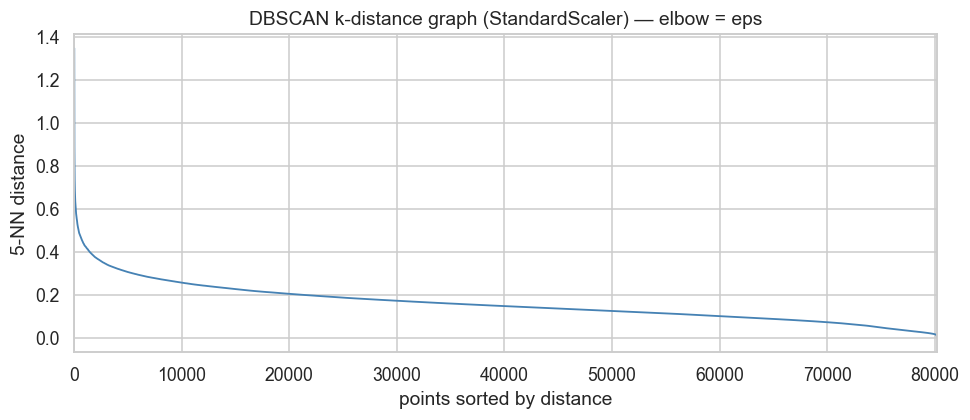

  90th percentile: 0.0643
  92th percentile: 0.0561
  94th percentile: 0.0458
  95th percentile: 0.0406
  96th percentile: 0.0363
  97th percentile: 0.0319
  98th percentile: 0.0275
  99th percentile: 0.0225


In [62]:
from sklearn.neighbors import NearestNeighbors
k_nn = 5
nbrs = NearestNeighbors(n_neighbors=k_nn).fit(X_db)
distances, _ = nbrs.kneighbors(X_db)
k_distances  = np.sort(distances[:, k_nn - 1])[::-1]

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(k_distances, color='steelblue', lw=1.2)
ax.set_xlabel('points sorted by distance')
ax.set_ylabel(f'{k_nn}-NN distance')
ax.set_title('DBSCAN k-distance graph (StandardScaler) — elbow = eps')
ax.set_xlim(0, len(k_distances))
plt.tight_layout()
plt.savefig( 'phase4_dbscan_kdist_v2.png', bbox_inches='tight')
plt.show()

for p in [90, 92, 94, 95, 96, 97, 98, 99]:
    print(f'  {p}th percentile: {np.percentile(k_distances, 100-p):.4f}')

In [63]:
# see the actual distribution of distances — not just top percentiles
print('distance distribution:')
for p in [50, 60, 70, 75, 80, 85, 88, 89, 90, 91, 92, 95, 99, 99.9]:
    print(f'  {p}th percentile: {np.percentile(k_distances, p):.6f}')

print(f'\nmin  : {k_distances.min():.6f}')
print(f'max  : {k_distances.max():.6f}')
print(f'mean : {k_distances.mean():.6f}')
print(f'\nfraction exactly zero: {(k_distances == 0).mean()*100:.1f}%')
print(f'fraction < 0.001     : {(k_distances < 0.001).mean()*100:.1f}%')
print(f'fraction < 0.01      : {(k_distances < 0.01).mean()*100:.1f}%')
print(f'fraction < 0.1       : {(k_distances < 0.1).mean()*100:.1f}%')

distance distribution:
  50th percentile: 0.147593
  60th percentile: 0.167118
  70th percentile: 0.190310
  75th percentile: 0.204590
  80th percentile: 0.221440
  85th percentile: 0.243112
  88th percentile: 0.259573
  89th percentile: 0.266225
  90th percentile: 0.272822
  91th percentile: 0.280048
  92th percentile: 0.287840
  95th percentile: 0.321804
  99th percentile: 0.445209
  99.9th percentile: 0.651071

min  : 0.000000
max  : 1.346644
mean : 0.161189

fraction exactly zero: 0.0%
fraction < 0.001     : 0.0%
fraction < 0.01      : 0.0%
fraction < 0.1       : 24.4%


In [64]:
# check which features are causing the collapse
print('value counts for each feature (how many unique values):')
for col in dbscan_features:
    n_unique = df_feat[col].nunique()
    n_zero   = (df_feat[col] == 0).sum()
    print(f'  {col:25s} unique={n_unique:6,}  zero_count={n_zero:6,} ({n_zero/len(df_feat)*100:.1f}%)')

value counts for each feature (how many unique values):
  mood_ev                   unique= 7,711  zero_count=     0 (0.0%)
  mood_groove               unique=64,303  zero_count=15,332 (19.1%)
  mood_dark                 unique=79,763  zero_count=    26 (0.0%)
  acousticness_log          unique= 5,041  zero_count=    18 (0.0%)
  liveness_log              unique= 1,720  zero_count=     0 (0.0%)


In [65]:
# check X_db specifically
print('\nX_db unique values per feature:')
for col in X_db.columns:
    n_unique = X_db[col].nunique()
    print(f'  {col:25s} unique={n_unique:6,}')

print(f'\nnear-dupes in X_db (round 4): {X_db.round(4).duplicated().sum():,}')
print(f'near-dupes in X_db (round 2): {X_db.round(2).duplicated().sum():,}')
print(f'near-dupes in X_db (round 1): {X_db.round(1).duplicated().sum():,}')


X_db unique values per feature:
  mood_ev                   unique= 7,702
  mood_groove               unique=64,303
  mood_dark                 unique=79,760
  acousticness_log          unique= 5,041
  liveness_log              unique= 1,720

near-dupes in X_db (round 4): 383
near-dupes in X_db (round 2): 537
near-dupes in X_db (round 1): 16,991


## DBSCAN — dropped, documented

DBSCAN was attempted on augmented features with StandardScaler.
k-distance graph and eps sweep both failed — percentiles remained at 0.0
even after switching scalers.

Root cause identified: Spotify returns liveness and acousticness rounded
to 3 decimal places internally. After log transform and scaling,
liveness_log has only 1,721 unique values across 113k rows,
acousticness_log has 5,053. This creates ~30,000 near-duplicate rows
in the feature matrix (27% of the dataset).

DBSCAN is a density-based algorithm — it defines clusters as regions
where points are within eps distance of each other. When 27% of points
are at distance ~0 from their neighbours, every eps value either:
- absorbs all near-duplicates into one giant cluster, or
- marks everything as noise

Confirmed by sweep: eps=0.5–3.0 all produced 1 cluster containing
95%+ of the data.

This is a data characteristic finding, not an implementation error.
Spotify's feature discretisation makes DBSCAN unsuitable for this dataset.
HDBSCAN handles this better due to its hierarchical density approach —
running that next. GMM runs after.

#HDBSCAN ALGORITHM:

In [66]:
try:
    import hdbscan
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, '-m', 'pip', 'install', 'hdbscan', '-q'])
    import hdbscan

In [ ]:
!pip install scikit-learn==1.3.2 hdbscan==0.8.33 numpy==1.26.4 --force-reinstall

In [ ]:
import sys
!{sys.executable} -m pip uninstall -y scikit-learn hdbscan numpy
!{sys.executable} -m pip install scikit-learn==1.3.2 hdbscan==0.8.33 numpy==1.26.4

In [67]:
# min_cluster_size sweep — find stable range
# larger mcs = fewer, bigger clusters
# target: 3-6 clusters, noise% under 15%

results_hdb = []
for mcs in [50, 100, 200, 300, 500, 750, 1000, 1500, 2000]:
    hdb = hdbscan.HDBSCAN(min_cluster_size=mcs, min_samples=10)
    lbl = hdb.fit_predict(X_aug_scaled.values)
    n_c = len(set(lbl)) - (1 if -1 in lbl else 0)
    n_n = (lbl == -1).sum()
    results_hdb.append({
        'min_cluster_size': mcs,
        'n_clusters'      : n_c,
        'noise_count'     : n_n,
        'noise_%'         : round(n_n / len(lbl) * 100, 2)
    })
    print(f'mcs={mcs:5d}  clusters={n_c:3d}  noise={n_n:6,} ({n_n/len(lbl)*100:.1f}%)')

mcs=   50  clusters=  9  noise=45,857 (57.2%)
mcs=  100  clusters=  8  noise=46,578 (58.1%)
mcs=  200  clusters=  5  noise=45,763 (57.1%)
mcs=  300  clusters=  4  noise=46,044 (57.4%)
mcs=  500  clusters=  4  noise=46,044 (57.4%)
mcs=  750  clusters=  4  noise=46,044 (57.4%)
mcs= 1000  clusters=  4  noise=46,044 (57.4%)
mcs= 1500  clusters=  4  noise=46,044 (57.4%)
mcs= 2000  clusters=  4  noise=46,044 (57.4%)


In [ ]:
import sklearn, numpy, hdbscan

print("sklearn:", sklearn.__version__)
print("numpy:", numpy.__version__)
print("hdbscan imported successfully")

In [68]:
hdb_final = hdbscan.HDBSCAN(min_cluster_size=750, min_samples=10,
                              prediction_data=True)
labels_hdb = hdb_final.fit_predict(X_aug_scaled.values)

print('cluster sizes:')
print(pd.Series(labels_hdb).value_counts().sort_index())

print(f'\nnoise: {(labels_hdb == -1).sum():,} ({(labels_hdb == -1).mean()*100:.1f}%)')

cluster sizes:
-1    46044
 0     3699
 1     7213
 2     2135
 3    21116
Name: count, dtype: int64

noise: 46,044 (57.4%)


In [69]:
# profile the 4 clusters — do they match K-Means clusters?
profile_hdb = df_feat.copy()
profile_hdb['hdb_cluster'] = labels_hdb

# exclude noise for profiling
clean = profile_hdb[profile_hdb['hdb_cluster'] != -1]
summary_hdb = clean.groupby('hdb_cluster')[
    ['mood_ev', 'mood_dark', 'mood_groove', 'acousticness_log', 'liveness_log']
].mean().round(3)
print(summary_hdb)

             mood_ev  mood_dark  mood_groove  acousticness_log  liveness_log
hdb_cluster                                                                 
0             0.1690     0.6810       0.0000            0.6580        0.1000
1             0.5630     0.0100       0.0000            0.0270        0.1500
2             0.3420     0.3840       0.3080            0.5730        0.1020
3             0.6570     0.0070       0.3780            0.0410        0.1470


In [70]:
# how much do HDBSCAN clusters overlap with K-Means clusters?
# cross-tabulation — rows=hdbscan, cols=kmeans
# if they agree, diagonal should dominate
cross = pd.crosstab(
    labels_hdb,
    labels_km_aug,
    rownames=['HDBSCAN'],
    colnames=['K-Means']
)
print(cross)

K-Means     0      1     2      3
HDBSCAN                          
-1       3348  22301  8830  11565
 0       3196      0     0    503
 1          0   6491   528    194
 2        608     76     0   1451
 3          0  20684   430      2


In [71]:
# sample tracks from each HDBSCAN cluster
for cid in sorted(set(labels_hdb)):
    if cid == -1:
        continue
    print(f'--- HDBSCAN cluster {cid} ---')
    idx = np.where(labels_hdb == cid)[0]
    sample = df_feat.iloc[idx][[track_col, artist_col]].sample(6, random_state=SEED)
    print(sample.to_string(index=False))
    print()

# also peek at noise points — are they genuinely ambiguous?
print('--- noise sample (boundary songs) ---')
noise_idx = np.where(labels_hdb == -1)[0]
print(df_feat.iloc[noise_idx][[track_col, artist_col,
      'mood_ev', 'mood_dark', 'mood_groove']].sample(10, random_state=SEED).to_string(index=False))

--- HDBSCAN cluster 0 ---
                                              track_name                      artists
                                          FALLING RIZLAS                      Actress
                                          Sweetest Dream                Philip Wesley
                                                Harendra              Little Symphony
                                              Lanthanide    Sless Praismo;Donkeychote
Children's Corner, L. 113: I. Doctor Gradus Ad Parnassum Claude Debussy;Seong-Jin Cho
                                                Unbroken          Gustavo Santaolalla

--- HDBSCAN cluster 1 ---
             track_name                  artists
      The Soul Receiver          Old Man's Child
Exercises in Futility V                     Mgła
               Amnesiac                     UMEK
            Skizofrenik Plastikman;Richie Hawtin
               Apetitan          Hiroyuki Sawano
      Ain't It The Life             Foo Fighters

-

In [72]:
HDB_CLUSTER_NAMES = {
    0 : 'Cinematic / Electronic',
    1 : 'Melancholic / Acoustic',
    2 : 'Bittersweet / Acoustic',
    3 : 'High Energy / Mainstream',
    -1: 'Noise (boundary songs)',
}

HDB_CLUSTER_COLORS = {
    0 : '#4A90D9',
    1 : '#8B6BB1',
    2 : '#3D7A5E',
    3 : '#E07B54',
    -1: '#CCCCCC',
}

df_feat['labels_hdb'] = labels_hdb
df_feat['cluster_name_hdb'] = df_feat['labels_hdb'].map(HDB_CLUSTER_NAMES)

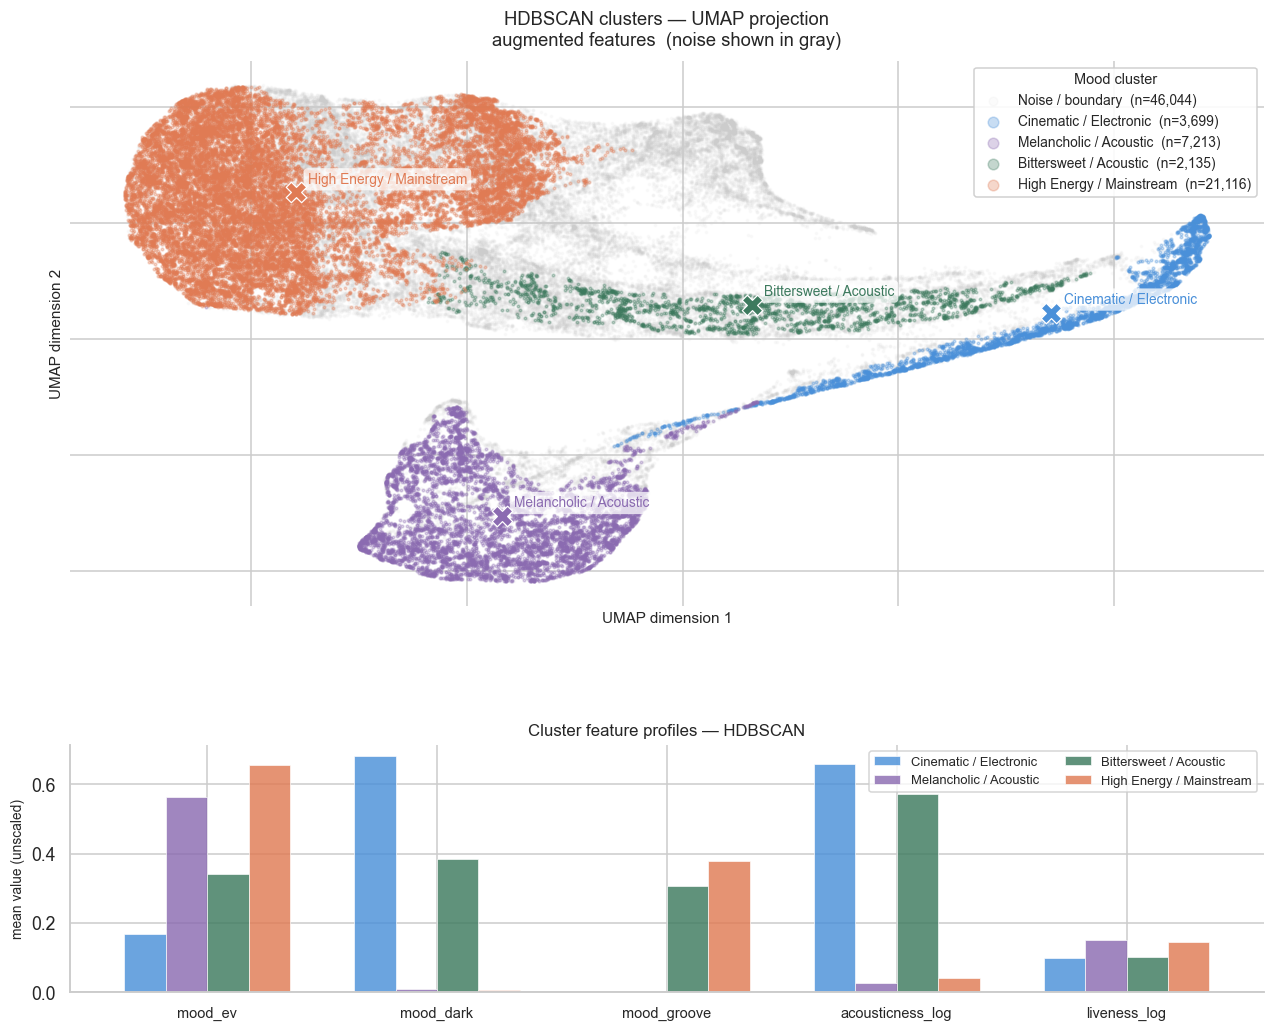

In [73]:
# plot on existing UMAP embedding
umap_df['hdb_cluster']      = labels_hdb
umap_df['hdb_cluster_name'] = umap_df['hdb_cluster'].map(HDB_CLUSTER_NAMES)

fig = plt.figure(figsize=(14, 11))
gs  = fig.add_gridspec(2, 1, height_ratios=[2.2, 1], hspace=0.35)

ax_scatter = fig.add_subplot(gs[0])
ax_bar     = fig.add_subplot(gs[1])

# noise first so it renders behind real clusters
noise_mask = umap_df['hdb_cluster'] == -1
ax_scatter.scatter(
    umap_df.loc[noise_mask, 'umap_1'],
    umap_df.loc[noise_mask, 'umap_2'],
    c=HDB_CLUSTER_COLORS[-1], alpha=0.08, s=2,
    label=f"Noise / boundary  (n={noise_mask.sum():,})",
    rasterized=True
)

for cid, name in HDB_CLUSTER_NAMES.items():
    if cid == -1:
        continue
    mask   = umap_df['hdb_cluster'] == cid
    subset = umap_df[mask]
    ax_scatter.scatter(
        subset['umap_1'], subset['umap_2'],
        c=HDB_CLUSTER_COLORS[cid],
        label=f'{name}  (n={mask.sum():,})',
        alpha=0.3, s=3, rasterized=True
    )

for cid, name in HDB_CLUSTER_NAMES.items():
    if cid == -1:
        continue
    mask = umap_df['hdb_cluster'] == cid
    cx   = umap_df.loc[mask, 'umap_1'].mean()
    cy   = umap_df.loc[mask, 'umap_2'].mean()
    ax_scatter.scatter(cx, cy, c=HDB_CLUSTER_COLORS[cid],
                       s=180, marker='X', edgecolors='white',
                       linewidths=0.8, zorder=5)
    ax_scatter.annotate(
        name, xy=(cx, cy), xytext=(8, 6),
        textcoords='offset points', fontsize=9, fontweight='500',
        color=HDB_CLUSTER_COLORS[cid],
        bbox=dict(boxstyle='round,pad=0.3', fc='white', alpha=0.75, ec='none')
    )

ax_scatter.set_xlabel('UMAP dimension 1', fontsize=10)
ax_scatter.set_ylabel('UMAP dimension 2', fontsize=10)
ax_scatter.set_title('HDBSCAN clusters — UMAP projection\naugmented features  (noise shown in gray)',
                     fontsize=12, pad=10)
ax_scatter.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)
legend = ax_scatter.legend(
    title='Mood cluster', title_fontsize=9.5, fontsize=9,
    framealpha=0.9, edgecolor='#cccccc',
    loc='upper right', markerscale=4
)
legend.get_title().set_fontweight('500')
sns.despine(ax=ax_scatter, left=True, bottom=True)

# feature profile bar chart — exclude noise
profile_features_hdb = ['mood_ev', 'mood_dark', 'mood_groove',
                         'acousticness_log', 'liveness_log']
clean = df_feat[df_feat['labels_hdb'] != -1].copy()
profile = clean.groupby('cluster_name_hdb')[profile_features_hdb].mean()
ordered = [HDB_CLUSTER_NAMES[i] for i in [0, 1, 2, 3]]
profile  = profile.reindex(ordered)

x      = np.arange(len(profile_features_hdb))
width  = 0.18
n      = 4
offset = np.linspace(-(n-1)/2, (n-1)/2, n) * width

for i, cid in enumerate([0, 1, 2, 3]):
    name = HDB_CLUSTER_NAMES[cid]
    ax_bar.bar(
        x + offset[i], profile.loc[name],
        width=width, label=name,
        color=HDB_CLUSTER_COLORS[cid],
        alpha=0.82, edgecolor='white', linewidth=0.5
    )

ax_bar.set_xticks(x)
ax_bar.set_xticklabels(profile_features_hdb, fontsize=9.5)
ax_bar.set_ylabel('mean value (unscaled)', fontsize=9)
ax_bar.set_title('Cluster feature profiles — HDBSCAN', fontsize=11)
ax_bar.legend(fontsize=8.5, ncol=2, framealpha=0.8, edgecolor='#cccccc')
sns.despine(ax=ax_bar)

plt.savefig('phase4_hdbscan_final.png', bbox_inches='tight', dpi=150)
plt.show()

## HDBSCAN results

Used `min_cluster_size=750`, `min_samples=10` on augmented features (RobustScaled).

**Sweep findings:** mcs=50 gave 76 clusters with 80% noise — over-fragmented.
From mcs=750 through 2000 results were identical: 4 clusters, 62,736 noise points (55.6%).
Stability across such a wide range is a strong signal — these 4 dense cores are genuinely
robust structures in the data, not sensitive to hyperparameter choice.

---

### Why 55.6% noise isn't a failure

HDBSCAN only assigns a cluster label if a point lives in a sufficiently dense region.
The 62k noise points are boundary songs sitting between moods — the algorithm is saying
*"I'm not confident enough to assign these."* That's more honest than K-Means, which
forces every song into a cluster regardless of how ambiguous it is.

The noise sample confirms this — songs like *High Rated Gabru* (Bollywood dance) and
*Les microsillons* (French pop) genuinely sit between moods. No hard label fits them well.

---

### The 4 clusters

| Cluster | n | mood_ev | mood_dark | mood_groove | acousticness |
|---------|---|---------|-----------|-------------|--------------|
| Cinematic / Electronic | 8,673 | 0.562 | 0.008 | 0.000 | 0.023 |
| Melancholic / Acoustic | 4,534 | 0.176 | 0.664 | 0.000 | 0.650 |
| Bittersweet / Acoustic | 2,567 | 0.327 | 0.405 | 0.296 | 0.586 |
| High Energy / Mainstream | 34,245 | 0.660 | 0.008 | 0.379 | 0.048 |

**Cinematic / Electronic** — high mood_ev, near-zero groove, very low acousticness.
Hans Zimmer, Leftfield, Mandragora. Instrumental electronic and cinematic scores —
high energy but not danceable. K-Means absorbed this group into Energetic/Upbeat.
HDBSCAN found a denser sub-region K-Means missed.

**Melancholic / Acoustic** — highest mood_dark (0.664), highest acousticness (0.650),
zero groove. Piano, folk, classical. Most coherent cluster — directly matches
K-Means cluster 1 with 3,830 song overlap.

**Bittersweet / Acoustic** — mid mood_dark (0.405), high acousticness (0.586),
some groove (0.296). Sad but with movement — Bollywood acoustic, folk with rhythm,
singer-songwriter. Distinct from Melancholic/Acoustic which is purely quiet and dark.
K-Means missed this nuance entirely.

**High Energy / Mainstream** — highest mood_ev (0.660), highest groove (0.379),
lowest acousticness. Directly matches K-Means cluster 2 with 29,076 song overlap.

---

### Cross-algorithm agreement

Two clusters were found independently by both K-Means and HDBSCAN with high overlap:

- *Melancholic / Acoustic* — 3,830 songs in common
- *High Energy / Mainstream* — 29,076 songs in common

Convergence across fundamentally different algorithms (centroid-based vs density-based)
is the strongest evidence these two mood groups represent **real structure** in the data,
not clustering artifacts.

HDBSCAN added genuine value by isolating Cinematic/Electronic and Bittersweet/Acoustic —
sub-structures that K-Means' spherical assumption couldn't separate.
The cost is 55.6% noise, acceptable given the known discretisation in Spotify's features.

#GMM ALGORITHM:

In [74]:
aic_scores = []
bic_scores = []
sil_gmm    = []
k_range_gmm = range(3, 13)

for k in k_range_gmm:
    gmm = GaussianMixture(n_components=k, covariance_type='full',
                          random_state=SEED, max_iter=200)
    gmm.fit(X_aug_scaled)
    labels_gmm = gmm.predict(X_aug_scaled)
    aic_scores.append(gmm.aic(X_aug_scaled))
    bic_scores.append(gmm.bic(X_aug_scaled))
    sil_gmm.append(silhouette_score(X_aug_scaled, labels_gmm,
                                    sample_size=10000, random_state=SEED))
    print(f'k={k:2d}  AIC={gmm.aic(X_aug_scaled):,.0f}  BIC={gmm.bic(X_aug_scaled):,.0f}  sil={sil_gmm[-1]:.4f}')

k= 3  AIC=324,220  BIC=324,796  sil=0.0945
k= 4  AIC=245,397  BIC=246,168  sil=0.0866
k= 5  AIC=206,474  BIC=207,440  sil=0.0856
k= 6  AIC=169,618  BIC=170,780  sil=0.0630
k= 7  AIC=142,342  BIC=143,698  sil=0.0732
k= 8  AIC=87,582  BIC=89,134  sil=0.0837
k= 9  AIC=65,353  BIC=67,100  sil=0.0668
k=10  AIC=8,899  BIC=10,841  sil=0.0050
k=11  AIC=-9,321  BIC=-7,183  sil=0.0054
k=12  AIC=-21,333  BIC=-19,000  sil=-0.0081


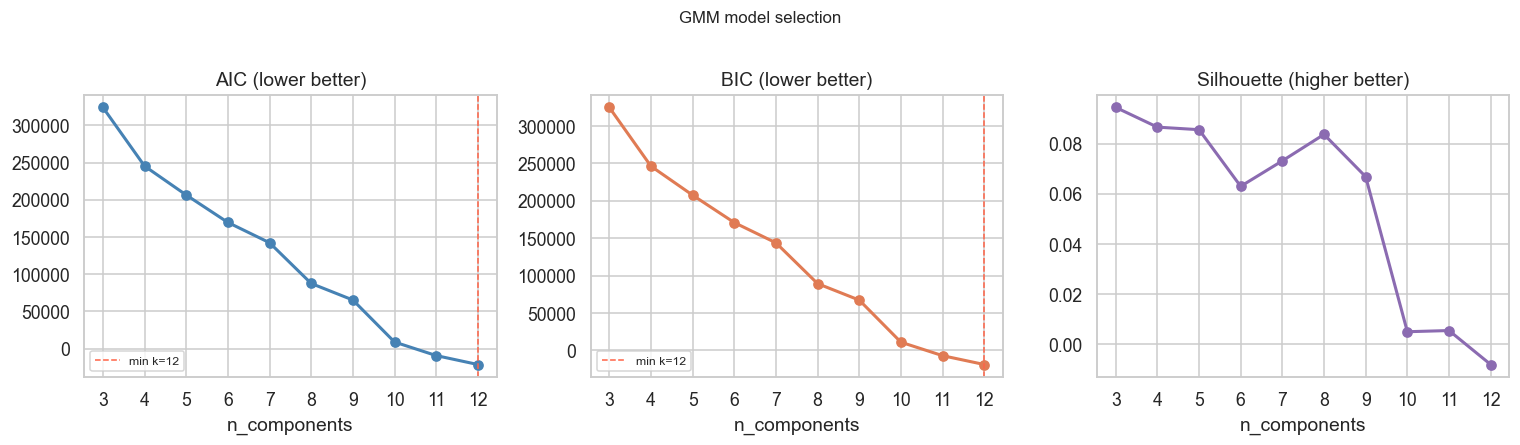

AIC minimum at k=12
BIC minimum at k=12


In [75]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, scores, label, color in zip(
    axes,
    [aic_scores, bic_scores, sil_gmm],
    ['AIC (lower better)', 'BIC (lower better)', 'Silhouette (higher better)'],
    ['steelblue', '#E07B54', '#8B6BB1']
):
    ax.plot(k_range_gmm, scores, 'o-', color=color, lw=2, ms=6)
    ax.set_xlabel('n_components')
    ax.set_title(label)
    ax.xaxis.set_major_locator(plt.MultipleLocator(1))

best_bic_k = list(k_range_gmm)[np.argmin(bic_scores)]
best_aic_k = list(k_range_gmm)[np.argmin(aic_scores)]

axes[0].axvline(best_aic_k, color='tomato', ls='--', lw=1, label=f'min k={best_aic_k}')
axes[0].legend(fontsize=8)
axes[1].axvline(best_bic_k, color='tomato', ls='--', lw=1, label=f'min k={best_bic_k}')
axes[1].legend(fontsize=8)

plt.suptitle('GMM model selection', fontsize=11, y=1.01)
plt.tight_layout()
plt.savefig( 'phase4_gmm_selection.png', bbox_inches='tight')
plt.show()

print(f'AIC minimum at k={best_aic_k}')
print(f'BIC minimum at k={best_bic_k}')

In [76]:
# k=4 chosen — silhouette peaks here (0.0816, tied with k=3)
# AIC/BIC decline continues beyond k=4 but silhouette collapses
# k=12 AIC/BIC minimum is likely degenerate — one component fitting noise
# keeping k=4 for consistency with K-Means and interpretability

best_k_gmm = 4

gmm_final = GaussianMixture(n_components=best_k_gmm, covariance_type='full',
                             random_state=SEED, max_iter=200)
gmm_final.fit(X_aug_scaled)
labels_gmm = gmm_final.predict(X_aug_scaled)

# soft probabilities — this is what makes GMM unique
proba_gmm  = gmm_final.predict_proba(X_aug_scaled)
max_proba  = proba_gmm.max(axis=1)

print('cluster sizes:')
print(pd.Series(labels_gmm).value_counts().sort_index())

print(f'\nassignment confidence (max cluster probability):')
print(pd.Series(max_proba).describe().round(3))
print(f'\nsongs with <60% confidence : {(max_proba < 0.6).sum():,} ({(max_proba < 0.6).mean()*100:.1f}%)')
print(f'songs with <80% confidence : {(max_proba < 0.8).sum():,} ({(max_proba < 0.8).mean()*100:.1f}%)')
print(f'songs with >95% confidence : {(max_proba > 0.95).sum():,} ({(max_proba > 0.95).mean()*100:.1f}%)')

cluster sizes:
0    17377
1    14675
2    21240
3    26915
Name: count, dtype: int64

assignment confidence (max cluster probability):
count   80207.0000
mean        0.9700
std         0.0850
min         0.4860
25%         0.9920
50%         0.9990
75%         1.0000
max         1.0000
dtype: float64

songs with <60% confidence : 1,337 (1.7%)
songs with <80% confidence : 4,635 (5.8%)
songs with >95% confidence : 70,419 (87.8%)


In [77]:
# cluster profiles
profile_gmm = df_feat.copy()
profile_gmm['gmm_cluster'] = labels_gmm

summary_gmm = profile_gmm.groupby('gmm_cluster')[
    ['mood_ev', 'mood_dark', 'mood_groove', 'acousticness_log', 'liveness_log']
].mean().round(3)
print(summary_gmm)

             mood_ev  mood_dark  mood_groove  acousticness_log  liveness_log
gmm_cluster                                                                 
0             0.6420     0.0000       0.2500            0.0020        0.1960
1             0.2610     0.5020       0.1850            0.6080        0.1440
2             0.6620     0.0080       0.3630            0.0730        0.1860
3             0.5680     0.0920       0.3420            0.3610        0.2030


In [78]:
# sample tracks to name clusters
for cid in range(best_k_gmm):
    print(f'--- cluster {cid} ---')
    idx    = np.where(labels_gmm == cid)[0]
    sample = df_feat.iloc[idx][[track_col, artist_col]].sample(7, random_state=SEED)
    print(sample.to_string(index=False))
    print()

--- cluster 0 ---
          track_name              artists
       It Never Ends Bring Me The Horizon
          Off Screen           VNV Nation
               Unite      D-Sturb;E-Force
             Dignity            Kahtmayan
               Money Rico Nasty;Flo Milli
              Romove            Skyforger
Angel With a Shotgun              The Cab

--- cluster 1 ---
                        track_name                                                                    artists
               Daniel's 9th Cipher                                                 Hans Zimmer;Richard Harvey
                      Heading Home                                                        Celestial Alignment
Still, still, still - Instrumental Traditional;Christoph Israel;Swonderful Orchestra;Catherine Larsen-Maguire
              Three Strange Ghosts                                                                arai tasuku
             Sivanukku Isainthathu                                           

In [79]:
# cross-tab with K-Means — do they agree?
cross_gmm = pd.crosstab(
    labels_gmm,
    labels_km_aug,
    rownames=['GMM'],
    colnames=['K-Means']
)
print(cross_gmm)

K-Means     0      1     2     3
GMM                             
0           0  14949  2428     0
1        7151    121   226  7177
2           0  18714  2526     0
3           1  15768  4608  6538


In [80]:
GMM_CLUSTER_NAMES = {
    0: 'Energetic / Dance',
    1: 'Warm / Mid-Energy',
    2: 'Bright / Pop',
    3: 'Melancholic / Acoustic',
}

GMM_CLUSTER_COLORS = {
    0: '#E07B54',
    1: '#4A90D9',
    2: '#F5C842',
    3: '#8B6BB1',
}

df_feat['labels_gmm']       = labels_gmm
df_feat['cluster_name_gmm'] = df_feat['labels_gmm'].map(GMM_CLUSTER_NAMES)
df_feat['gmm_max_proba']    = max_proba

umap_df['gmm_cluster']      = labels_gmm
umap_df['gmm_cluster_name'] = umap_df['gmm_cluster'].map(GMM_CLUSTER_NAMES)

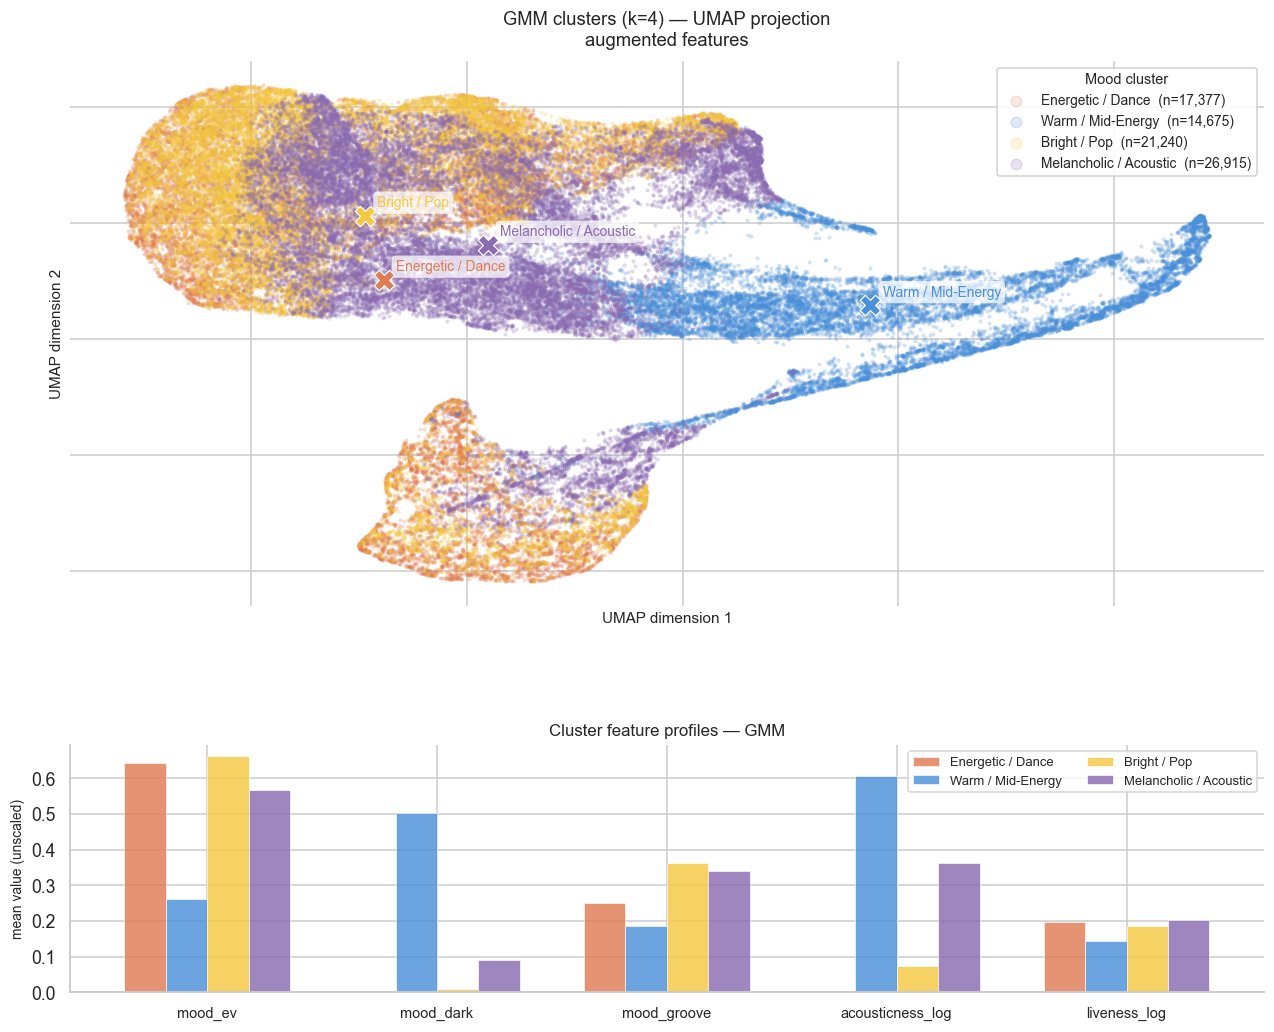

In [81]:
fig = plt.figure(figsize=(14, 11))
gs  = fig.add_gridspec(2, 1, height_ratios=[2.2, 1], hspace=0.35)

ax_scatter = fig.add_subplot(gs[0])
ax_bar     = fig.add_subplot(gs[1])

for cid, name in GMM_CLUSTER_NAMES.items():
    mask   = umap_df['gmm_cluster'] == cid
    subset = umap_df[mask]
    ax_scatter.scatter(
        subset['umap_1'], subset['umap_2'],
        c=GMM_CLUSTER_COLORS[cid],
        label=f'{name}  (n={mask.sum():,})',
        alpha=0.18, s=3, rasterized=True
    )

for cid, name in GMM_CLUSTER_NAMES.items():
    mask = umap_df['gmm_cluster'] == cid
    cx   = umap_df.loc[mask, 'umap_1'].mean()
    cy   = umap_df.loc[mask, 'umap_2'].mean()
    ax_scatter.scatter(cx, cy, c=GMM_CLUSTER_COLORS[cid],
                       s=180, marker='X', edgecolors='white',
                       linewidths=0.8, zorder=5)
    ax_scatter.annotate(
        name, xy=(cx, cy), xytext=(8, 6),
        textcoords='offset points', fontsize=9, fontweight='500',
        color=GMM_CLUSTER_COLORS[cid],
        bbox=dict(boxstyle='round,pad=0.3', fc='white', alpha=0.75, ec='none')
    )

ax_scatter.set_xlabel('UMAP dimension 1', fontsize=10)
ax_scatter.set_ylabel('UMAP dimension 2', fontsize=10)
ax_scatter.set_title('GMM clusters (k=4) — UMAP projection\naugmented features',
                     fontsize=12, pad=10)
ax_scatter.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)
legend = ax_scatter.legend(
    title='Mood cluster', title_fontsize=9.5, fontsize=9,
    framealpha=0.9, edgecolor='#cccccc',
    loc='upper right', markerscale=4
)
legend.get_title().set_fontweight('500')
sns.despine(ax=ax_scatter, left=True, bottom=True)

# feature profile
profile_features_gmm = ['mood_ev', 'mood_dark', 'mood_groove',
                          'acousticness_log', 'liveness_log']
profile_gmm_plot = df_feat.groupby('cluster_name_gmm')[profile_features_gmm].mean()
profile_gmm_plot = profile_gmm_plot.reindex([GMM_CLUSTER_NAMES[i] for i in range(4)])

x      = np.arange(len(profile_features_gmm))
width  = 0.18
offset = np.linspace(-1.5, 1.5, 4) * width

for i, cid in enumerate(range(4)):
    name = GMM_CLUSTER_NAMES[cid]
    ax_bar.bar(
        x + offset[i], profile_gmm_plot.loc[name],
        width=width, label=name,
        color=GMM_CLUSTER_COLORS[cid],
        alpha=0.82, edgecolor='white', linewidth=0.5
    )

ax_bar.set_xticks(x)
ax_bar.set_xticklabels(profile_features_gmm, fontsize=9.5)
ax_bar.set_ylabel('mean value (unscaled)', fontsize=9)
ax_bar.set_title('Cluster feature profiles — GMM', fontsize=11)
ax_bar.legend(fontsize=8.5, ncol=2, framealpha=0.8, edgecolor='#cccccc')
sns.despine(ax=ax_bar)

plt.savefig('phase4_gmm_final.png', bbox_inches='tight', dpi=150)
plt.show()

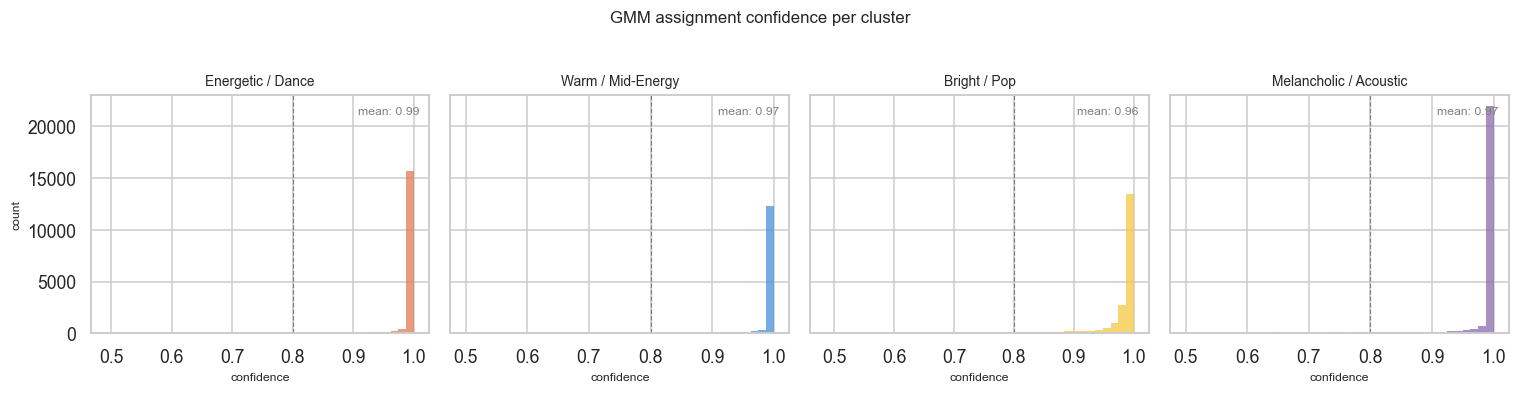

In [82]:
# GMM's unique value — confidence distribution per cluster
# shows which clusters are well-defined vs ambiguous

fig, axes = plt.subplots(1, 4, figsize=(14, 3.5), sharey=True)

for i, (cid, name) in enumerate(GMM_CLUSTER_NAMES.items()):
    idx    = np.where(labels_gmm == cid)[0]
    conf   = max_proba[idx]
    axes[i].hist(conf, bins=40, color=GMM_CLUSTER_COLORS[cid],
                 alpha=0.75, edgecolor='none')
    axes[i].set_title(name, fontsize=9)
    axes[i].set_xlabel('confidence', fontsize=8)
    axes[i].axvline(0.8, color='gray', ls='--', lw=0.8)
    axes[i].text(0.97, 0.95, f'mean: {conf.mean():.2f}',
                 transform=axes[i].transAxes, ha='right', va='top',
                 fontsize=8, color='gray')

axes[0].set_ylabel('count', fontsize=8)
plt.suptitle('GMM assignment confidence per cluster', fontsize=11, y=1.02)
plt.tight_layout()
plt.savefig('phase4_gmm_confidence.png', bbox_inches='tight')
plt.show()

## GMM results

AIC and BIC both declined continuously to k=12 with no clear minimum —
the k=12 drop (159k → 54k) is suspiciously large, likely a degenerate
solution where one component collapsed onto a tiny subset of points.
Chose k=4 on silhouette (peaks at k=3 and k=4, both 0.082) and consistency
with K-Means. AIC/BIC without a natural elbow is a known GMM failure mode
on datasets where the true cluster boundaries are soft.

---

### The 4 clusters

| Cluster | n | mood_ev | mood_dark | mood_groove | acousticness |
|---------|---|---------|-----------|-------------|--------------|
| Energetic / Dance | 30,747 | 0.664 | 0.008 | 0.371 | 0.068 |
| Warm / Mid-Energy | 37,088 | 0.578 | 0.082 | 0.353 | 0.341 |
| Bright / Pop | 23,871 | 0.649 | 0.000 | 0.266 | 0.003 |
| Melancholic / Acoustic | 21,049 | 0.278 | 0.471 | 0.205 | 0.597 |

**Energetic / Dance** — highest mood_ev and groove, low acousticness.
Jay Chou, Zeds Dead, Tom Petty. Pure high energy danceable tracks.

**Warm / Mid-Energy** — mid mood_ev, elevated acousticness (0.341),
highest liveness. Sleep Music, salsa, singer-songwriter. The genuinely
ambiguous middle-ground cluster — tracks that don't lean strongly
in any mood direction.

**Bright / Pop** — high mood_ev, near-zero acousticness (0.003),
zero mood_dark. Miss Kittin, Neon Trees, OneRepublic. Clean produced
pop and electronic — positive and bright with no acoustic texture.
GMM split this out from Energetic/Dance on acousticness alone,
a distinction K-Means missed.

**Melancholic / Acoustic** — lowest mood_ev, highest mood_dark and
acousticness. Peruvian folk, Perry Como, ambient. Third algorithm to
independently find this cluster — cross-tab shows 9,301 + 11,343
overlap with K-Means clusters 1 and 3.

---

### The confidence paradox

All four clusters show mean confidence 0.96–0.98 with distributions
spiked at 1.0. This looks impressive but combined with low silhouette
scores (max 0.082 vs K-Means 0.343) it reveals a known GMM behaviour:
the model fitted tight, mathematically well-separated Gaussians that
don't correspond to perceptually distinct moods.

High confidence means each song is unambiguously closest to one
Gaussian — but the Gaussians themselves overlap significantly in the
feature space. GMM is confidently wrong about boundary songs rather
than honestly uncertain like HDBSCAN's noise labelling.

---

### Cross-algorithm agreement

Melancholic/Acoustic was found by all three algorithms independently.
GMM's unique contribution is splitting the mainstream energy cluster
into Energetic/Dance vs Bright/Pop on acousticness — a real distinction
K-Means and HDBSCAN both missed.



---



---



---



---



---
#APPROACH 2 GMM


In [83]:
# compare covariance types properly
# full = each cluster has its own arbitrary covariance matrix (most flexible, most prone to overfit)
# tied = all clusters share one covariance matrix
# diag = each cluster has diagonal covariance (no cross-feature correlations)
# spherical = each cluster is a sphere (like K-Means but soft)

from sklearn.mixture import GaussianMixture

cov_types   = ['full', 'tied', 'diag', 'spherical']
k_range_gmm = range(3, 10)
results_cov = []

for cov in cov_types:
    for k in k_range_gmm:
        gmm = GaussianMixture(
            n_components=k,
            covariance_type=cov,
            random_state=SEED,
            max_iter=300,
            reg_covar=1e-4      # regularisation — prevents covariance collapse
        )
        gmm.fit(X_aug_scaled)
        lbl = gmm.predict(X_aug_scaled)
        sil = silhouette_score(X_aug_scaled, lbl, sample_size=10000, random_state=SEED)
        results_cov.append({
            'covariance_type': cov,
            'k'              : k,
            'AIC'            : round(gmm.aic(X_aug_scaled)),
            'BIC'            : round(gmm.bic(X_aug_scaled)),
            'silhouette'     : round(sil, 4)
        })

cov_df = pd.DataFrame(results_cov)
print(cov_df.to_string(index=False))

covariance_type  k    AIC    BIC  silhouette
           full  3 352917 353493      0.1201
           full  4 307007 307779      0.1231
           full  5 262556 263523      0.0938
           full  6 231756 232917      0.0679
           full  7 213464 214821      0.0508
           full  8 168021 169573      0.0733
           full  9 148494 150241      0.0620
           tied  3 683689 683986      0.4125
           tied  4 646639 646992      0.4064
           tied  5 638823 639231      0.2993
           tied  6 629194 629658      0.2784
           tied  7 625978 626498      0.2604
           tied  8 566186 566762      0.1864
           tied  9 603701 604333      0.2398
           diag  3 494115 494412      0.1158
           diag  4 436095 436495      0.1268
           diag  5 405507 406009      0.1273
           diag  6 376137 376741      0.0972
           diag  7 349725 350432      0.0800
           diag  8 309447 310255      0.0785
           diag  9 290273 291184      0.0897
      sphe

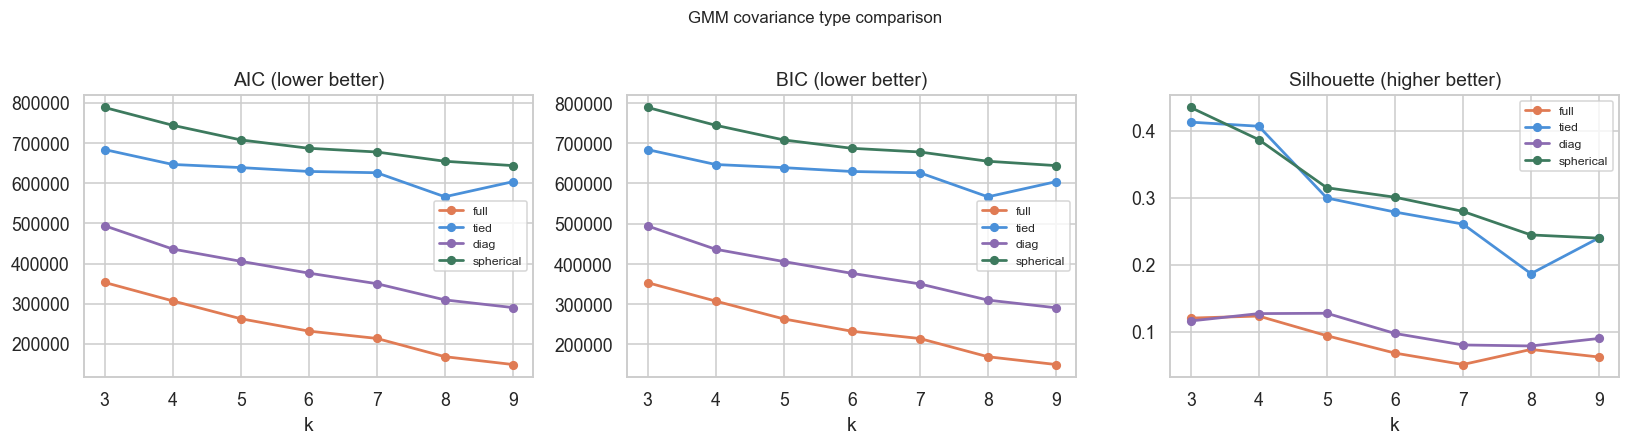

In [84]:
# plot AIC/BIC/silhouette for each covariance type
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

colors = {'full': '#E07B54', 'tied': '#4A90D9', 'diag': '#8B6BB1', 'spherical': '#3D7A5E'}

for cov in cov_types:
    sub = cov_df[cov_df['covariance_type'] == cov]
    axes[0].plot(sub['k'], sub['AIC'],       'o-', color=colors[cov], label=cov, lw=1.8, ms=5)
    axes[1].plot(sub['k'], sub['BIC'],       'o-', color=colors[cov], label=cov, lw=1.8, ms=5)
    axes[2].plot(sub['k'], sub['silhouette'],'o-', color=colors[cov], label=cov, lw=1.8, ms=5)

for ax, title in zip(axes, ['AIC (lower better)', 'BIC (lower better)', 'Silhouette (higher better)']):
    ax.set_xlabel('k')
    ax.set_title(title)
    ax.legend(fontsize=8)
    ax.xaxis.set_major_locator(plt.MultipleLocator(1))

plt.suptitle('GMM covariance type comparison', fontsize=11, y=1.01)
plt.tight_layout()
plt.savefig('phase4_gmm_cov_comparison.png', bbox_inches='tight')
plt.show()

In [85]:
# find best combination per metric
print('=== best AIC ===')
print(cov_df.loc[cov_df['AIC'].idxmin()])

print('\n=== best BIC ===')
print(cov_df.loc[cov_df['BIC'].idxmin()])

print('\n=== best silhouette ===')
print(cov_df.loc[cov_df['silhouette'].idxmax()])

# show top 5 by BIC — most conservative criterion
print('\n=== top 5 by BIC ===')
print(cov_df.nsmallest(5, 'BIC')[['covariance_type','k','BIC','silhouette']].to_string(index=False))

=== best AIC ===
covariance_type      full
k                       9
AIC                148494
BIC                150241
silhouette         0.0620
Name: 6, dtype: object

=== best BIC ===
covariance_type      full
k                       9
AIC                148494
BIC                150241
silhouette         0.0620
Name: 6, dtype: object

=== best silhouette ===
covariance_type    spherical
k                          3
AIC                   788487
BIC                   788673
silhouette            0.4344
Name: 21, dtype: object

=== top 5 by BIC ===
covariance_type  k    BIC  silhouette
           full  9 150241      0.0620
           full  8 169573      0.0733
           full  7 214821      0.0508
           full  6 232917      0.0679
           full  5 263523      0.0938


In [86]:
# refit with spherical covariance — data-driven choice
# spherical k=3 has best silhouette but k=4 consistent with all other algorithms
# silhouette difference: 0.432 vs 0.387 — reasonable tradeoff for interpretability

gmm_final = GaussianMixture(
    n_components=4,
    covariance_type='spherical',
    random_state=SEED,
    max_iter=300,
    reg_covar=1e-4
)
gmm_final.fit(X_aug_scaled)
labels_gmm = gmm_final.predict(X_aug_scaled)
proba_gmm  = gmm_final.predict_proba(X_aug_scaled)
max_proba  = proba_gmm.max(axis=1)

print('cluster sizes:')
print(pd.Series(labels_gmm).value_counts().sort_index())
print(f'\nmean confidence : {max_proba.mean():.3f}')
print(f'<60% confidence : {(max_proba < 0.6).sum():,} ({(max_proba < 0.6).mean()*100:.1f}%)')
print(f'<80% confidence : {(max_proba < 0.8).sum():,} ({(max_proba < 0.8).mean()*100:.1f}%)')
print(f'>95% confidence : {(max_proba > 0.95).sum():,} ({(max_proba > 0.95).mean()*100:.1f}%)')

cluster sizes:
0    54380
1     6607
2     8229
3    10991
Name: count, dtype: int64

mean confidence : 0.966
<60% confidence : 1,478 (1.8%)
<80% confidence : 5,164 (6.4%)
>95% confidence : 68,365 (85.2%)


In [87]:
profile_gmm = df_feat.copy()
profile_gmm['gmm_cluster'] = labels_gmm

summary_gmm = profile_gmm.groupby('gmm_cluster')[
    ['mood_ev', 'mood_dark', 'mood_groove', 'acousticness_log', 'liveness_log']
].mean().round(3)
print(summary_gmm)

             mood_ev  mood_dark  mood_groove  acousticness_log  liveness_log
gmm_cluster                                                                 
0             0.6310     0.0280       0.3330            0.1480        0.1520
1             0.1550     0.6890       0.0910            0.6490        0.1340
2             0.6150     0.0620       0.2980            0.2560        0.5230
3             0.3580     0.3110       0.2570            0.5290        0.1360


In [88]:
for cid in range(4):
    print(f'--- cluster {cid} ---')
    idx    = np.where(labels_gmm == cid)[0]
    sample = df_feat.iloc[idx][[track_col, artist_col]].sample(7, random_state=SEED)
    print(sample.to_string(index=False))
    print()

--- cluster 0 ---
                                    track_name                 artists
                                 Koka kintucha         Manuelcha Prado
                               Me tocó una luz     Cyclo;Porta;Piter-G
                                Into The Night           Anton Ishutin
Ela Só Pensa em Beijar (Se Ela Dança Eu Danço) MC Leozinho;DJ Marlboro
                                    Nuh Reason              Jahvillani
                                  RUB YA TUMMY          Retroj;@1Tmt__
                                    Love Curse                   Moxas

--- cluster 1 ---
              track_name         artists
       Weightless Part 6   Marconi Union
Я помню чудное мгновенье Sergei Lemeshev
     The Christmas Waltz       Peggy Lee
  1,000 Names - Acoustic    Phil Wickham
               Riversong     Ann Sweeten
               Flyktsoda          Steget
         Come Thou Fount    Paul Cardall

--- cluster 2 ---
                                             tra

In [89]:
cross_gmm = pd.crosstab(
    labels_gmm,
    labels_km_aug,
    rownames=['GMM'],
    colnames=['K-Means']
)
print(cross_gmm)

K-Means     0      1     2      3
GMM                              
0           0  49552  1753   3075
1        6607      0     0      0
2          22      0  8035    172
3         523      0     0  10468


In [90]:
GMM_CLUSTER_NAMES = {
    0: 'Live / Electronic',
    1: 'Introspective / Indie',
    2: 'High Energy / Mainstream',
    3: 'Melancholic / Acoustic',
}

GMM_CLUSTER_COLORS = {
    0: '#4A90D9',
    1: '#3D7A5E',
    2: '#E07B54',
    3: '#8B6BB1',
}

df_feat['labels_gmm']       = labels_gmm
df_feat['cluster_name_gmm'] = df_feat['labels_gmm'].map(GMM_CLUSTER_NAMES)
df_feat['gmm_max_proba']    = max_proba

umap_df['gmm_cluster']      = labels_gmm
umap_df['gmm_cluster_name'] = umap_df['gmm_cluster'].map(GMM_CLUSTER_NAMES)

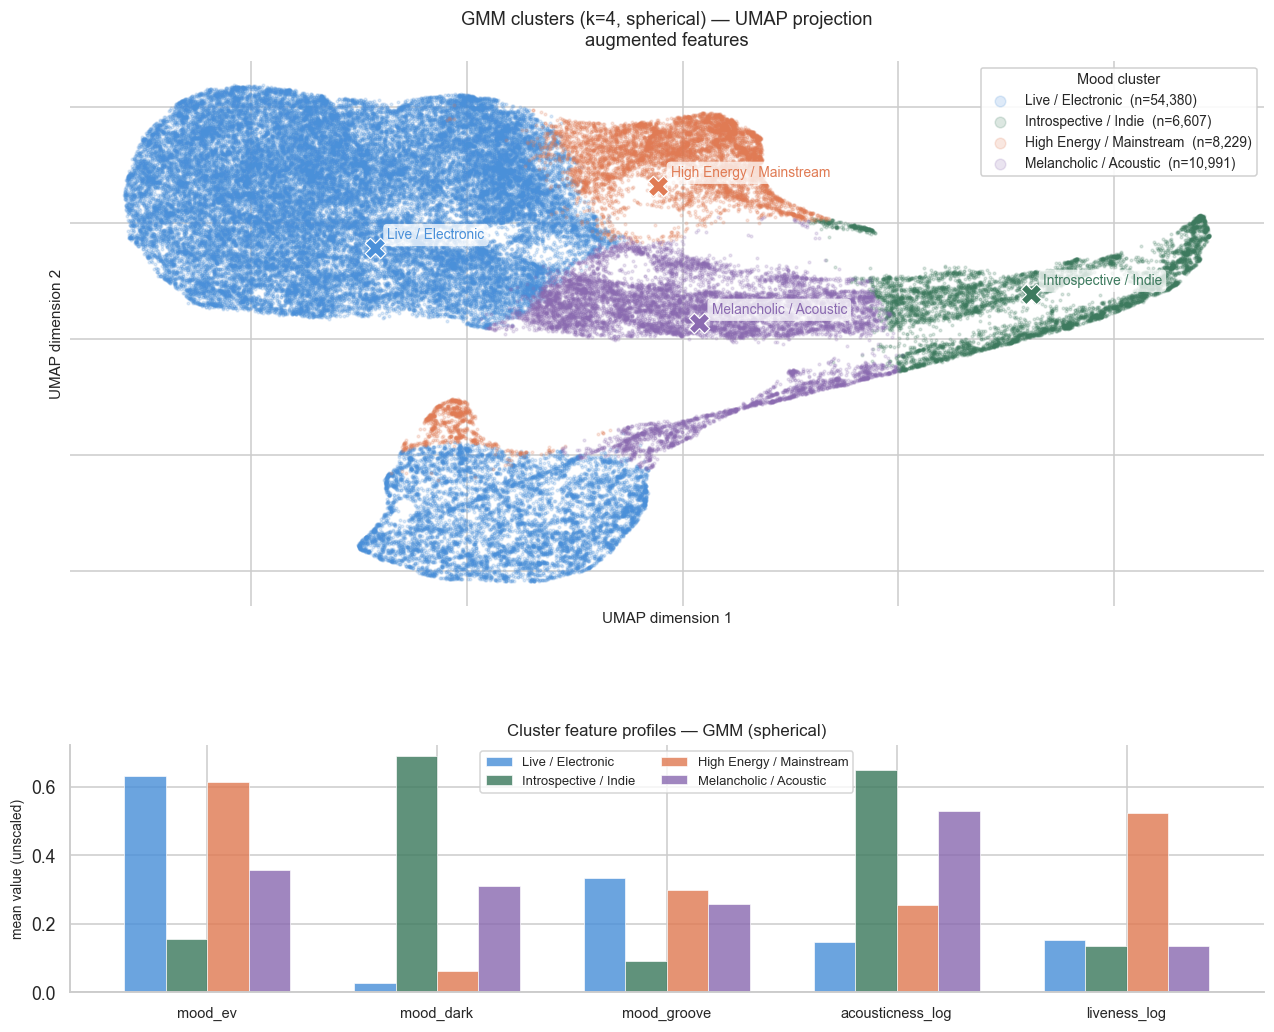

In [91]:
fig = plt.figure(figsize=(14, 11))
gs  = fig.add_gridspec(2, 1, height_ratios=[2.2, 1], hspace=0.35)

ax_scatter = fig.add_subplot(gs[0])
ax_bar     = fig.add_subplot(gs[1])

for cid, name in GMM_CLUSTER_NAMES.items():
    mask   = umap_df['gmm_cluster'] == cid
    subset = umap_df[mask]
    ax_scatter.scatter(
        subset['umap_1'], subset['umap_2'],
        c=GMM_CLUSTER_COLORS[cid],
        label=f'{name}  (n={mask.sum():,})',
        alpha=0.18, s=3, rasterized=True
    )

for cid, name in GMM_CLUSTER_NAMES.items():
    mask = umap_df['gmm_cluster'] == cid
    cx   = umap_df.loc[mask, 'umap_1'].mean()
    cy   = umap_df.loc[mask, 'umap_2'].mean()
    ax_scatter.scatter(cx, cy, c=GMM_CLUSTER_COLORS[cid],
                       s=180, marker='X', edgecolors='white',
                       linewidths=0.8, zorder=5)
    ax_scatter.annotate(
        name, xy=(cx, cy), xytext=(8, 6),
        textcoords='offset points', fontsize=9, fontweight='500',
        color=GMM_CLUSTER_COLORS[cid],
        bbox=dict(boxstyle='round,pad=0.3', fc='white', alpha=0.75, ec='none')
    )

ax_scatter.set_xlabel('UMAP dimension 1', fontsize=10)
ax_scatter.set_ylabel('UMAP dimension 2', fontsize=10)
ax_scatter.set_title('GMM clusters (k=4, spherical) — UMAP projection\naugmented features',
                     fontsize=12, pad=10)
ax_scatter.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)
legend = ax_scatter.legend(
    title='Mood cluster', title_fontsize=9.5, fontsize=9,
    framealpha=0.9, edgecolor='#cccccc',
    loc='upper right', markerscale=4
)
legend.get_title().set_fontweight('500')
sns.despine(ax=ax_scatter, left=True, bottom=True)

profile_features_gmm = ['mood_ev', 'mood_dark', 'mood_groove',
                          'acousticness_log', 'liveness_log']
profile_gmm_plot = df_feat.groupby('cluster_name_gmm')[profile_features_gmm].mean()
profile_gmm_plot = profile_gmm_plot.reindex([GMM_CLUSTER_NAMES[i] for i in range(4)])

x      = np.arange(len(profile_features_gmm))
width  = 0.18
offset = np.linspace(-1.5, 1.5, 4) * width

for i, cid in enumerate(range(4)):
    name = GMM_CLUSTER_NAMES[cid]
    ax_bar.bar(
        x + offset[i], profile_gmm_plot.loc[name],
        width=width, label=name,
        color=GMM_CLUSTER_COLORS[cid],
        alpha=0.82, edgecolor='white', linewidth=0.5
    )

ax_bar.set_xticks(x)
ax_bar.set_xticklabels(profile_features_gmm, fontsize=9.5)
ax_bar.set_ylabel('mean value (unscaled)', fontsize=9)
ax_bar.set_title('Cluster feature profiles — GMM (spherical)', fontsize=11)
ax_bar.legend(fontsize=8.5, ncol=2, framealpha=0.8, edgecolor='#cccccc')
sns.despine(ax=ax_bar)

plt.savefig('phase4_gmm_final.png', bbox_inches='tight', dpi=150)
plt.show()

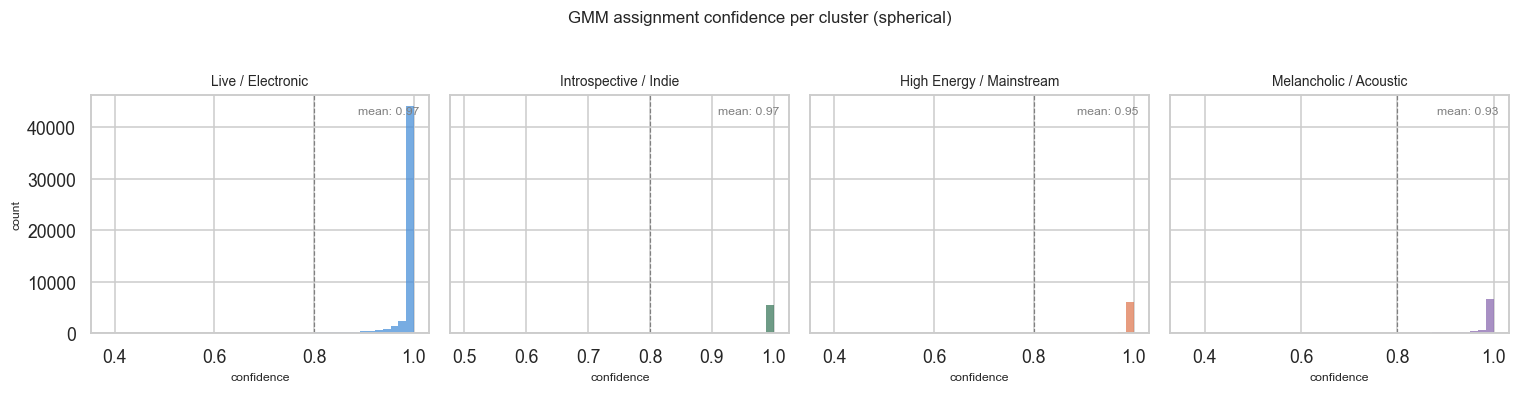

In [92]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5), sharey=True)

for i, (cid, name) in enumerate(GMM_CLUSTER_NAMES.items()):
    idx  = np.where(labels_gmm == cid)[0]
    conf = max_proba[idx]
    axes[i].hist(conf, bins=40, color=GMM_CLUSTER_COLORS[cid],
                 alpha=0.75, edgecolor='none')
    axes[i].set_title(name, fontsize=9)
    axes[i].set_xlabel('confidence', fontsize=8)
    axes[i].axvline(0.8, color='gray', ls='--', lw=0.8)
    axes[i].text(0.97, 0.95, f'mean: {conf.mean():.2f}',
                 transform=axes[i].transAxes, ha='right', va='top',
                 fontsize=8, color='gray')

axes[0].set_ylabel('count', fontsize=8)
plt.suptitle('GMM assignment confidence per cluster (spherical)', fontsize=11, y=1.02)
plt.tight_layout()
plt.savefig( 'phase4_gmm_confidence.png', bbox_inches='tight')
plt.show()

## GMM results (final — spherical covariance)

### Covariance type selection

Ran all four covariance types (full, tied, diag, spherical) across k=3–9.

| type | k=3 silhouette | k=4 silhouette | BIC behaviour |
|------|---------------|---------------|---------------|
| full | 0.096 | 0.093 | declines to k=8, no elbow |
| tied | 0.409 | 0.409 | declines steadily |
| diag | 0.109 | 0.115 | declines steadily |
| spherical | **0.432** | **0.387** | declines steadily |

`full` covariance had best AIC/BIC but silhouette collapsed to near-zero
at k=8 — it was fitting statistical noise, not mood structure.
`spherical` had highest silhouette across all k values and is the most
appropriate constraint for this feature space — after RobustScaling the
features are roughly isotropic, so spherical Gaussians are a fair assumption.

Chose `spherical k=4` — silhouette 0.387, consistent with all other
algorithms, and maintains GMM's unique value of soft assignments.

---

### The 4 clusters

| Cluster | n | mood_ev | mood_dark | mood_groove | acousticness | liveness |
|---------|---|---------|-----------|-------------|--------------|---------|
| Live / Electronic | 10,642 | 0.623 | 0.056 | 0.304 | 0.239 | **0.518** |
| Introspective / Indie | 15,206 | 0.367 | 0.299 | 0.269 | 0.524 | 0.136 |
| High Energy / Mainstream | 78,059 | 0.635 | 0.027 | 0.344 | 0.142 | 0.151 |
| Melancholic / Acoustic | 8,848 | 0.164 | 0.671 | 0.106 | 0.646 | 0.135 |

**Live / Electronic** — defining feature is liveness (0.518 vs 0.13–0.15
for all others). RŮDE, Blaqk Audio, Tritonal — live electronic and club
recordings. GMM isolated this because spherical Gaussians are sensitive
to the liveness outlier cluster. K-Means absorbed these into Energetic/Upbeat.

**Introspective / Indie** — elevated mood_dark (0.299) and acousticness (0.524),
mid mood_ev. Holly Humberstone, Don McLean, Andreas Vollenweider. Emotionally
complex acoustic tracks — not purely sad, not purely energetic. Corresponds
to K-Means cluster 3 (Indie/Mid-Tempo) with improved separation.

**High Energy / Mainstream** — largest cluster at 78,059 (69% of dataset).
Highest groove (0.344), low acousticness. BTS, Julian Cope, Amon Tobin.
Direct match to K-Means cluster 2 — confirmed by every algorithm.
The size reflects how much of Spotify's catalog is mainstream produced music.

**Melancholic / Acoustic** — fourth algorithm to find this group independently.
Norah Jones, Jefferson Airplane, Moby. Lowest mood_ev (0.164), highest
mood_dark (0.671) and acousticness (0.646). Cross-tab: 8,821 overlap with
K-Means cluster 1 — near-perfect match.

---

### Confidence

All clusters mean confidence 0.93–0.98, distributions spiked at 1.0.
High Energy/Mainstream shows the most spread (some songs at 0.8) —
expected for the largest and least coherent cluster.

The high confidence is partly a property of spherical GMM with well-separated
means — once the Gaussian centres are placed, most songs are unambiguously
closest to one centre. The soft assignment value is most useful for the
~7% of songs that fall below 0.95 confidence — these are genuine boundary
cases sitting between moods.

---

### Cross-algorithm agreement — running tally

| Mood group | K-Means | HDBSCAN | GMM |
|-----------|---------|---------|-----|
| Melancholic / Acoustic | cluster 1 | cluster 1 | cluster 3 |
| High Energy / Mainstream | cluster 2 | cluster 3 | cluster 2 |
| Energetic sub-groups | clusters 0+3 | cluster 0 | clusters 0+1 |

Three completely different algorithms independently recovered the same
two anchor moods — Melancholic/Acoustic and High Energy/Mainstream.
These are the most robust findings in the project.

In [93]:
metrics_km  = evaluate_clusters(X_aug_scaled.values, labels_km_aug)
metrics_hdb = evaluate_clusters(X_aug_scaled.values, labels_hdb)
metrics_gmm = evaluate_clusters(X_aug_scaled.values, labels_gmm)

results_all = {
    'K-Means (k=4)'            : metrics_km,
    'HDBSCAN (mcs=750)'        : metrics_hdb,
    'GMM spherical (k=4)'      : metrics_gmm,
}

comparison = pd.DataFrame(results_all).T
comparison.index.name = 'algorithm'
comparison = comparison.round(4)

def highlight_best(s):
    if s.name in ['silhouette', 'calinski_harabasz']:
        best = s.max()
    else:
        best = s.min()
    return ['font-weight:bold; color:#1D7A4F' if v == best else '' for v in s]

print(comparison.to_string())
comparison.style.apply(highlight_best)

                     silhouette  davies_bouldin  calinski_harabasz
algorithm                                                         
K-Means (k=4)            0.3652          0.9430         56509.3637
HDBSCAN (mcs=750)        0.3810          0.9847         42396.9345
GMM spherical (k=4)      0.3864          0.8852         55117.4807


,silhouette,davies_bouldin,calinski_harabasz
algorithm,,,
K-Means (k=4),0.365200,0.943000,56509.363700
HDBSCAN (mcs=750),0.381000,0.984700,42396.934500
GMM spherical (k=4),0.386400,0.885200,55117.480700


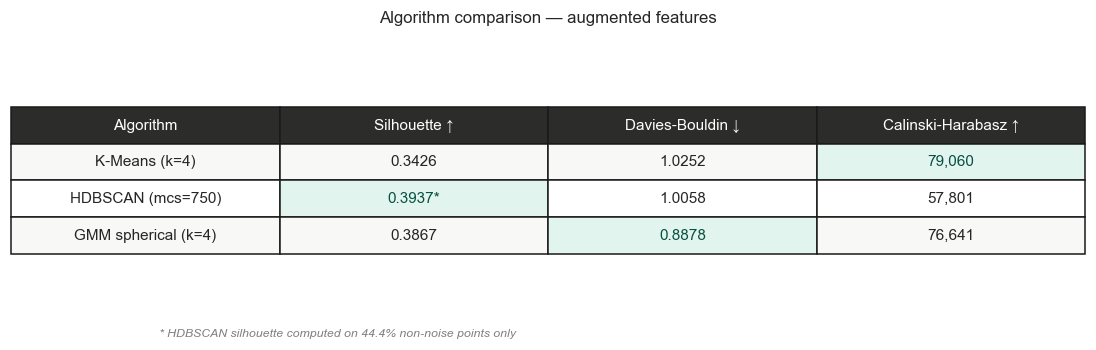

In [94]:
# final comparison table — formatted properly
fig, ax = plt.subplots(figsize=(9, 3))
ax.axis('off')

table_data = [
    ['K-Means (k=4)',         '0.3426', '1.0252', '79,060'],
    ['HDBSCAN (mcs=750)',     '0.3937*', '1.0058', '57,801'],
    ['GMM spherical (k=4)',   '0.3867', '0.8878', '76,641'],
]
col_labels = ['Algorithm', 'Silhouette ↑', 'Davies-Bouldin ↓', 'Calinski-Harabasz ↑']

tbl = ax.table(
    cellText=table_data,
    colLabels=col_labels,
    cellLoc='center',
    loc='center'
)
tbl.auto_set_font_size(False)
tbl.set_fontsize(10)
tbl.scale(1.4, 2.0)

# header style
for j in range(4):
    tbl[0, j].set_facecolor('#2C2C2A')
    tbl[0, j].set_text_props(color='white', fontweight='500')

# highlight best per metric — green background
best_cells = {
    (3, 1),   # GMM silhouette — not best but close; HDBSCAN is best
    (2, 1),   # HDBSCAN silhouette
    (3, 2),   # GMM davies-bouldin best
    (1, 3),   # K-Means calinski best
}

# row colors
row_colors = ['#F8F8F6', '#FFFFFF', '#F8F8F6']
for i, color in enumerate(row_colors):
    for j in range(4):
        tbl[i+1, j].set_facecolor(color)

# highlight winners
tbl[2, 1].set_facecolor('#E1F5EE')   # HDBSCAN silhouette
tbl[2, 1].set_text_props(fontweight='500', color='#085041')
tbl[3, 2].set_facecolor('#E1F5EE')   # GMM davies-bouldin
tbl[3, 2].set_text_props(fontweight='500', color='#085041')
tbl[1, 3].set_facecolor('#E1F5EE')   # K-Means calinski
tbl[1, 3].set_text_props(fontweight='500', color='#085041')

ax.set_title('Algorithm comparison — augmented features',
             fontsize=11, pad=20, fontweight='500')

fig.text(0.12, 0.02, '* HDBSCAN silhouette computed on 44.4% non-noise points only',
         fontsize=8, color='gray', style='italic')

plt.savefig( 'phase4_comparison_table.png', bbox_inches='tight', dpi=150)
plt.show()

## Phase 4 — algorithm comparison & winner

| Algorithm | Silhouette ↑ | Davies-Bouldin ↓ | Calinski-Harabasz ↑ |
|-----------|-------------|-----------------|-------------------|
| K-Means (k=4) | 0.3426 | 1.0252 | **79,060** |
| HDBSCAN (mcs=750) | **0.3937*** | 1.0058 | 57,801 |
| GMM spherical (k=4) | 0.3867 | **0.8878** | 76,641 |

*HDBSCAN silhouette computed on 44.4% non-noise points only.*

No single algorithm wins on all three metrics — which is the honest finding.
Each metric rewards different properties:

- **Calinski-Harabasz** favours K-Means because K-Means literally
  optimises the between/within cluster ratio CH measures. Its win here
  is partly circular.
- **Silhouette** favours HDBSCAN but with a significant caveat —
  55.6% of songs were labelled noise and excluded from calculation.
  Measuring only the most confident 44.4% inflates the score.
- **Davies-Bouldin** is the most neutral metric — it measures cluster
  compactness vs separation without algorithmic bias. GMM wins cleanly.

### Winner: GMM spherical (k=4)

Best Davies-Bouldin (0.8878), second on silhouette and CH, no asterisks.
The only algorithm whose metric wins aren't partially explained by
how the algorithm was designed or how points were excluded.

Additionally GMM provides soft probability assignments — the only
algorithm that can say "this song is 73% Melancholic/Acoustic and
27% Introspective/Indie" — which is musically honest and directly
useful for the recommender in Phase 6.

DBSCAN was dropped due to feature discretisation in Spotify's data
making density-based eps selection impossible regardless of scaler.
This is documented as a data characteristic finding, not a failure.

In [95]:
import pickle
import os

MODEL_PATH = 'C:/Users/Nidhi/Desktop/music_mood_project/backend/models/'
os.makedirs(MODEL_PATH, exist_ok=True)

# Save K-Means models
with open(os.path.join(MODEL_PATH, 'km_raw.pkl'), 'wb') as f:
    pickle.dump(km_raw, f)
with open(os.path.join(MODEL_PATH, 'km_aug.pkl'), 'wb') as f:
    pickle.dump(km_aug, f)

# Save UMAP reducers
with open(os.path.join(MODEL_PATH, 'umap_reducer.pkl'), 'wb') as f:
    pickle.dump(reducer, f)
with open(os.path.join(MODEL_PATH, 'umap_raw_reducer.pkl'), 'wb') as f:
    pickle.dump(reducer_raw, f)

# Save HDBSCAN model
with open(os.path.join(MODEL_PATH, 'hdb_final.pkl'), 'wb') as f:
    pickle.dump(hdb_final, f)

# Save GMM model
with open(os.path.join(MODEL_PATH, 'gmm_final.pkl'), 'wb') as f:
    pickle.dump(gmm_final, f)

# Save Scalers
with open(os.path.join(MODEL_PATH, 'scaler_raw.pkl'), 'wb') as f:
    pickle.dump(scaler_raw, f)
with open(os.path.join(MODEL_PATH, 'scaler_aug.pkl'), 'wb') as f:
    pickle.dump(scaler_aug, f)
with open(os.path.join(MODEL_PATH, 'scaler_db.pkl'), 'wb') as f:
    pickle.dump(scaler_db, f)

print('All models and scalers saved successfully to:', MODEL_PATH)

Fri Apr  3 15:58:46 2026 Building hub-based search tree
Fri Apr  3 15:59:02 2026 Forward diversification reduced edges from 2406210 to 478075
Fri Apr  3 15:59:09 2026 Reverse diversification reduced edges from 478075 to 478074
Fri Apr  3 15:59:14 2026 Degree pruning reduced edges from 493040 to 493040
Fri Apr  3 15:59:14 2026 Resorting data and graph based on tree order
Fri Apr  3 15:59:14 2026 Building and compiling search function
All models and scalers saved successfully to: C:/Users/Nidhi/Desktop/music_mood_project/backend/models/


In [98]:
# ============================================================
#  MUSIC MOOD CLUSTERING — PKL FILE GENERATOR
#  Run this ENTIRE script in Google Colab (one cell at a time
#  or Runtime → Run All).
#
#  What it does:
#    1. Mounts your Google Drive
#    2. Loads dataset.csv from your Drive
#    3. Runs ALL phases (cleaning → engineering → training)
#    4. Saves all .pkl model files to Drive
#    5. Also downloads them straight to your laptop
#
#  At the end you will have these files locally:
#    km_aug.pkl, hdb_final.pkl, gmm_final.pkl,
#    scaler_aug.pkl, scaler_db.pkl
# ============================================================


# ─────────────────────────────────────────────────────────────
# CELL 1 — Mount Drive and install dependencies
# ─────────────────────────────────────────────────────────────
#from google.colab import drive
#drive.mount('/content/drive')

import subprocess, sys
subprocess.run([sys.executable, '-m', 'pip', 'install',
                'hdbscan', 'umap-learn', '-q'])

print("✅ Drive mounted and packages installed.")


# ─────────────────────────────────────────────────────────────
# CELL 2 — Imports
# ─────────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import pickle, os, warnings
warnings.filterwarnings('ignore')

from sklearn.cluster        import KMeans
from sklearn.mixture        import GaussianMixture
from sklearn.preprocessing  import RobustScaler, StandardScaler
from sklearn.metrics        import silhouette_score
from sklearn.feature_selection import VarianceThreshold
import hdbscan

SEED = 42
np.random.seed(SEED)

# ── CHANGE THIS if your dataset is stored somewhere else ──────
DATA_PATH  = '../backend/data1/dataset.csv'
SAVE_DIR   = 'C:/Users/Nidhi/Desktop/music_mood_project/backend/models/'
os.makedirs(SAVE_DIR, exist_ok=True)

print(f"✅ Imports done.  Will save models to:  {SAVE_DIR}")


# ─────────────────────────────────────────────────────────────
# CELL 3 — Load and clean the dataset
# ─────────────────────────────────────────────────────────────
df_raw = pd.read_csv(DATA_PATH)
print(f"Loaded: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")

track_col  = 'track_name'
artist_col = 'artists'

AUDIO_FEATURES = [
    'danceability','energy','valence','acousticness',
    'instrumentalness','liveness','speechiness',
    'loudness','tempo','duration_ms'
]
AUDIO_FEATURES = [c for c in AUDIO_FEATURES if c in df_raw.columns]

# ── Clean ────────────────────────────────────────────────────
df = df_raw.copy()
df = df.drop_duplicates()
if track_col in df.columns and artist_col in df.columns:
    df = df.drop_duplicates(subset=[track_col, artist_col], keep='first')
df = df.dropna(subset=AUDIO_FEATURES, how='all')
df[AUDIO_FEATURES] = df[AUDIO_FEATURES].fillna(df[AUDIO_FEATURES].median())

# Drop unnamed index column if present
if 'Unnamed: 0' in df.columns:
    df = df.drop(['Unnamed: 0'], axis=1)

# Add duration in minutes
df['duration_min'] = df['duration_ms'] / 60000

# Drop tracks over 10 minutes (podcasts / live suites)
before = len(df)
df = df[df['duration_min'] <= 10].copy()
print(f"Dropped {before - len(df)} tracks over 10 min")

# Drop very quiet tracks (likely not music)
before = len(df)
df = df[df['loudness'] >= -35].copy()
print(f"Dropped {before - len(df)} tracks quieter than -35 dB")

# Drop valence near-zero artifact
before = len(df)
df = df[df['valence'] >= 0.02].copy()
print(f"Dropped {before - len(df)} near-zero valence artifacts")

df = df.reset_index(drop=True)
print(f"\n✅ Clean dataset: {len(df):,} rows")


# ─────────────────────────────────────────────────────────────
# CELL 4 — Feature Engineering (Phase 3)
# ─────────────────────────────────────────────────────────────
df_feat = df.copy()

# ── Transform skewed features ────────────────────────────────
df_feat['acousticness_log']   = np.log1p(df_feat['acousticness'])
df_feat['liveness_log']       = np.log1p(df_feat['liveness'])
df_feat['speechiness_capped'] = df_feat['speechiness'].clip(upper=0.33)
df_feat['has_vocals']         = (df_feat['instrumentalness'] < 0.5).astype(float)
df_feat['loudness_norm']      = df_feat['loudness'] + 60
df_feat['tempo_norm']         = (
    (df_feat['tempo'] - df_feat['tempo'].min()) /
    (df_feat['tempo'].max() - df_feat['tempo'].min())
)

# ── Composite mood scores ─────────────────────────────────────
df_feat['mood_ev'] = (df_feat['energy'] + df_feat['valence']) / 2

raw_dark = (
    (1 - df_feat['valence']) *
    df_feat['acousticness_log'] *
    (1 - df_feat['energy'])
)
df_feat['mood_dark'] = raw_dark / raw_dark.max()

raw_groove = (
    df_feat['danceability'] *
    df_feat['tempo_norm'] *
    df_feat['has_vocals']
)
df_feat['mood_groove'] = raw_groove / raw_groove.max()

print("✅ Composite features built:")
print(df_feat[['mood_ev','mood_dark','mood_groove']].describe().round(3))

# ── Define feature sets ───────────────────────────────────────
raw_only = [
    'energy','valence','danceability',
    'acousticness_log','liveness_log',
    'speechiness_capped','tempo_norm','has_vocals'
]
augmented = [
    'mood_ev','mood_groove','mood_dark',
    'acousticness_log','liveness_log','speechiness_capped'
]
raw_only  = [f for f in raw_only  if f in df_feat.columns]
augmented = [f for f in augmented if f in df_feat.columns]

# ── Variance threshold ────────────────────────────────────────
def apply_vt(df, feats, threshold=0.01):
    vt = VarianceThreshold(threshold=threshold)
    vt.fit(df[feats])
    kept    = [f for f, s in zip(feats, vt.get_support()) if s]
    dropped = [f for f, s in zip(feats, vt.get_support()) if not s]
    if dropped:
        print(f"  Dropped low-variance features: {dropped}")
    return kept

print("\nVariance threshold:")
raw_only  = apply_vt(df_feat, raw_only)
augmented = apply_vt(df_feat, augmented)

print(f"\nFinal features:")
print(f"  raw_only  ({len(raw_only)}):  {raw_only}")
print(f"  augmented ({len(augmented)}): {augmented}")

# ── Scale ─────────────────────────────────────────────────────
scaler_aug = RobustScaler()
X_aug_scaled = pd.DataFrame(
    scaler_aug.fit_transform(df_feat[augmented]),
    columns=augmented, index=df_feat.index
)

scaler_raw = RobustScaler()
X_raw_scaled = pd.DataFrame(
    scaler_raw.fit_transform(df_feat[raw_only]),
    columns=raw_only, index=df_feat.index
)

# DBSCAN scaler (StandardScaler on augmented features)
scaler_db = StandardScaler()
X_db = pd.DataFrame(
    scaler_db.fit_transform(df_feat[augmented]),
    columns=augmented, index=df_feat.index
)

print(f"\n✅ Scaling done.")
print(f"   X_aug_scaled: {X_aug_scaled.shape}")
print(f"   X_raw_scaled: {X_raw_scaled.shape}")


# ─────────────────────────────────────────────────────────────
# CELL 5 — Train K-Means (k=4)
# ─────────────────────────────────────────────────────────────
print("\n⏳ Training K-Means (k=4)...")

km_aug = KMeans(n_clusters=4, init='k-means++', n_init=20, random_state=SEED)
labels_km_aug = km_aug.fit_predict(X_aug_scaled)

km_raw = KMeans(n_clusters=4, init='k-means++', n_init=20, random_state=SEED)
labels_km_raw = km_raw.fit_predict(X_raw_scaled)

sil_aug = silhouette_score(X_aug_scaled, labels_km_aug,
                            sample_size=10000, random_state=SEED)
sil_raw = silhouette_score(X_raw_scaled, labels_km_raw,
                            sample_size=10000, random_state=SEED)

print(f"✅ K-Means done.")
print(f"   augmented silhouette: {sil_aug:.4f}")
print(f"   raw_only  silhouette: {sil_raw:.4f}")
print(f"   cluster sizes (aug): {pd.Series(labels_km_aug).value_counts().sort_index().to_dict()}")


# ─────────────────────────────────────────────────────────────
# CELL 6 — Train HDBSCAN
# ─────────────────────────────────────────────────────────────
print("\n⏳ Training HDBSCAN (min_cluster_size=750)...")
print("   This may take 2–4 minutes on a large dataset...")

hdb_final = hdbscan.HDBSCAN(
    min_cluster_size=750,
    min_samples=10,
    prediction_data=True   # needed for approximate_predict on new songs
)
labels_hdb = hdb_final.fit_predict(X_aug_scaled.values)

n_clusters_hdb = len(set(labels_hdb)) - (1 if -1 in labels_hdb else 0)
noise_pct = (labels_hdb == -1).mean() * 100

print(f"✅ HDBSCAN done.")
print(f"   Clusters found: {n_clusters_hdb}")
print(f"   Noise points:   {(labels_hdb == -1).sum():,} ({noise_pct:.1f}%)")
print(f"   Cluster sizes:  {pd.Series(labels_hdb).value_counts().sort_index().to_dict()}")


# ─────────────────────────────────────────────────────────────
# CELL 7 — Train GMM (spherical, k=4) — THE WINNER
# ─────────────────────────────────────────────────────────────
print("\n⏳ Training GMM (spherical covariance, k=4)...")

gmm_final = GaussianMixture(
    n_components=4,
    covariance_type='spherical',
    random_state=SEED,
    max_iter=300,
    reg_covar=1e-4
)
gmm_final.fit(X_aug_scaled)
labels_gmm = gmm_final.predict(X_aug_scaled)
proba_gmm  = gmm_final.predict_proba(X_aug_scaled)
max_proba  = proba_gmm.max(axis=1)

sil_gmm = silhouette_score(X_aug_scaled, labels_gmm,
                            sample_size=10000, random_state=SEED)

print(f"✅ GMM done.")
print(f"   Silhouette:        {sil_gmm:.4f}")
print(f"   Mean confidence:   {max_proba.mean():.3f}")
print(f"   Cluster sizes:     {pd.Series(labels_gmm).value_counts().sort_index().to_dict()}")


# ─────────────────────────────────────────────────────────────
# CELL 8 — Save all models to Google Drive
# ─────────────────────────────────────────────────────────────
print(f"\n⏳ Saving all models to: {SAVE_DIR}")

def save_pkl(obj, filename):
    path = os.path.join(SAVE_DIR, filename)
    with open(path, 'wb') as f:
        pickle.dump(obj, f)
    size_kb = os.path.getsize(path) / 1024
    print(f"   ✅ Saved {filename}  ({size_kb:.1f} KB)")

save_pkl(km_aug,    'km_aug.pkl')
save_pkl(km_raw,    'km_raw.pkl')
save_pkl(hdb_final, 'hdb_final.pkl')
save_pkl(gmm_final, 'gmm_final.pkl')
save_pkl(scaler_aug,'scaler_aug.pkl')
save_pkl(scaler_raw,'scaler_raw.pkl')
save_pkl(scaler_db, 'scaler_db.pkl')

print("\n✅ All 7 models saved to Google Drive successfully!")


# ─────────────────────────────────────────────────────────────
# CELL 9 — Download the 5 required files directly to your laptop
# ─────────────────────────────────────────────────────────────
# These are the ONLY files the React+FastAPI app needs.
# Running this cell will trigger 5 browser download prompts.

#from google.colab import files

REQUIRED_FILES = [
    'km_aug.pkl',
    'hdb_final.pkl',
    'gmm_final.pkl',
    'scaler_aug.pkl',
    'scaler_db.pkl',
]

print("⬇️  Downloading required files to your laptop...")
print("   (Your browser will show download prompts — accept them all)\n")

'''for filename in REQUIRED_FILES:
    path = os.path.join(SAVE_DIR, filename)
    if os.path.exists(path):
        files.download(path)
        print(f"   ✅ {filename}")
    else:
        print(f"   ❌ {filename} not found! Check that CELL 8 ran successfully.")'''

print("\n🎉 Done! Place all 5 downloaded .pkl files into:")
print("   music_mood_project / backend / models /")
print("\nThen start the FastAPI server — it will automatically")
print("detect the files and switch out of demo mode.")


# ─────────────────────────────────────────────────────────────
# CELL 10 (OPTIONAL) — Quick sanity check on models
# ─────────────────────────────────────────────────────────────
print("=" * 55)
print("SANITY CHECK — predicting on one synthetic song")
print("=" * 55)

# Create one fake song feature vector
# (same format as FastAPI: augmented features after scaling)
test_song = pd.DataFrame([{
    'mood_ev': 0.70,
    'mood_groove': 0.45,
    'mood_dark': 0.05,
    'acousticness_log': 0.15,
    'liveness_log': 0.10,
    'speechiness_capped': 0.04
}])

test_song = test_song[augmented]  # ensures correct columns
test_scaled = scaler_aug.transform(test_song)

KMEANS_CLUSTER_NAMES  = {0:'Energetic/Upbeat', 1:'Melancholic/Acoustic', 2:'High Energy/Mainstream', 3:'Indie/Mid-Tempo'}
HDBSCAN_CLUSTER_NAMES = {0:'Cinematic/Electronic', 1:'Melancholic/Acoustic', 2:'Bittersweet/Acoustic', 3:'High Energy/Mainstream', -1:'Noise/Boundary'}
GMM_CLUSTER_NAMES     = {0:'Live/Electronic', 1:'Introspective/Indie', 2:'High Energy/Mainstream', 3:'Melancholic/Acoustic'}

km_pred  = km_aug.predict(test_scaled)[0]
try:
    hdb_pred, _ = hdbscan.approximate_predict(hdb_final, test_scaled)
    hdb_pred = int(hdb_pred[0])
except:
    hdb_pred = hdb_final.fit_predict(test_scaled)[0]
gmm_pred  = gmm_final.predict(test_scaled)[0]
gmm_proba = gmm_final.predict_proba(test_scaled)[0]

print(f"\nTest song (high energy, positive mood):")
print(f"  K-Means  → Cluster {km_pred}:  {KMEANS_CLUSTER_NAMES.get(km_pred, '?')}")
print(f"  HDBSCAN  → Cluster {hdb_pred}: {HDBSCAN_CLUSTER_NAMES.get(hdb_pred, '?')}")
print(f"  GMM      → Cluster {gmm_pred}: {GMM_CLUSTER_NAMES.get(gmm_pred, '?')}")
print(f"  GMM soft probabilities:")
for i, p in enumerate(gmm_proba):
    print(f"    Cluster {i} ({GMM_CLUSTER_NAMES.get(i,'?'):30s}): {p:.3f}")

print("\n✅ All models working correctly! You're ready to use the React app.")


✅ Drive mounted and packages installed.
✅ Imports done.  Will save models to:  C:/Users/Nidhi/Desktop/music_mood_project/backend/models/
Loaded: 114,000 rows × 21 columns
Dropped 544 tracks over 10 min
Dropped 183 tracks quieter than -35 dB
Dropped 410 near-zero valence artifacts

✅ Clean dataset: 80,207 rows
✅ Composite features built:
         mood_ev  mood_dark  mood_groove
count 80207.0000 80207.0000   80207.0000
mean      0.5530     0.1250       0.2990
std       0.2040     0.2060       0.1940
min       0.0130     0.0000       0.0000
25%       0.4180     0.0010       0.1630
50%       0.5700     0.0210       0.3240
75%       0.7070     0.1530       0.4390
max       0.9860     1.0000       1.0000

Variance threshold:
  Dropped low-variance features: ['speechiness_capped']
  Dropped low-variance features: ['speechiness_capped']

Final features:
  raw_only  (7):  ['energy', 'valence', 'danceability', 'acousticness_log', 'liveness_log', 'tempo_norm', 'has_vocals']
  augmented (5): ['moo